# DSC 180A — Quarter 1 Project
## Part 1 — Genome-Wide cis-eQTL Analysis

**Goal:** find **cis-eQTLs**, SNPs near a gene that are associated with that gene's expression,
across protein-coding genes on all 22 autosomes. We use 1000 Genomes genotypes and
lymphoblastoid cell line (LCL) expression data.

This extends the Week 4 chromosome 1 pipeline with the same regression, now in `src/eqtl.py`. Three things change:

| | Week 4 | Part 1 |
|---|---|---|
| Genes | All expressed gene types | **Protein-coding only** |
| Chromosomes | Chromosome 1 | **Chromosomes 1–22** |
| Multiple-testing family | Pairs on chromosome 1 | **All tested pairs genome-wide** |

The regression, the ±500 kb window, and the sample matching are unchanged. Like Week 4, the
model has no covariates and no MAF or Hardy–Weinberg filter.

In [1]:
from pathlib import Path
import gzip
import os
import sys
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Paths below are relative to the repository root.
if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, '.')
from src.eqtl import add_multiple_testing_columns, map_chromosome, summarize_genes

part1 = Path('data/quarter1_results/part1')
(part1 / 'chromosomes').mkdir(parents=True, exist_ok=True)
figures = Path('results/part1/figures')
figures.mkdir(parents=True, exist_ok=True)
expression_path = 'data/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt'
chromosomes = list(range(1, 23))

# Set to True to redo the PLINK exports and regressions instead of reusing saved chromosome files.
REBUILD = False

# People with both genotypes and expression, in genotype-file order.
panel_fam = pd.read_csv('data/LDREF/1000G.EUR.1.fam', sep=r'\s+', header=None, dtype=str, usecols=[0, 1], names=['FID', 'IID'])
expression_people = set(pd.read_csv(expression_path, sep='\t', nrows=0).columns[4:])
samples = panel_fam.loc[panel_fam['IID'].isin(expression_people)].reset_index(drop=True)
ids = samples['IID'].tolist()
column = dict(zip(ids, samples['FID'] + '_' + samples['IID']))
samples[['FID', 'IID']].to_csv(part1 / 'matched.keep', sep='\t', index=False, header=False)

expression = pd.read_csv(expression_path, sep='\t', usecols=['TargetID', 'Chr', 'Coord', *ids],
                         dtype={'Chr': str}).set_index('TargetID')
assert expression.index.is_unique and samples['IID'].is_unique
print('Matched individuals:', len(ids), '| Genes in the expression file:', len(expression))
print('Expression value range:', expression[ids].min().min(), 'to', expression[ids].max().max())

Matched individuals: 344 | Genes in the expression file: 23722
Expression value range: -3465.21712524185 to 75846.5331983623


### Step 1: Prepare the Protein-Coding Gene Dataset

The people and genotypes come from the 1000 Genomes European panel, and the expression file gives their
measured genes. Neither records whether a gene is protein-coding, so we look that up in a gene annotation.

We need gene types and GRCh37 coordinates for every chromosome. Week 4 saved only chromosome 1,
so we download the full **GENCODE v12** annotation, the same release used in Weeks 3–4
(its header says GRCh37). The local `gene_annot.txt.gz` uses GRCh38 coordinates, so it
is not used here.

A gene counts as protein-coding if its GENCODE `gene_type` is `protein_coding`. We match
expression rows by the exact versioned gene ID, such as `ENSG00000116288.8`.

In [2]:
gtf_path = part1 / 'gencode.v12.annotation.gtf.gz'
if not gtf_path.exists():
    urllib.request.urlretrieve('https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_12/gencode.v12.annotation.gtf.gz', gtf_path)

with gzip.open(gtf_path, 'rt') as handle:
    print(handle.readline().strip())

gtf = pd.read_csv(gtf_path, sep='\t', comment='#', header=None, usecols=[0, 2, 3, 4, 8])
gtf = gtf.loc[gtf[2].eq('gene')]
annotation = pd.DataFrame({
    'Gene_ID': gtf[8].str.extract(r'gene_id "([^"]+)"')[0],
    'Gene_Symbol': gtf[8].str.extract(r'gene_name "([^"]+)"')[0],
    'Gene_Type': gtf[8].str.extract(r'gene_type "([^"]+)"')[0],
    'Gene_Chr': gtf[0].str.replace('chr', '', regex=False),
    'Gene_Start': gtf[3], 'Gene_End': gtf[4],
}).set_index('Gene_ID')
assert annotation.index.is_unique

genes = annotation.loc[annotation['Gene_Type'].eq('protein_coding')].drop(columns='Gene_Type')
genes['Cis_Start'] = (genes['Gene_Start'] - 500000).clip(lower=1)
genes['Cis_End'] = genes['Gene_End'] + 500000

expressed = genes.index.isin(expression.index)
autosomal = genes['Gene_Chr'].isin([str(c) for c in chromosomes])
measured = expression.reindex(genes.index)
values = measured[ids].to_numpy(float)

genes['Reason'] = 'Eligible'
genes.loc[~autosomal, 'Reason'] = 'Not on an autosome (X, Y, or mitochondrial)'
genes.loc[genes['Gene_Chr'].ne(measured['Chr']), 'Reason'] = 'Expression chromosome differs from annotation'
genes.loc[~measured['Coord'].between(genes['Gene_Start'], genes['Gene_End']), 'Reason'] = 'Expression coordinate outside gene body'
genes.loc[np.isfinite(values).sum(axis=1) < 3, 'Reason'] = 'Fewer than 3 expression observations'
genes.loc[measured[ids].nunique(axis=1).eq(1), 'Reason'] = 'Constant expression'
genes.loc[~expressed, 'Reason'] = 'No expression measurement'

genes[['Gene_Symbol', 'Gene_Chr', 'Gene_Start', 'Gene_End', 'Reason']].to_csv(part1 / 'protein_coding_genes.tsv', sep='\t')
eligible = genes.loc[genes['Reason'].eq('Eligible')]
print('GENCODE v12 genes of any type:', len(annotation))
print('Protein-coding genes:', len(genes))
print('Protein-coding genes with expression measurements:', int(expressed.sum()))
print('...and on chromosomes 1-22:', int((expressed & autosomal).sum()))
display(genes['Reason'].value_counts().to_frame('Protein-coding genes'))
display(eligible[['Gene_Symbol', 'Gene_Chr', 'Gene_Start', 'Gene_End']].head())

##description: evidence-based annotation of the human genome (GRCh37), version 12 (Ensembl 67)
GENCODE v12 genes of any type: 53934
Protein-coding genes: 20110
Protein-coding genes with expression measurements: 15280
...and on chromosomes 1-22: 14698


,Protein-coding genes
Reason,
Eligible,14698
No expression measurement,4830
"Not on an autosome (X, Y, or mitochondrial)",582


,Gene_Symbol,Gene_Chr,Gene_Start,Gene_End
Gene_ID,,,,
ENSG00000197049.2,AL669831.1,1,721320,722513
ENSG00000187634.6,SAMD11,1,860260,879955
ENSG00000188976.6,NOC2L,1,879584,894689
ENSG00000187961.7,KLHL17,1,895967,901095
ENSG00000187583.5,PLEKHN1,1,901877,911245


### Step 2: cis-eQTL Mapping Across Chromosomes 1–22

For each chromosome, PLINK exports the 344 matched people's genotypes, one row per SNP.
`fit_cis` in `src/eqtl.py` is **Week 4's function, moved without changing its logic**. It looks people up by ID, so genotype and
expression values stay paired even if the files list people in a different order. Each
eligible SNP–gene pair gets one regression, $Y=\beta_0+\beta_1G+\epsilon$, where $G$ counts
copies of the `COUNTED` allele. A SNP must vary among the 344 people to be tested.

A finished chromosome is saved to its own file, so an interrupted run can resume. The results
are written to a temporary file first, so a half-written file is never mistaken for a finished one.

In [3]:
for chrom in chromosomes:
    map_chromosome(chrom, eligible, expression, ids, column, f'data/LDREF/1000G.EUR.{chrom}', part1 / 'matched.keep',
                   part1 / 'chromosomes', rebuild=REBUILD)
print('Finished mapping chromosomes', chromosomes[0], 'to', chromosomes[-1])

Finished mapping chromosomes 1 to 22


### Step 3: Multiple-Testing Correction

All tested pairs from all 22 autosomes form **one testing family**. Both corrections below
use the size of that whole family, not a per-chromosome or per-gene count.

- **Benjamini–Hochberg (BH)** controls the expected share of false discoveries among the hits.
- **Bonferroni** multiplies each p-value by the number of tests, which limits the chance of
  even one false positive in the family.

"Significant" means an adjusted p-value below 0.05. Gene counts below are simple counts of genes
with a passing pair. They are not a separate gene-level FDR procedure.

In [4]:
associations = pd.concat(
    [pd.read_csv(part1 / 'chromosomes' / f'chr{chrom}_cis_eqtl.tsv.gz', sep='\t') for chrom in chromosomes],
    ignore_index=True)
number_of_tests = len(associations)
associations = add_multiple_testing_columns(associations)

gene_hits = summarize_genes(associations)

genes.loc[genes['Reason'].eq('Eligible') & ~genes.index.isin(gene_hits.index), 'Reason'] = 'No eligible cis-SNPs'
excluded = genes.loc[genes['Reason'].ne('Eligible'), ['Gene_Symbol', 'Gene_Chr', 'Gene_Start', 'Gene_End', 'Reason']]
excluded.to_csv(part1 / 'excluded_genes.tsv', sep='\t')

levels = ['Nominal p < 0.05', 'BH < 0.05', 'Bonferroni < 0.05']
correction_summary = pd.DataFrame({
    'SNP-gene pairs': [int(associations['P'].lt(0.05).sum()), int(associations['P_BH'].lt(0.05).sum()),
                       int(associations['P_Bonferroni'].lt(0.05).sum())],
    'Protein-coding genes': [int(gene_hits['Nominal_Hits'].gt(0).sum()), int(gene_hits['BH_Hits'].gt(0).sum()),
                             int(gene_hits['Bonferroni_Hits'].gt(0).sum())],
}, index=levels)
correction_summary.to_csv(part1 / 'correction_summary.tsv', sep='\t')

print('Genes analyzed:', len(gene_hits))
print('SNP-gene tests in the genome-wide family:', f'{number_of_tests:,}')
print('Bonferroni p-value cutoff:', 0.05 / number_of_tests)
print('Largest p-value passing BH:', associations.loc[associations['P_BH'].lt(0.05), 'P'].max())
display(correction_summary)
display(excluded['Reason'].value_counts().to_frame('Excluded protein-coding genes'))

Genes analyzed: 14661
SNP-gene tests in the genome-wide family: 6,597,508
Bonferroni p-value cutoff: 7.578619078597556e-09
Largest p-value passing BH: 0.0007723788017777


,SNP-gene pairs,Protein-coding genes
Nominal p < 0.05,606786,14455
BH < 0.05,101916,6258
Bonferroni < 0.05,20172,1292


,Excluded protein-coding genes
Reason,
No expression measurement,4830
"Not on an autosome (X, Y, or mitochondrial)",582
No eligible cis-SNPs,37


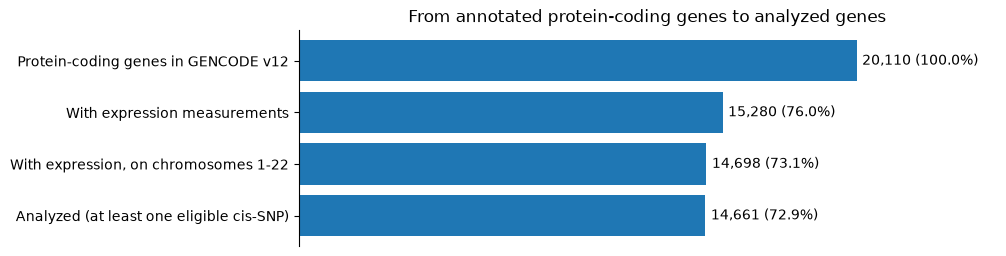

In [5]:
gene_flow = pd.Series({'Protein-coding genes in GENCODE v12': len(genes),
                       'With expression measurements': int(expressed.sum()),
                       'With expression, on chromosomes 1-22': int((expressed & autosomal).sum()),
                       'Analyzed (at least one eligible cis-SNP)': len(gene_hits)})
fig, ax = plt.subplots(figsize=(9, 2.8))
bars = ax.barh(gene_flow.index, gene_flow, color='C0')
ax.bar_label(bars, labels=[f'{v:,} ({v / len(genes):.1%})' for v in gene_flow], padding=4)
ax.invert_yaxis()
ax.set_xlim(0, gene_flow.max() * 1.25)
ax.set_title('From annotated protein-coding genes to analyzed genes')
ax.xaxis.set_visible(False)
ax.spines[['top', 'right', 'bottom']].set_visible(False)
fig.savefig(figures / '01_genes_kept_at_each_filtering_step.png', dpi=180, bbox_inches='tight')
plt.show()

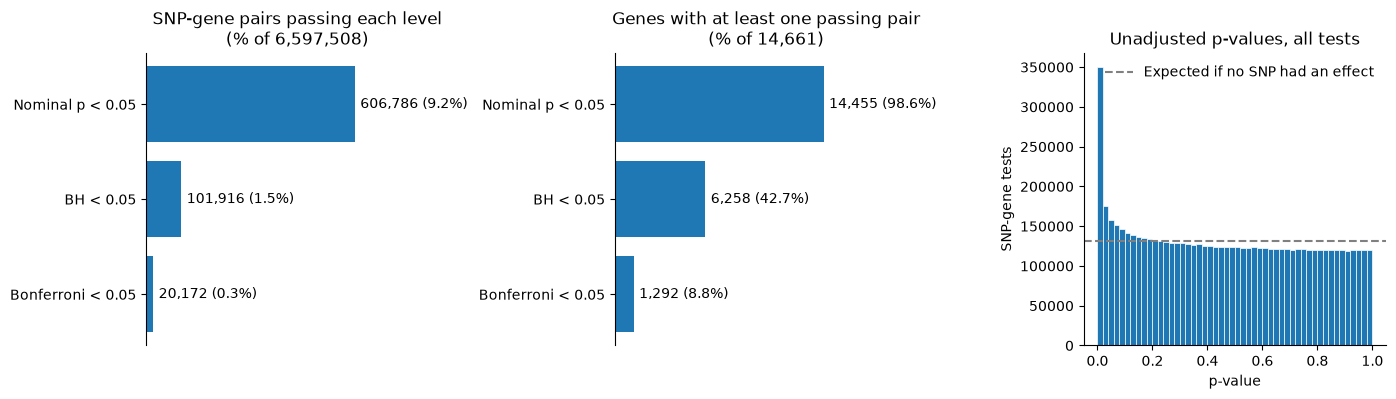

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), gridspec_kw={'wspace': 0.55})
panels = [('SNP-gene pairs passing each level', number_of_tests, 'SNP-gene pairs'),
          ('Genes with at least one passing pair', len(gene_hits), 'Protein-coding genes')]
for ax, (title, total, key) in zip(axes, panels):
    bars = ax.barh(levels, correction_summary[key], color='C0')
    ax.bar_label(bars, labels=[f'{v:,} ({v / total:.1%})' for v in correction_summary[key]], padding=4)
    ax.invert_yaxis()
    ax.set_xlim(0, correction_summary[key].max() * 1.45)
    ax.set_title(f'{title}\n(% of {total:,})')
    ax.xaxis.set_visible(False)
    ax.spines['bottom'].set_visible(False)
axes[2].hist(associations['P'], bins=50, range=(0, 1), color='C0', edgecolor='white', linewidth=0.5)
axes[2].axhline(number_of_tests / 50, linestyle='--', color='gray', label='Expected if no SNP had an effect')
axes[2].set(title='Unadjusted p-values, all tests', xlabel='p-value', ylabel='SNP-gene tests')
axes[2].legend(frameon=False)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.savefig(figures / '02_multiple_testing_results.png', dpi=180, bbox_inches='tight')
plt.show()

### Step 4: Main Results Tables

**Table A** has one row per SNP–gene association. **Table B** has one row per analyzed gene.
**Table C** has one row per chromosome; its `Genes_With_Significant_cis_eQTLs` column uses BH < 0.05.
Each is saved as a file, and only the first rows are shown here because Table A has millions of rows.

In [7]:
gene_columns = genes[['Gene_Symbol', 'Gene_Chr', 'Gene_Start', 'Gene_End']]
table_a = associations.join(gene_columns, on='Gene_ID').rename(columns={
    'SNP': 'SNP_ID', 'CHR': 'SNP_Chr', 'POS': 'SNP_Position', 'COUNTED': 'Counted_Allele',
    'BETA': 'Beta', 'P': 'P_Value'})
table_a = table_a[['Gene_ID', 'Gene_Symbol', 'Gene_Chr', 'Gene_Start', 'Gene_End', 'SNP_ID', 'SNP_Chr',
                   'SNP_Position', 'Counted_Allele', 'Beta', 'SE', 'P_Value', 'P_BH', 'P_Bonferroni', 'N']]
table_a.to_csv(part1 / 'table_A_genome_wide_cis_eqtl.tsv.gz', sep='\t', index=False,
               compression={'method': 'gzip', 'compresslevel': 1})

table_b = gene_columns.rename(columns={'Gene_Chr': 'Chr'}).join(gene_hits, how='inner')
table_b = table_b[['Gene_Symbol', 'Chr', 'SNPs_Tested', 'Nominal_Hits', 'BH_Hits', 'Bonferroni_Hits', 'Min_P_Value']]
table_b.index.name = 'Gene_ID'
table_b = table_b.sort_values('Min_P_Value')
table_b.to_csv(part1 / 'table_B_gene_summary.tsv', sep='\t')

table_b_chr = table_b['Chr'].astype(int)
table_c = pd.DataFrame({
    'Protein_Coding_Genes_Analyzed': table_b_chr.value_counts(),
    'SNP_Gene_Tests': table_a['Gene_Chr'].astype(int).value_counts(),
    'BH_Significant_Pairs': table_b.groupby(table_b_chr)['BH_Hits'].sum(),
    'Bonferroni_Significant_Pairs': table_b.groupby(table_b_chr)['Bonferroni_Hits'].sum(),
    'Genes_With_Significant_cis_eQTLs': table_b.loc[table_b['BH_Hits'].gt(0)].groupby(table_b_chr).size(),
}).reindex(chromosomes).fillna(0).astype(int)
table_c.index.name = 'Chromosome'
table_c.to_csv(part1 / 'table_C_chromosome_summary.tsv', sep='\t')

print('Table A:', table_a.shape)
display(table_a.sort_values('P_Value').head())
print('Table B:', table_b.shape)
display(table_b.head())
print('Table C:', table_c.shape)
display(table_c)

Table A: (6597508, 15)


,Gene_ID,Gene_Symbol,Gene_Chr,Gene_Start,Gene_End,SNP_ID,SNP_Chr,SNP_Position,Counted_Allele,Beta,SE,P_Value,P_BH,P_Bonferroni,N
4090475,ENSG00000197728.5,RPS26,12,56435637,56438116,rs10876864,12,56401085,A,-86.072626,2.049574,4.938813e-137,3.258386e-130,3.258386e-130,344
3619388,ENSG00000166796.7,LDHC,11,18433854,18473605,rs4757650,11,18415815,C,-1.259014,0.036095,1.112289e-114,2.446112e-108,7.338337e-108,344
3619394,ENSG00000166796.7,LDHC,11,18433854,18473605,rs11601413,11,18421683,C,-1.259014,0.036095,1.112289e-114,2.446112e-108,7.338337e-108,344
4090487,ENSG00000197728.5,RPS26,12,56435637,56438116,rs11171739,12,56470625,T,-82.330749,2.433421,3.627052e-111,5.982376e-105,2.392950e-104,344
1837540,ENSG00000164308.12,ERAP2,5,96211643,96255420,rs27290,5,96350088,A,-15.450085,0.463330,1.642397e-109,1.203970e-103,1.083573e-102,344


Table B: (14661, 7)


,Gene_Symbol,Chr,SNPs_Tested,Nominal_Hits,BH_Hits,Bonferroni_Hits,Min_P_Value
Gene_ID,,,,,,,
ENSG00000197728.5,RPS26,12,299,115,81,51,4.938813e-137
ENSG00000166796.7,LDHC,11,459,133,50,37,1.112289e-114
ENSG00000164308.12,ERAP2,5,529,213,134,72,1.642397e-109
ENSG00000182534.7,MXRA7,17,540,123,63,44,1.069619e-100
ENSG00000124587.9,PEX6,6,383,147,67,34,1.681247e-99


Table C: (22, 5)


,Protein_Coding_Genes_Analyzed,SNP_Gene_Tests,BH_Significant_Pairs,Bonferroni_Significant_Pairs,Genes_With_Significant_cis_eQTLs
Chromosome,,,,,
1,1566,668215,8881,1569,606
2,966,422393,6530,1165,408
3,841,382698,5890,924,339
4,521,240675,3910,751,227
5,670,314599,5078,889,288
6,799,376952,7979,1969,368
7,692,295955,5289,1024,295
8,535,248689,4256,900,220
9,600,283999,3898,706,273


### Checking the Analysis

Each check recomputes one requirement a different way, and the notebook stops with an error if any of
them fails. The full list of results is saved in `verification_checks.tsv`. Where the earlier weeks' local results exist, three checks also use them: people must match Week 2, chromosome 1 must reproduce Week 4's
regressions, and PARK7 must reproduce Week 3. One pair is always refit from the raw files with `numpy.polyfit`.

In [8]:
checks = {}

# Scope: protein-coding genes on all 22 autosomes.
checks['All 22 autosomes have results'] = sorted(table_a['Gene_Chr'].astype(int).unique()) == chromosomes
checks['Every analyzed gene is protein-coding in GENCODE'] = annotation.loc[table_b.index, 'Gene_Type'].eq('protein_coding').all()
checks['Every eligible gene is analyzed or has a recorded reason'] = len(table_b) + len(excluded) == len(genes)

# Windows and regression bookkeeping.
checks['Every SNP is on its gene\'s chromosome'] = (table_a['SNP_Chr'].astype(str) == table_a['Gene_Chr']).all()
checks['Every SNP is inside gene body +/- 500 kb'] = ((table_a['SNP_Position'] >= table_a['Gene_Start'] - 500000)
                                                       & (table_a['SNP_Position'] <= table_a['Gene_End'] + 500000)).all()
checks['No SNP-gene pair is tested twice'] = not table_a.duplicated(['Gene_ID', 'SNP_ID']).any()
checks['Every test uses all 344 people'] = table_a['N'].eq(len(ids)).all()
checks['All p-values, betas, and SEs are valid'] = (table_a['P_Value'].between(0, 1).all()
    and np.isfinite(table_a[['Beta', 'SE']]).all().all() and table_a['SE'].gt(0).all())

# Sample alignment: same people in the genotype files and the expression table.
fam_sets = [set(pd.read_csv(f'data/LDREF/1000G.EUR.{c}.fam', sep=r'\s+', header=None, dtype=str)[1]) for c in chromosomes]
checks['All matched people are in every genotype file'] = all(set(ids) <= f for f in fam_sets)
checks['All matched people are in the expression table'] = set(ids) <= set(expression.columns)

# Counted alleles come from the reference panel.
bim = pd.concat([pd.read_csv(f'data/LDREF/1000G.EUR.{c}.bim', sep=r'\s+', header=None, names=['Chr', 'SNP_ID', 'cM', 'Position', 'A1', 'A2'])
                 for c in chromosomes]).set_index('SNP_ID')
bim_for_tests = bim.reindex(table_a['SNP_ID'])
checks['SNP positions match the reference panel'] = (bim_for_tests['Position'].to_numpy() == table_a['SNP_Position'].to_numpy()).all()
checks['Counted alleles are alleles of that SNP'] = ((bim_for_tests['A1'].to_numpy() == table_a['Counted_Allele'].to_numpy())
                                                     | (bim_for_tests['A2'].to_numpy() == table_a['Counted_Allele'].to_numpy())).all()

# Corrections use the genome-wide family.
sorted_p = np.sort(table_a['P_Value'].to_numpy())
bh_passing = np.nonzero(sorted_p <= 0.05 * np.arange(1, number_of_tests + 1) / number_of_tests)[0]
checks['BH count matches a direct step-up calculation'] = bh_passing[-1] + 1 == table_a['P_BH'].lt(0.05).sum()
checks['Bonferroni count matches p < 0.05 / all tests'] = (table_a['P_Value'] < 0.05 / number_of_tests).sum() == table_a['P_Bonferroni'].lt(0.05).sum()

# Summary tables agree with Table A.
checks['Table B tests sum to Table A rows'] = table_b['SNPs_Tested'].sum() == len(table_a)
checks['Table B hits sum to Table A hits'] = (table_b['BH_Hits'].sum() == table_a['P_BH'].lt(0.05).sum()
                                              and table_b['Bonferroni_Hits'].sum() == table_a['P_Bonferroni'].lt(0.05).sum())
checks['Table C columns sum to Table A and Table B'] = (table_c['SNP_Gene_Tests'].sum() == len(table_a)
    and table_c['Protein_Coding_Genes_Analyzed'].sum() == len(table_b)
    and table_c['BH_Significant_Pairs'].sum() == table_a['P_BH'].lt(0.05).sum()
    and table_c['Bonferroni_Significant_Pairs'].sum() == table_a['P_Bonferroni'].lt(0.05).sum()
    and table_c['Genes_With_Significant_cis_eQTLs'].sum() == table_b['BH_Hits'].gt(0).sum())
saved_a = pd.read_csv(part1 / 'table_A_genome_wide_cis_eqtl.tsv.gz', sep='\t', usecols=['P_Value'])
checks['Saved Table A matches in-memory results'] = len(saved_a) == len(table_a) and np.allclose(saved_a['P_Value'], table_a['P_Value'], rtol=1e-12, atol=0)

week2_ids = Path('data/week2_results/matched_sample_ids.tsv')
if week2_ids.exists():
    checks['Matched people are the same as Week 2'] = pd.read_csv(week2_ids, sep='\t', dtype=str)['IID'].tolist() == ids

# Chromosome 1 reproduces Week 4, using Week 4's own all-gene output, when that local file exists.
if Path('data/week4_results/chr1_cis_eqtl.tsv.gz').exists():
    week4 = pd.read_csv('data/week4_results/chr1_cis_eqtl.tsv.gz', sep='\t', usecols=['Gene_ID', 'SNP', 'COUNTED', 'BETA', 'SE', 'P'])
    week4 = week4.loc[week4['Gene_ID'].isin(genes.index)]
    chr1 = table_a.loc[table_a['Gene_Chr'].eq('1')]
    matched = chr1.merge(week4, left_on=['Gene_ID', 'SNP_ID'], right_on=['Gene_ID', 'SNP'])
    print('Chromosome 1 protein-coding pairs here / Week 4 / matched:', len(chr1), len(week4), len(matched))
    print('Largest chromosome 1 beta and p-value difference from Week 4:',
          (matched['Beta'] - matched['BETA']).abs().max(), (matched['P_Value'] - matched['P']).abs().max())
    checks['Chromosome 1 pairs match Week 4 exactly'] = len(chr1) == len(week4) == len(matched) and matched['Counted_Allele'].eq(matched['COUNTED']).all()
    checks['Chromosome 1 betas and p-values match Week 4'] = (np.allclose(matched['Beta'], matched['BETA'], rtol=1e-9, atol=1e-12)
                                                             and np.allclose(matched['P_Value'], matched['P'], rtol=1e-6, atol=1e-300))

# PARK7 reproduces Week 3, when that local file exists.
if Path('data/week3_results/PARK7_cis_eqtl.tsv').exists():
    week3 = pd.read_csv('data/week3_results/PARK7_cis_eqtl.tsv', sep='\t')
    park7 = table_a.loc[table_a['Gene_ID'].eq('ENSG00000116288.8')].sort_values('P_Value').iloc[0]
    week3_lead = week3.sort_values('P_value').iloc[0]
    print('PARK7 lead SNP here:', park7['SNP_ID'], '| p =', park7['P_Value'])
    print('Week 3 lead SNP:', week3_lead['SNP_ID'], '| p =', week3_lead['P_value'])
    checks['PARK7 lead SNP and p-value match Week 3'] = park7['SNP_ID'] == week3_lead['SNP_ID'] and np.isclose(park7['P_Value'], week3_lead['P_value'], rtol=1e-9)

# One pair recomputed from the raw expression and genotype files.
spot = table_a.loc[table_a['Gene_Chr'].eq('22')].sort_values('P_Value').iloc[0]
raw_y = pd.read_csv(expression_path, sep='\t', usecols=['TargetID', *ids]).set_index('TargetID').loc[spot['Gene_ID'], ids].astype(float)
traw = pd.read_csv(part1 / 'chromosomes' / 'chr22.traw', sep=r'\s+')
row = traw.loc[traw['SNP'].eq(spot['SNP_ID'])].iloc[0]
spot_g = row[[column[i] for i in ids]].to_numpy(float)
spot_slope = np.polyfit(spot_g, raw_y.to_numpy(), 1)[0]
print('Spot check', spot['Gene_Symbol'], spot['SNP_ID'], '| Table A beta:', spot['Beta'], '| polyfit beta:', spot_slope)
checks['Refit from raw files matches Table A'] = np.isclose(spot_slope, spot['Beta'], rtol=1e-9) and row['COUNTED'] == spot['Counted_Allele']

verification = pd.Series(checks, name='Passed').to_frame()
verification.to_csv(part1 / 'verification_checks.tsv', sep='\t')
assert verification['Passed'].all()

Chromosome 1 protein-coding pairs here / Week 4 / matched: 668215 668215 668215
Largest chromosome 1 beta and p-value difference from Week 4: 0.0 2.6469779601696886e-23
PARK7 lead SNP here: rs11805932 | p = 0.0009957598850764
Week 3 lead SNP: rs11805932 | p = 0.0009957598850764
Spot check FAM118A rs104664 | Table A beta: -13.17109041383702 | polyfit beta: -13.171090413836911


### Step 5: Visualizing the Findings

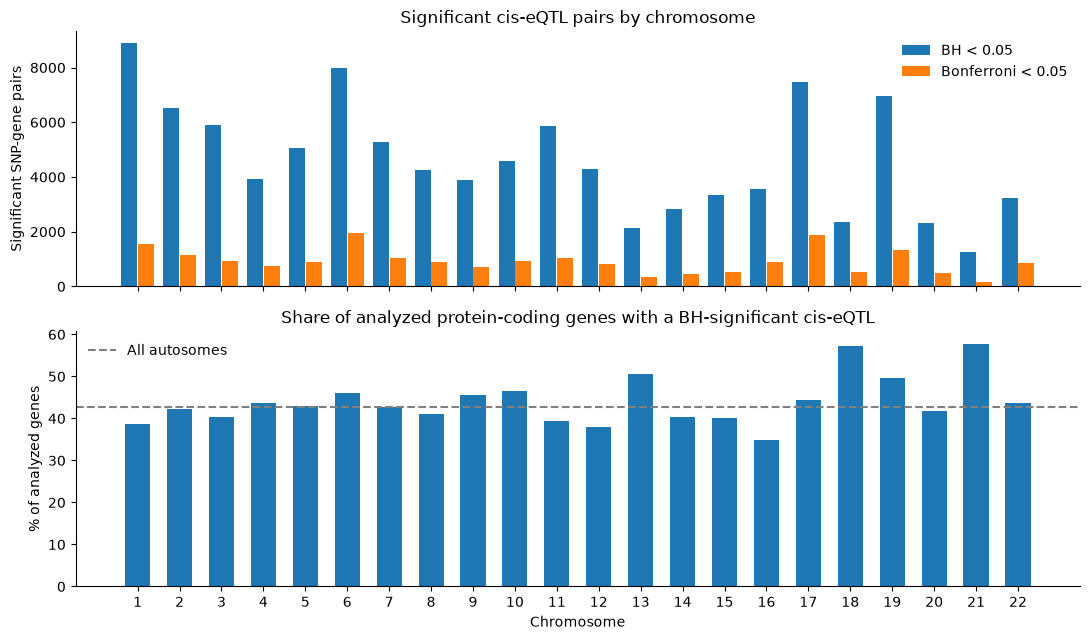

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
x = np.arange(len(table_c))
axes[0].bar(x - 0.2, table_c['BH_Significant_Pairs'], 0.38, color='C0', label='BH < 0.05')
axes[0].bar(x + 0.2, table_c['Bonferroni_Significant_Pairs'], 0.38, color='C1', label='Bonferroni < 0.05')
axes[0].set(ylabel='Significant SNP-gene pairs', title='Significant cis-eQTL pairs by chromosome')
axes[0].legend(frameon=False)
share = 100 * table_c['Genes_With_Significant_cis_eQTLs'] / table_c['Protein_Coding_Genes_Analyzed']
axes[1].bar(x, share, 0.6, color='C0')
axes[1].axhline(100 * table_b['BH_Hits'].gt(0).mean(), linestyle='--', color='gray', label='All autosomes')
axes[1].set(ylabel='% of analyzed genes', xlabel='Chromosome', title='Share of analyzed protein-coding genes with a BH-significant cis-eQTL')
axes[1].set_xticks(x, table_c.index)
axes[1].legend(frameon=False)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(figures / '03_significant_cis_eqtls_by_chromosome.png', dpi=180)
plt.show()

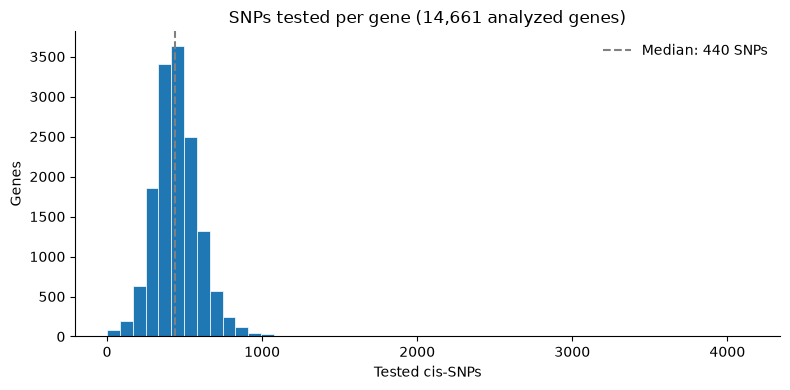

,SNPs tested per gene
count,14661.000000
mean,450.003956
std,153.332382
min,1.000000
25%,358.000000
50%,440.000000
75%,529.000000
max,4133.000000


,Gene_Symbol,Chr,SNPs_Tested,Gene_Length,Bonferroni_Hits
Gene_ID,,,,,
ENSG00000160183.8,TMPRSS3,21,4133,5379013,0
ENSG00000183117.10,CSMD1,8,3246,2059502,1
ENSG00000183486.7,MX2,21,2426,3012804,0
ENSG00000140945.10,CDH13,16,2055,1169796,0
ENSG00000186153.11,WWOX,16,1976,1113254,0


,Genes with no eligible cis-SNPs
Gene_Chr,
12,20
9,8
6,4
1,2
5,1
14,1
21,1


Widest SNP gap on chromosome 12: 6956462 to 10000986
Chromosome 12 genes with no cis-SNPs start between 7499281 and 9220260


In [10]:
median_snps = table_b['SNPs_Tested'].median()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(table_b['SNPs_Tested'], bins=50, color='C0', edgecolor='white', linewidth=0.5)
ax.axvline(median_snps, linestyle='--', color='gray', label=f'Median: {median_snps:.0f} SNPs')
ax.set(title=f'SNPs tested per gene ({len(table_b):,} analyzed genes)', xlabel='Tested cis-SNPs', ylabel='Genes')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(figures / '04_snps_tested_per_gene.png', dpi=180)
plt.show()
display(table_b['SNPs_Tested'].describe().to_frame('SNPs tested per gene'))

longest = table_b.join(genes['Gene_End'].sub(genes['Gene_Start']).rename('Gene_Length'))
display(longest.nlargest(5, 'SNPs_Tested')[['Gene_Symbol', 'Chr', 'SNPs_Tested', 'Gene_Length', 'Bonferroni_Hits']])
no_snps = excluded.loc[excluded['Reason'].eq('No eligible cis-SNPs')]
display(no_snps['Gene_Chr'].value_counts().to_frame('Genes with no eligible cis-SNPs'))
chr12_positions = np.sort(pd.read_csv('data/LDREF/1000G.EUR.12.bim', sep=r'\s+', header=None, usecols=[3])[3].to_numpy())
widest = np.diff(chr12_positions).argmax()
print('Widest SNP gap on chromosome 12:', chr12_positions[widest], 'to', chr12_positions[widest + 1])
print('Chromosome 12 genes with no cis-SNPs start between', no_snps.loc[no_snps['Gene_Chr'].eq('12'), 'Gene_Start'].min(),
      'and', no_snps.loc[no_snps['Gene_Chr'].eq('12'), 'Gene_Start'].max())

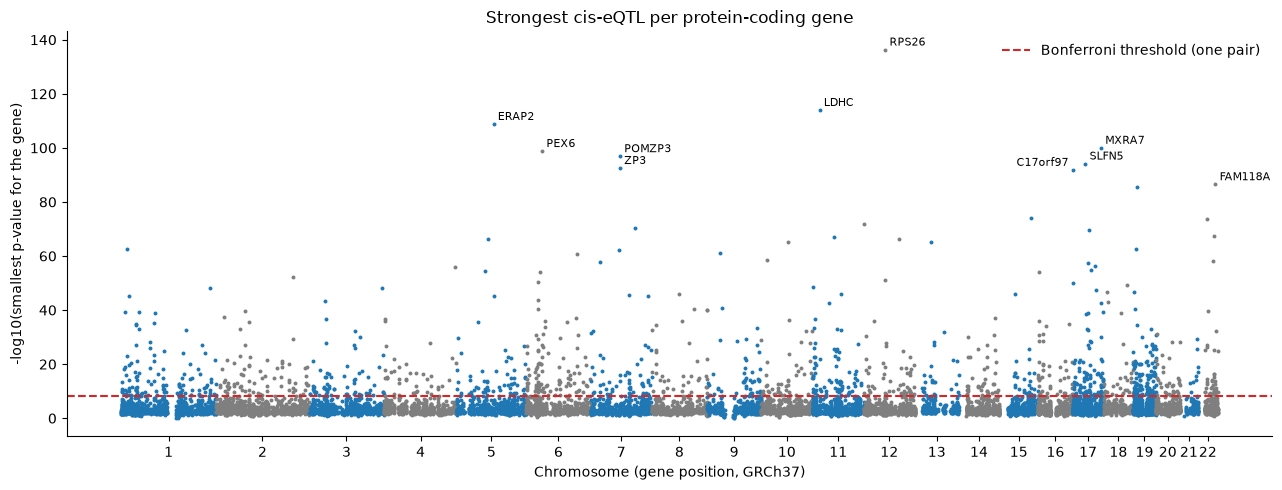

,Gene_Symbol,Gene_Chr,SNP_ID,Counted_Allele,Beta,P_Value,P_Bonferroni
4090475,RPS26,12,rs10876864,A,-86.072626,4.938813e-137,3.258386e-130
3619388,LDHC,11,rs4757650,C,-1.259014,1.112289e-114,7.338337e-108
1837540,ERAP2,5,rs27290,A,-15.450085,1.642397e-109,1.083573e-102
5500107,MXRA7,17,rs9303003,C,-2.856280,1.069619e-100,7.056822e-94
2210489,PEX6,6,rs10948059,C,-2.978059,1.681247e-99,1.109204e-92
2533559,POMZP3,7,rs17718122,A,-4.966675,1.372033e-97,9.051998e-91
5320521,SLFN5,17,rs883416,C,-6.530581,7.413177e-95,4.890849e-88
2532568,ZP3,7,rs17718122,A,-4.245106,3.240418e-93,2.137869e-86
5167983,C17orf97,17,rs11150882,G,-2.646672,1.601580e-92,1.056644e-85
6575922,FAM118A,22,rs104664,A,-13.171090,3.256798e-87,2.148675e-80


In [11]:
manhattan = table_b.join(genes[['Gene_Start', 'Gene_End']])
manhattan['Chr_Number'] = manhattan['Chr'].astype(int)
manhattan['Middle'] = (manhattan['Gene_Start'] + manhattan['Gene_End']) / 2
assert manhattan['Min_P_Value'].gt(0).all()
manhattan['Log_P'] = -np.log10(manhattan['Min_P_Value'])
lengths = manhattan.groupby('Chr_Number')['Middle'].max()
offsets = lengths.cumsum().shift(fill_value=0)
manhattan['Genome_Position'] = manhattan['Middle'] + manhattan['Chr_Number'].map(offsets)

fig, ax = plt.subplots(figsize=(13, 5))
for chrom, group in manhattan.groupby('Chr_Number'):
    ax.scatter(group['Genome_Position'], group['Log_P'], s=8, color='C0' if chrom % 2 else 'C7', linewidths=0)
ax.axhline(-np.log10(0.05 / number_of_tests), linestyle='--', color='C3', label='Bonferroni threshold (one pair)')
for _, top in manhattan.nsmallest(10, 'Min_P_Value').iterrows():
    label_left = top['Gene_Symbol'] == 'C17orf97'  # keeps this label off its chromosome 17 neighbors
    ax.annotate(top['Gene_Symbol'], (top['Genome_Position'], top['Log_P']), xytext=(-3 if label_left else 3, 3),
                textcoords='offset points', ha='right' if label_left else 'left', fontsize=8)
ax.set_xticks(offsets + lengths / 2, chromosomes)
ax.set(xlabel='Chromosome (gene position, GRCh37)', ylabel='-log10(smallest p-value for the gene)',
       title='Strongest cis-eQTL per protein-coding gene')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(figures / '05_manhattan_strongest_cis_eqtl_per_gene.png', dpi=180)
plt.show()

lead_snps = table_a.sort_values('P_Value').drop_duplicates('Gene_ID')
top_genes = lead_snps.head(15)[['Gene_Symbol', 'Gene_Chr', 'SNP_ID', 'Counted_Allele', 'Beta', 'P_Value', 'P_Bonferroni']]
display(top_genes)

### A Closer Look at the Strongest Signal

This looks at the gene with the smallest p-value in the genome. The left panel shows why one gene produces many
significant pairs: nearby SNPs in LD carry nearly the same signal. The right panel shows the lead
SNP's effect in the people themselves.

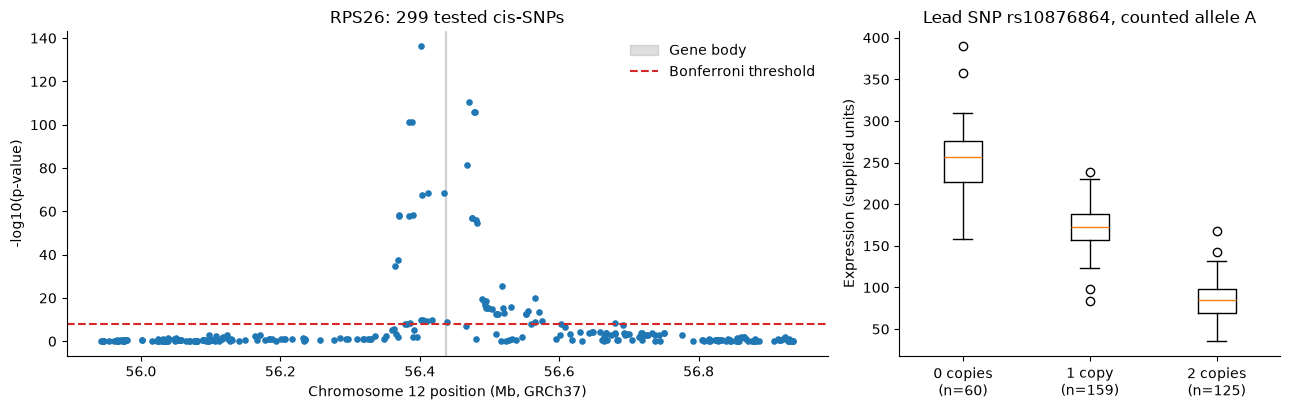

Median expression by copies: [257.2, 172.7, 85.3]
Lead SNP distance from gene start: 34552 bp
Bonferroni-significant SNPs for this gene: 51


In [12]:
top_gene = table_b.index[0]
locus = table_a.loc[table_a['Gene_ID'].eq(top_gene)].sort_values('SNP_Position')
top_snp = locus.loc[locus['P_Value'].idxmin()]
top_traw = pd.read_csv(part1 / 'chromosomes' / f"chr{top_snp['Gene_Chr']}.traw", sep=r'\s+')
top_dosage = top_traw.loc[top_traw['SNP'].eq(top_snp['SNP_ID']), [column[i] for i in ids]].iloc[0].to_numpy(float)
top_expression = expression.loc[top_gene, ids].to_numpy(float)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [2, 1]})
axes[0].axvspan(top_snp['Gene_Start'] / 1e6, top_snp['Gene_End'] / 1e6, color='C7', alpha=0.25, label='Gene body')
axes[0].scatter(locus['SNP_Position'] / 1e6, -np.log10(locus['P_Value']), s=14, color='C0')
axes[0].axhline(-np.log10(0.05 / number_of_tests), linestyle='--', color='C3', label='Bonferroni threshold')
axes[0].set(xlabel=f"Chromosome {top_snp['Gene_Chr']} position (Mb, GRCh37)", ylabel='-log10(p-value)',
            title=f"{top_snp['Gene_Symbol']}: {len(locus)} tested cis-SNPs")
axes[0].legend(frameon=False)
copies = [0, 1, 2]
groups = [top_expression[top_dosage == k] for k in copies]
axes[1].boxplot(groups, tick_labels=[f"{k} {'copy' if k == 1 else 'copies'}\n(n={len(g)})" for k, g in zip(copies, groups)])
axes[1].set(ylabel='Expression (supplied units)', title=f"Lead SNP {top_snp['SNP_ID']}, counted allele {top_snp['Counted_Allele']}")
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(figures / f"06_{top_snp['Gene_Symbol']}_association_and_expression_by_genotype.png", dpi=180)
plt.show()
print('Median expression by copies:', [round(float(np.median(g)), 1) for g in groups])
print('Lead SNP distance from gene start:', int(top_snp['Gene_Start'] - top_snp['SNP_Position']), 'bp')
print('Bonferroni-significant SNPs for this gene:', int(locus['P_Bonferroni'].lt(0.05).sum()))

### LocusZoom Plot of the Strongest cis-eQTL

A LocusZoom plot shows the whole cis-window for one gene, with three tracks on the same position axis:

- **Association:** each point is one tested SNP. Its color shows its LD (r²) with the lead SNP, the purple
  diamond, measured in the same 344 people. Red points are largely inherited together with the lead SNP.
- **Recombination rate:** calculated between neighboring SNPs from the genetic-map column of the `.bim` file.
  LD tends to break down across recombination peaks.
- **Genes:** protein-coding genes in the window, with exons as thick bars and arrows showing direction. The
  mapped gene is in red.

The plot is drawn in matplotlib using LocusZoom's layout and color scheme, so it needs no extra software.

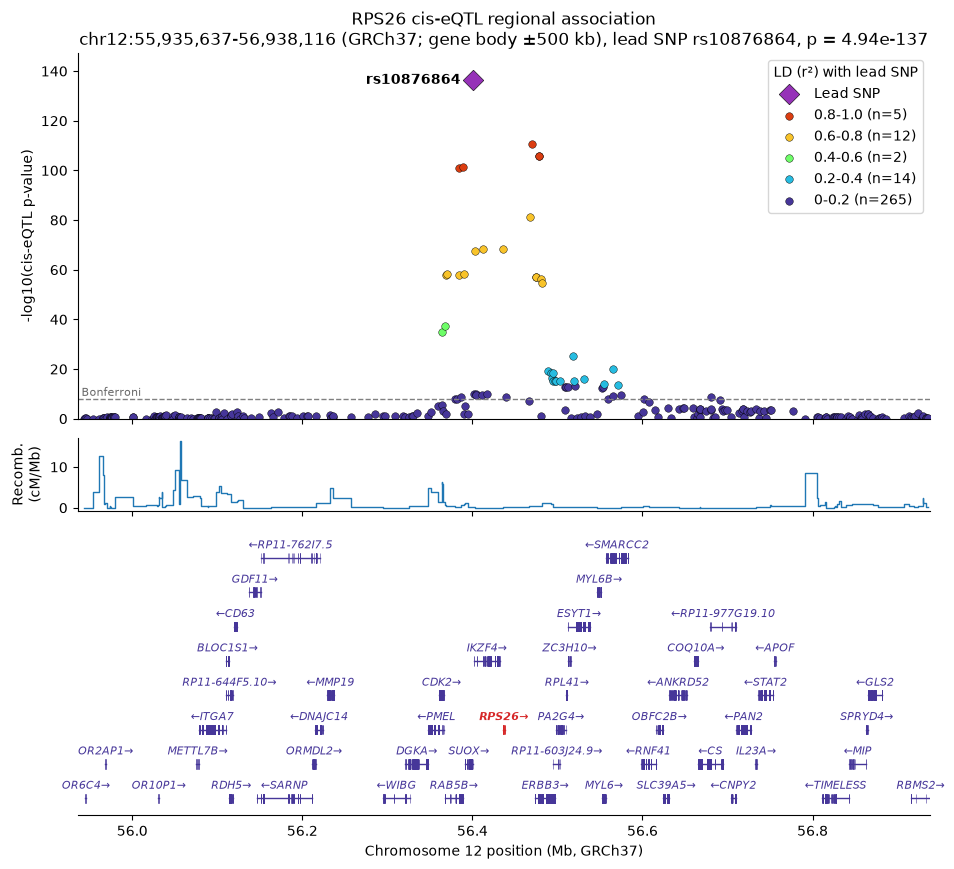

,All tested SNPs,Bonferroni-significant SNPs
r² > 0.8,6,6
r² > 0.5,18,18
r² > 0.2,34,34


Tested SNPs: 299 | Bonferroni-significant SNPs: 51


In [13]:
ld_bins = [(0.8, 1.01, '#DB3D11', '0.8-1.0'), (0.6, 0.8, '#F8C32A', '0.6-0.8'), (0.4, 0.6, '#6EFE68', '0.4-0.6'),
           (0.2, 0.4, '#26BCE1', '0.2-0.4'), (0, 0.2, '#463699', '0-0.2')]

def locus_zoom(gene_id, output_path):
    '''LocusZoom-style plot: association colored by LD with the lead SNP, recombination rate, and nearby genes.'''
    locus = table_a.loc[table_a['Gene_ID'].eq(gene_id)].sort_values('SNP_Position').copy()
    lead = locus.loc[locus['P_Value'].idxmin()]
    chrom, start, end = lead['Gene_Chr'], lead['Gene_Start'] - 500000, lead['Gene_End'] + 500000

    # r2 with the lead SNP, among the same 344 people used in the regressions.
    traw = pd.read_csv(part1 / 'chromosomes' / f'chr{chrom}.traw', sep=r'\s+').set_index('SNP')
    dosages = traw.loc[locus['SNP_ID'], [column[i] for i in ids]].to_numpy(float)
    locus['LD_R2'] = np.corrcoef(dosages)[list(locus['SNP_ID']).index(lead['SNP_ID'])] ** 2
    locus['Log_P'] = -np.log10(locus['P_Value'])

    # Recombination rate between neighboring SNPs, from the genetic-map column of the .bim file.
    bim_map = pd.read_csv(f'data/LDREF/1000G.EUR.{chrom}.bim', sep=r'\s+', header=None, usecols=[2, 3], names=['cM', 'Position'])
    bim_map = bim_map.loc[bim_map['Position'].between(start, end)].sort_values('Position')
    recombination = bim_map['cM'].diff() / bim_map['Position'].diff() * 1e6

    # Exons of the protein-coding genes overlapping the window.
    nearby = genes.loc[genes['Gene_Chr'].eq(chrom) & (genes['Gene_End'] >= start) & (genes['Gene_Start'] <= end)].sort_values('Gene_Start')
    annotation_rows = pd.read_csv(gtf_path, sep='\t', comment='#', header=None, usecols=[0, 2, 3, 4, 6, 8])
    exons = annotation_rows.loc[annotation_rows[0].eq(f'chr{chrom}') & annotation_rows[2].eq('exon')
                                & (annotation_rows[4] >= start) & (annotation_rows[3] <= end)].copy()
    exons['Gene_ID'] = exons[8].str.extract(r'gene_id "([^"]+)"')[0]
    exons = exons.loc[exons['Gene_ID'].isin(nearby.index)]
    strands = exons.groupby('Gene_ID')[6].first()

    # Put genes on rows so that bars and labels do not overlap.
    character_width = (end - start) * 0.0095
    row_ends, rows = [], {}
    for gene, record in nearby.iterrows():
        left, right = max(record['Gene_Start'], start), min(record['Gene_End'], end)
        middle = (left + right) / 2
        half_label = (len(record['Gene_Symbol']) + 2) * character_width / 2
        needed_left, needed_right = min(left, middle - half_label), max(right, middle + half_label)
        row = next((r for r, row_end in enumerate(row_ends) if row_end < needed_left), len(row_ends))
        row_ends[row:row + 1] = [needed_right]
        rows[gene] = row

    fig, axes = plt.subplots(3, 1, figsize=(11, 7.5 + 0.3 * len(row_ends)), sharex=True,
                             gridspec_kw={'height_ratios': [5, 1, 0.45 * len(row_ends) + 0.3], 'hspace': 0.08})
    association, rate, track = axes

    for low, high, color, label in reversed(ld_bins):
        group = locus.loc[locus['LD_R2'].ge(low) & locus['LD_R2'].lt(high) & locus['SNP_ID'].ne(lead['SNP_ID'])]
        association.scatter(group['SNP_Position'] / 1e6, group['Log_P'], s=30, color=color, edgecolor='black',
                            linewidth=0.3, label=f'{label} (n={len(group)})')
    association.scatter(lead['SNP_Position'] / 1e6, -np.log10(lead['P_Value']), s=110, marker='D', color='#9632B8',
                        edgecolor='black', linewidth=0.4, zorder=3, label='Lead SNP')
    association.annotate(lead['SNP_ID'], (lead['SNP_Position'] / 1e6, -np.log10(lead['P_Value'])), xytext=(-9, 0),
                         textcoords='offset points', ha='right', va='center', fontweight='bold')
    association.axhline(-np.log10(0.05 / number_of_tests), linestyle='--', color='gray', linewidth=1)
    association.text(start / 1e6, -np.log10(0.05 / number_of_tests), ' Bonferroni', va='bottom', color='dimgray', fontsize=8)
    handles, labels = association.get_legend_handles_labels()
    order = [labels.index('Lead SNP')] + [i for i, name in enumerate(labels) if name != 'Lead SNP'][::-1]
    association.legend([handles[i] for i in order], [labels[i] for i in order], title='LD (r²) with lead SNP', loc='upper right', frameon=True)
    association.set(ylabel='-log10(cis-eQTL p-value)', ylim=(0, locus['Log_P'].max() * 1.08),
                    title=f"{lead['Gene_Symbol']} cis-eQTL regional association\n"
                          f"chr{chrom}:{start:,}-{end:,} (GRCh37; gene body ±500 kb), lead SNP {lead['SNP_ID']}, p = {lead['P_Value']:.2e}")

    rate.step(bim_map['Position'] / 1e6, recombination, where='pre', color='C0', linewidth=1)
    rate.set_ylabel('Recomb.\n(cM/Mb)')

    for gene, record in nearby.iterrows():
        row = rows[gene]
        target = gene == gene_id
        color = 'C3' if target else '#463699'
        left, right = max(record['Gene_Start'], start), min(record['Gene_End'], end)
        track.plot([left / 1e6, right / 1e6], [row, row], color=color, linewidth=1)
        for _, exon in exons.loc[exons['Gene_ID'].eq(gene)].iterrows():
            track.fill_between([exon[3] / 1e6, exon[4] / 1e6], row - 0.14, row + 0.14, color=color, linewidth=0.4)
        symbol = record['Gene_Symbol']
        arrow = f'{symbol}→' if strands.get(gene) == '+' else f'←{symbol}'
        track.text((left + right) / 2e6, row + 0.2, arrow, ha='center', va='bottom', fontsize=8, style='italic',
                   color=color, fontweight='bold' if target else 'normal')
    track.set_ylim(-0.5, len(row_ends) - 0.2)
    track.yaxis.set_visible(False)
    track.set(xlim=(start / 1e6, end / 1e6), xlabel=f'Chromosome {chrom} position (Mb, GRCh37)')
    track.spines['left'].set_visible(False)
    for ax in axes:
        ax.spines[['top', 'right']].set_visible(False)
    fig.savefig(output_path, dpi=180, bbox_inches='tight')
    plt.show()
    return locus

zoom_locus = locus_zoom(top_gene, figures / f'07_{table_b.loc[top_gene, "Gene_Symbol"]}_locuszoom.png')
zoom_significant = zoom_locus['P_Bonferroni'].lt(0.05)
ld_counts = pd.DataFrame({
    'All tested SNPs': [int((zoom_locus['LD_R2'] > r).sum()) for r in (0.8, 0.5, 0.2)],
    'Bonferroni-significant SNPs': [int(((zoom_locus['LD_R2'] > r) & zoom_significant).sum()) for r in (0.8, 0.5, 0.2)],
}, index=['r² > 0.8', 'r² > 0.5', 'r² > 0.2'])
display(ld_counts)
print('Tested SNPs:', len(zoom_locus), '| Bonferroni-significant SNPs:', int(zoom_significant.sum()))

### Are Rare SNPs or Outliers Driving the Hits?

There is no MAF filter and expression values are heavy-tailed, so a SNP carried by a few people could
look significant because one of them has an unusual expression value. This check does **not** change
any result above; it shows how much to trust them.

The first table groups tests by minor allele count (MAC), the number of copies of the rarer allele among
the 344 people. The second refits the 15 strongest genes with **Spearman correlation**, which uses ranks,
so one extreme value has limited influence.

In [14]:
minor_counts = []
for chrom in chromosomes:
    traw = pd.read_csv(part1 / 'chromosomes' / f'chr{chrom}.traw', sep=r'\s+')
    counted = traw[[column[i] for i in ids]].sum(axis=1)
    minor_counts.append(pd.Series(np.minimum(counted, 2 * len(ids) - counted).to_numpy(), index=traw['SNP']))
minor_counts = pd.concat(minor_counts)

mac = pd.cut(table_a['SNP_ID'].map(minor_counts), [0, 1, 4, 9, np.inf], labels=['1', '2-4', '5-9', '10 or more'])
mac_summary = pd.DataFrame({
    'Tests': table_a.groupby(mac, observed=True).size(),
    'Nominal_Rate': table_a['P_Value'].lt(0.05).groupby(mac, observed=True).mean().round(4),
    'BH_Pairs': table_a['P_BH'].lt(0.05).groupby(mac, observed=True).sum(),
    'Bonferroni_Pairs': table_a['P_Bonferroni'].lt(0.05).groupby(mac, observed=True).sum(),
})
mac_summary.index.name = 'Minor_Allele_Count'
mac_summary.to_csv(part1 / 'minor_allele_count_summary.tsv', sep='\t')
display(mac_summary)

common = mac.eq('10 or more').to_numpy()
for name, column_name in [('BH', 'P_BH'), ('Bonferroni', 'P_Bonferroni')]:
    passing = table_a[column_name].lt(0.05).to_numpy()
    any_hit = table_a.loc[passing, 'Gene_ID'].nunique()
    common_hit = table_a.loc[passing & common, 'Gene_ID'].nunique()
    print(f'{name}: {any_hit} genes have a hit; {any_hit - common_hit} have hits only from SNPs with MAC below 10')
    print(f'{name}: median significant SNPs per significant gene:', table_a.loc[passing].groupby('Gene_ID').size().median())

rows = []
for _, lead in lead_snps.head(15).iterrows():
    traw = pd.read_csv(part1 / 'chromosomes' / f"chr{lead['Gene_Chr']}.traw", sep=r'\s+')
    dosage = traw.loc[traw['SNP'].eq(lead['SNP_ID']), [column[i] for i in ids]].iloc[0].to_numpy(float)
    y = expression.loc[lead['Gene_ID'], ids].to_numpy(float)
    rows.append({'Gene_Symbol': lead['Gene_Symbol'], 'SNP_ID': lead['SNP_ID'], 'MAC': int(minor_counts[lead['SNP_ID']]),
                 'Regression_P': lead['P_Value'], 'Spearman_P': spearmanr(dosage, y).pvalue,
                 'Largest_Expression_Z': (y.max() - y.mean()) / y.std()})
robustness = pd.DataFrame(rows)
robustness['Spearman_Passes_Bonferroni_Cutoff'] = robustness['Spearman_P'] < 0.05 / number_of_tests
robustness.to_csv(part1 / 'top_gene_robustness.tsv', sep='\t', index=False)
display(robustness)

,Tests,Nominal_Rate,BH_Pairs,Bonferroni_Pairs
Minor_Allele_Count,,,,
1,2462,0.0439,15,5
2-4,40051,0.0566,346,63
5-9,114712,0.0586,688,59
10 or more,6440283,0.0928,100867,20045


BH: 6258 genes have a hit; 254 have hits only from SNPs with MAC below 10
BH: median significant SNPs per significant gene: 6.0
Bonferroni: 1292 genes have a hit; 59 have hits only from SNPs with MAC below 10
Bonferroni: median significant SNPs per significant gene: 9.0


,Gene_Symbol,SNP_ID,MAC,Regression_P,Spearman_P,Largest_Expression_Z,Spearman_Passes_Bonferroni_Cutoff
0,RPS26,rs10876864,279,4.938813e-137,2.429207e-128,3.525443,True
1,LDHC,rs4757650,75,1.112289e-114,2.038932e-48,5.519980,True
2,ERAP2,rs27290,289,1.642397e-109,8.166660e-99,2.683058,True
3,MXRA7,rs9303003,65,1.069619e-100,1.003173e-44,4.492148,True
4,PEX6,rs10948059,338,1.681247e-99,3.959112e-102,2.988833,True
5,POMZP3,rs17718122,195,1.372033e-97,2.096225e-101,4.096993,True
6,SLFN5,rs883416,343,7.413177e-95,8.331263e-91,2.738708,True
7,ZP3,rs17718122,195,3.240418e-93,8.098006e-92,4.059302,True
8,C17orf97,rs11150882,163,1.601580e-92,1.174211e-97,4.447443,True
9,FAM118A,rs104664,89,3.256798e-87,4.658514e-51,4.540184,True


### Results and Interpretation

The findings from this notebook and their interpretation are in [quarter1_part1_results.md](../quarter1_part1_results.md).

## Part 1: Single-Gene Expression Prediction

Association discovery and prediction answer different questions. Discovery tested nearby
SNP–gene associations in the full matched sample. Prediction now estimates **new training-only
effects**, selects a model with validation expression, and assesses it on held-out people.
The completed discovery effects are not used as weights for these test-evaluated predictors.

The shared seed-42 split is 275 training, 34 validation and 35 test people. Training people
alone determine SNP betas, LD clumps (r²=0.1, 250 kb) and expression-score calibration.
Validation selects among inclusive p-value thresholds **1, 0.05, 0.01, 0.001 and 0.00001**.
The selected model is frozen before test outcomes are evaluated.

**Predictive R² = 1 − SSE/SST** measures prediction error, using the observed evaluation-group
mean for SST. It can be negative. **Pearson r²** measures squared correlation and can remain
high despite poor calibration. The training-mean baseline is evaluated separately.

The Week 4 FLVCR1-AS1 demonstration is preserved. GENCODE v12 calls it lincRNA, so it is
excluded from the protein-coding pilot. Its saved results are audited read-only below;
the historical test set is not rescored for this audit.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
research_root = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
prediction_root = research_root / 'results/expression_prediction'
pilot = prediction_root / 'pilot150_v2'
week4_audit = json.loads((prediction_root / 'week4_audit/verification.json').read_text())
display(pd.Series({key: week4_audit[key] for key in ['Gene', 'Biotype', 'Split_N',
    'Selected_Threshold', 'SNPs', 'Validation_Predictive_R2', 'Test_Predictive_R2',
    'Test_Pearson_r', 'Test_Pearson_r_squared', 'Test_Baseline_R2',
    'Training_Only_Effects_Verified', 'Training_Only_LD_Clumps_Reproduced',
    'Training_Calibration_Verified', 'Original_Files_Unchanged']}, name='Verified result').to_frame())

,Verified result
Gene,FLVCR1-AS1
Biotype,lincRNA (GENCODE v12)
Split_N,"{'train': 275, 'validation': 34, 'test': 35}"
Selected_Threshold,0.00001
SNPs,4
Validation_Predictive_R2,0.604984
Test_Predictive_R2,0.73989
Test_Pearson_r,0.87417
Test_Pearson_r_squared,0.764173
Test_Baseline_R2,-0.142318


### Protein-coding example selected by training evidence

The example below is the strongest training-only association in the predefined candidate
pool, retained before validation/test performance is seen. RPS26 was a user-proposed
candidate; it still ranked strongest in the training-only scan. The observed-versus-predicted
panel uses only the 35 test people. The second panel shows validation threshold selection,
not test-based tuning. A zero-SNP baseline is never labeled a genetic predictor.

,Result
Gene,RPS26
Gene_ID,ENSG00000197728.5
Eligible_SNPs,299
Clumped_SNPs,42
SNPs,10
Threshold,0.01
Validation_Predictive_R2,0.606747
Test_Predictive_R2,0.528043
Test_Pearson_r,0.759589
Test_Pearson_r_squared,0.576976


,Threshold,SNPs,Predictive_R2,Pearson_r_squared,Status
0,1.00000,42,0.562904,0.596420,Genetic score
1,0.05000,20,0.517267,0.584796,Genetic score
2,0.01000,10,0.606747,0.652103,Genetic score
3,0.00100,6,0.603900,0.649287,Genetic score
4,0.00001,4,0.596900,0.652282,Genetic score


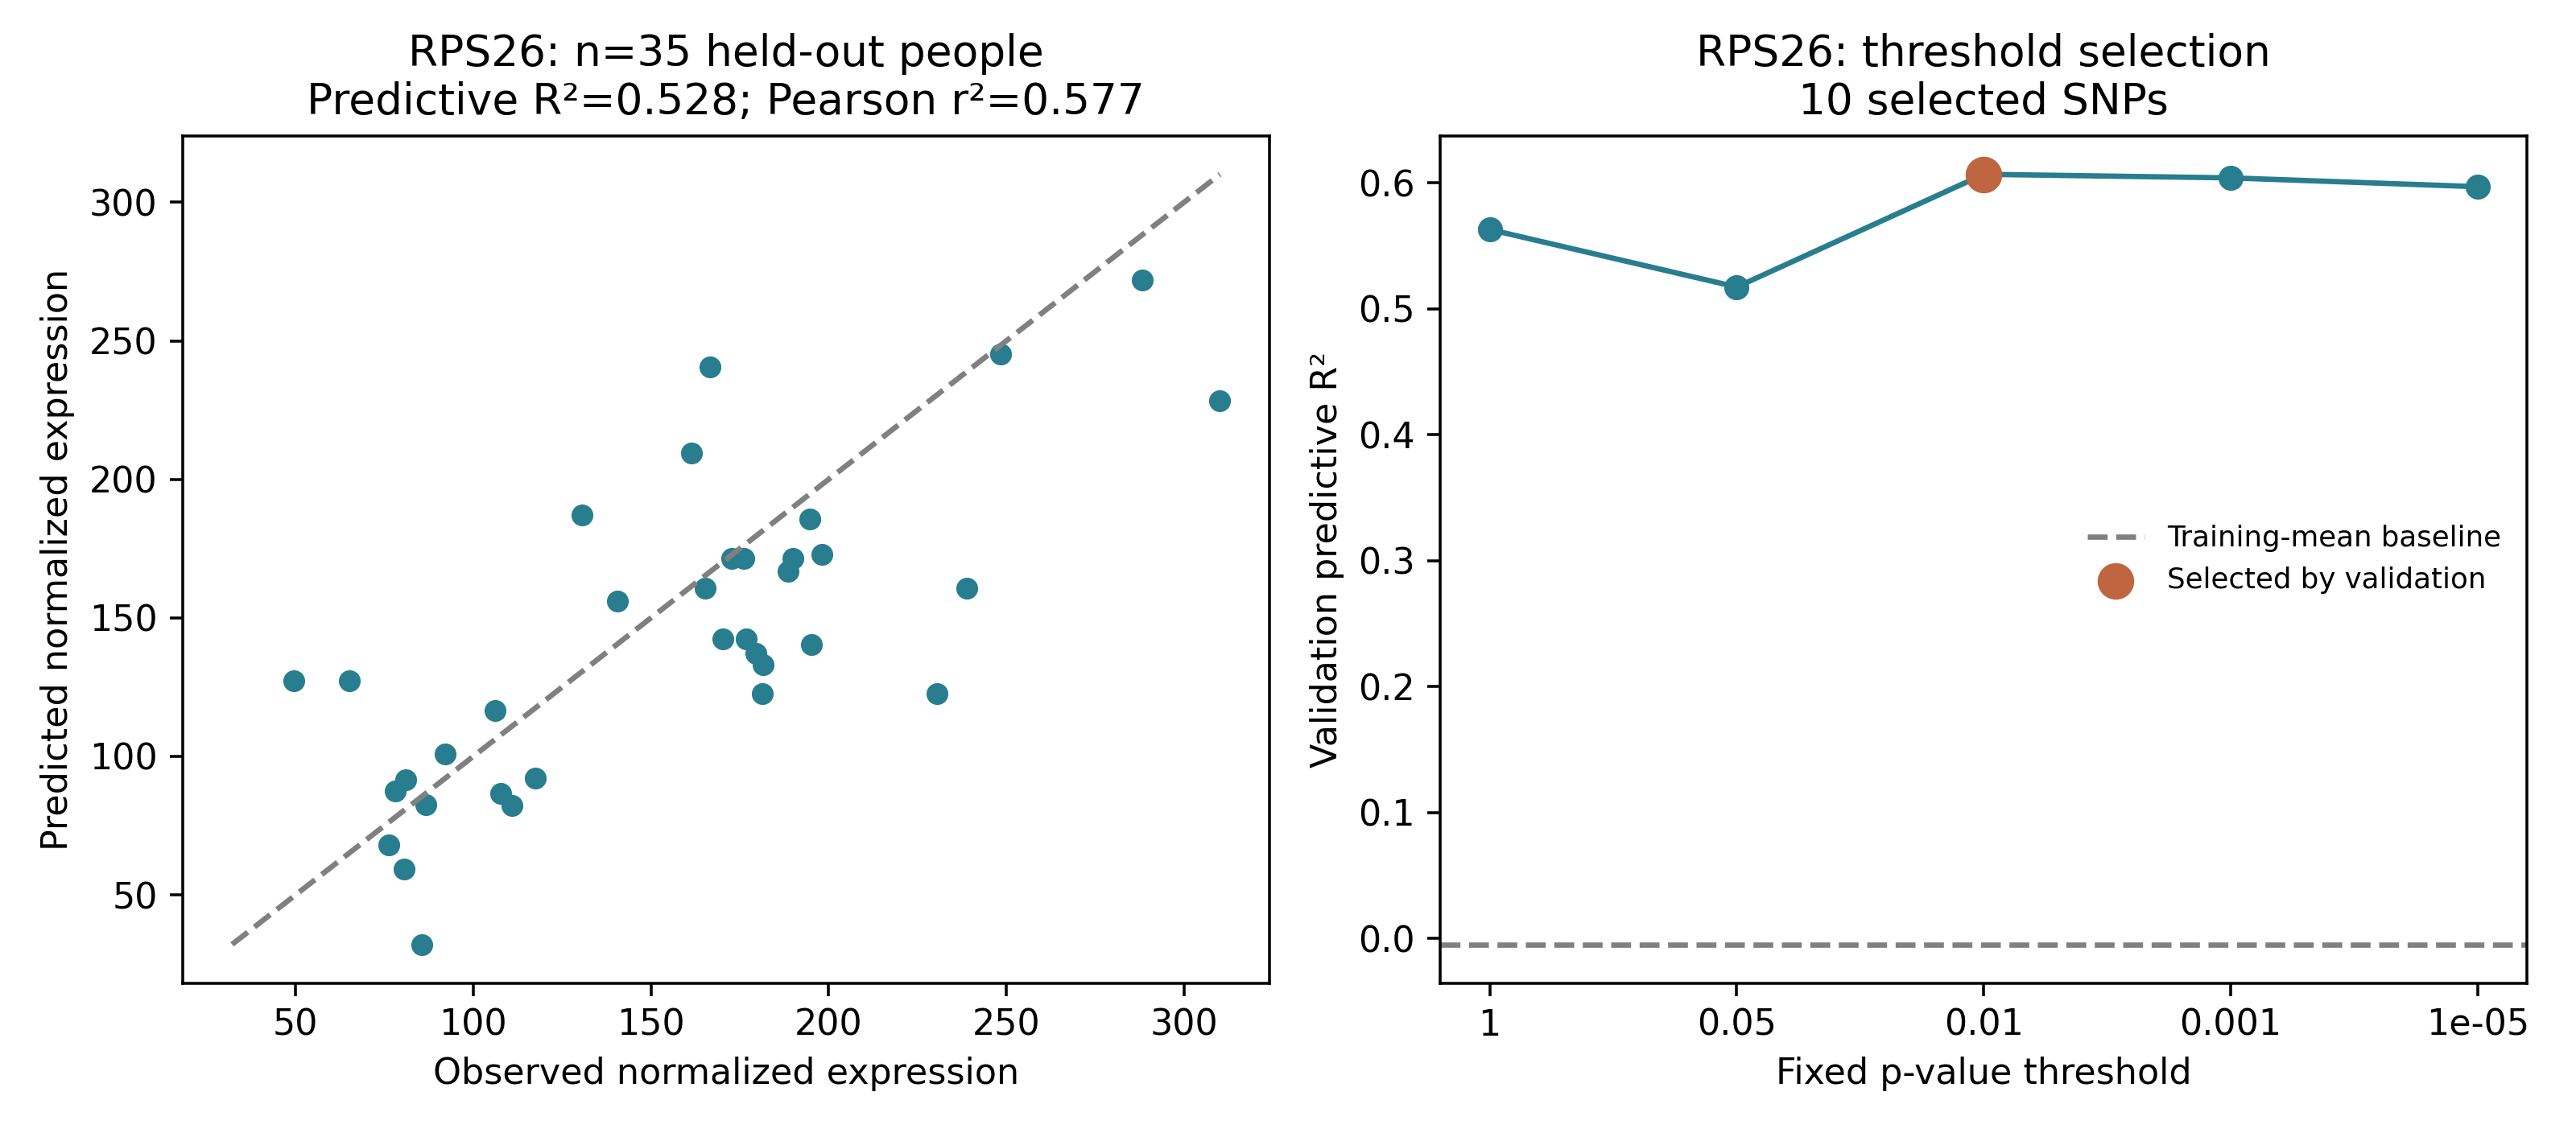

In [2]:
prediction_results = pd.read_csv(pilot / 'gene_prediction_results.tsv', sep='	')
coding_example = prediction_results.loc[prediction_results['Case_Study']].iloc[0]
display(coding_example[['Gene', 'Gene_ID', 'Eligible_SNPs', 'Clumped_SNPs', 'SNPs',
    'Threshold', 'Validation_Predictive_R2', 'Test_Predictive_R2', 'Test_Pearson_r',
    'Test_Pearson_r_squared', 'Baseline_Test_R2']].to_frame('Result'))
display(pd.read_csv(pilot / 'case_study/validation.tsv', sep='	')
        [['Threshold', 'SNPs', 'Predictive_R2', 'Pearson_r_squared', 'Status']])
display(Image(filename=str(pilot / 'figures/single_gene_prediction.png'), width=1000))

## Part 1: Genome-Wide Expression Prediction Exploration

This is a **150-gene pilot**, not a completed genome-wide prediction run. A reproducible
660-gene candidate pool spans all 22 autosomes, gene length, local SNP density and training
expression variability. Training min p defines strong (<10⁻⁸), moderate ([10⁻⁸,10⁻³)) and
weak (≥10⁻³) evidence. The pilot has 44 strong (every strong candidate in the pool),
52 moderate and 54 weak genes across all 22 autosomes. Genes were not selected using
validation or test prediction outcomes. This corrected pilot (`pilot150_v2`) replaces
`pilot150`, whose sampler visited chromosomes in string order and drew its moderate and weak
genes almost entirely from chromosomes 1, 10, 11 and 12; that run is kept frozen but not
reported. One gene (EPCAM, R² = −13.0) dominates the mean, so the median is the better
summary. This stratified
pilot is deliberately enriched by evidence class; its average is not a genome-wide estimate.

All genes share the same split. Full-sample eQTL betas are not reused. Genotype exports and
training-only computations are cached; per-gene models are frozen before final evaluation.
Negative test R² values and failures to beat the training-mean baseline are retained.

,Held-out result
Cohort_Genes,150.000000
Nonempty_Models_Evaluated,150.000000
No_Genetic_Model,0.000000
Mean_Test_Predictive_R2,-0.127580
Median_Test_Predictive_R2,-0.030812
Minimum_Test_Predictive_R2,-13.019680
Percent_Positive_R2,42.666667
Percent_Beating_Training_Mean,50.000000
R2_Above_0_1,29.000000
R2_Above_0_3,6.000000


,Evidence,Genes,Mean_R2,Median_R2,Percent_Positive,Percent_Beating_Baseline
0,Moderate,52,-0.3470,-0.0584,34.6154,40.3846
1,Strong,44,0.1092,0.1175,75.0000,84.0909
2,Weak,54,-0.1093,-0.0756,24.0741,31.4815


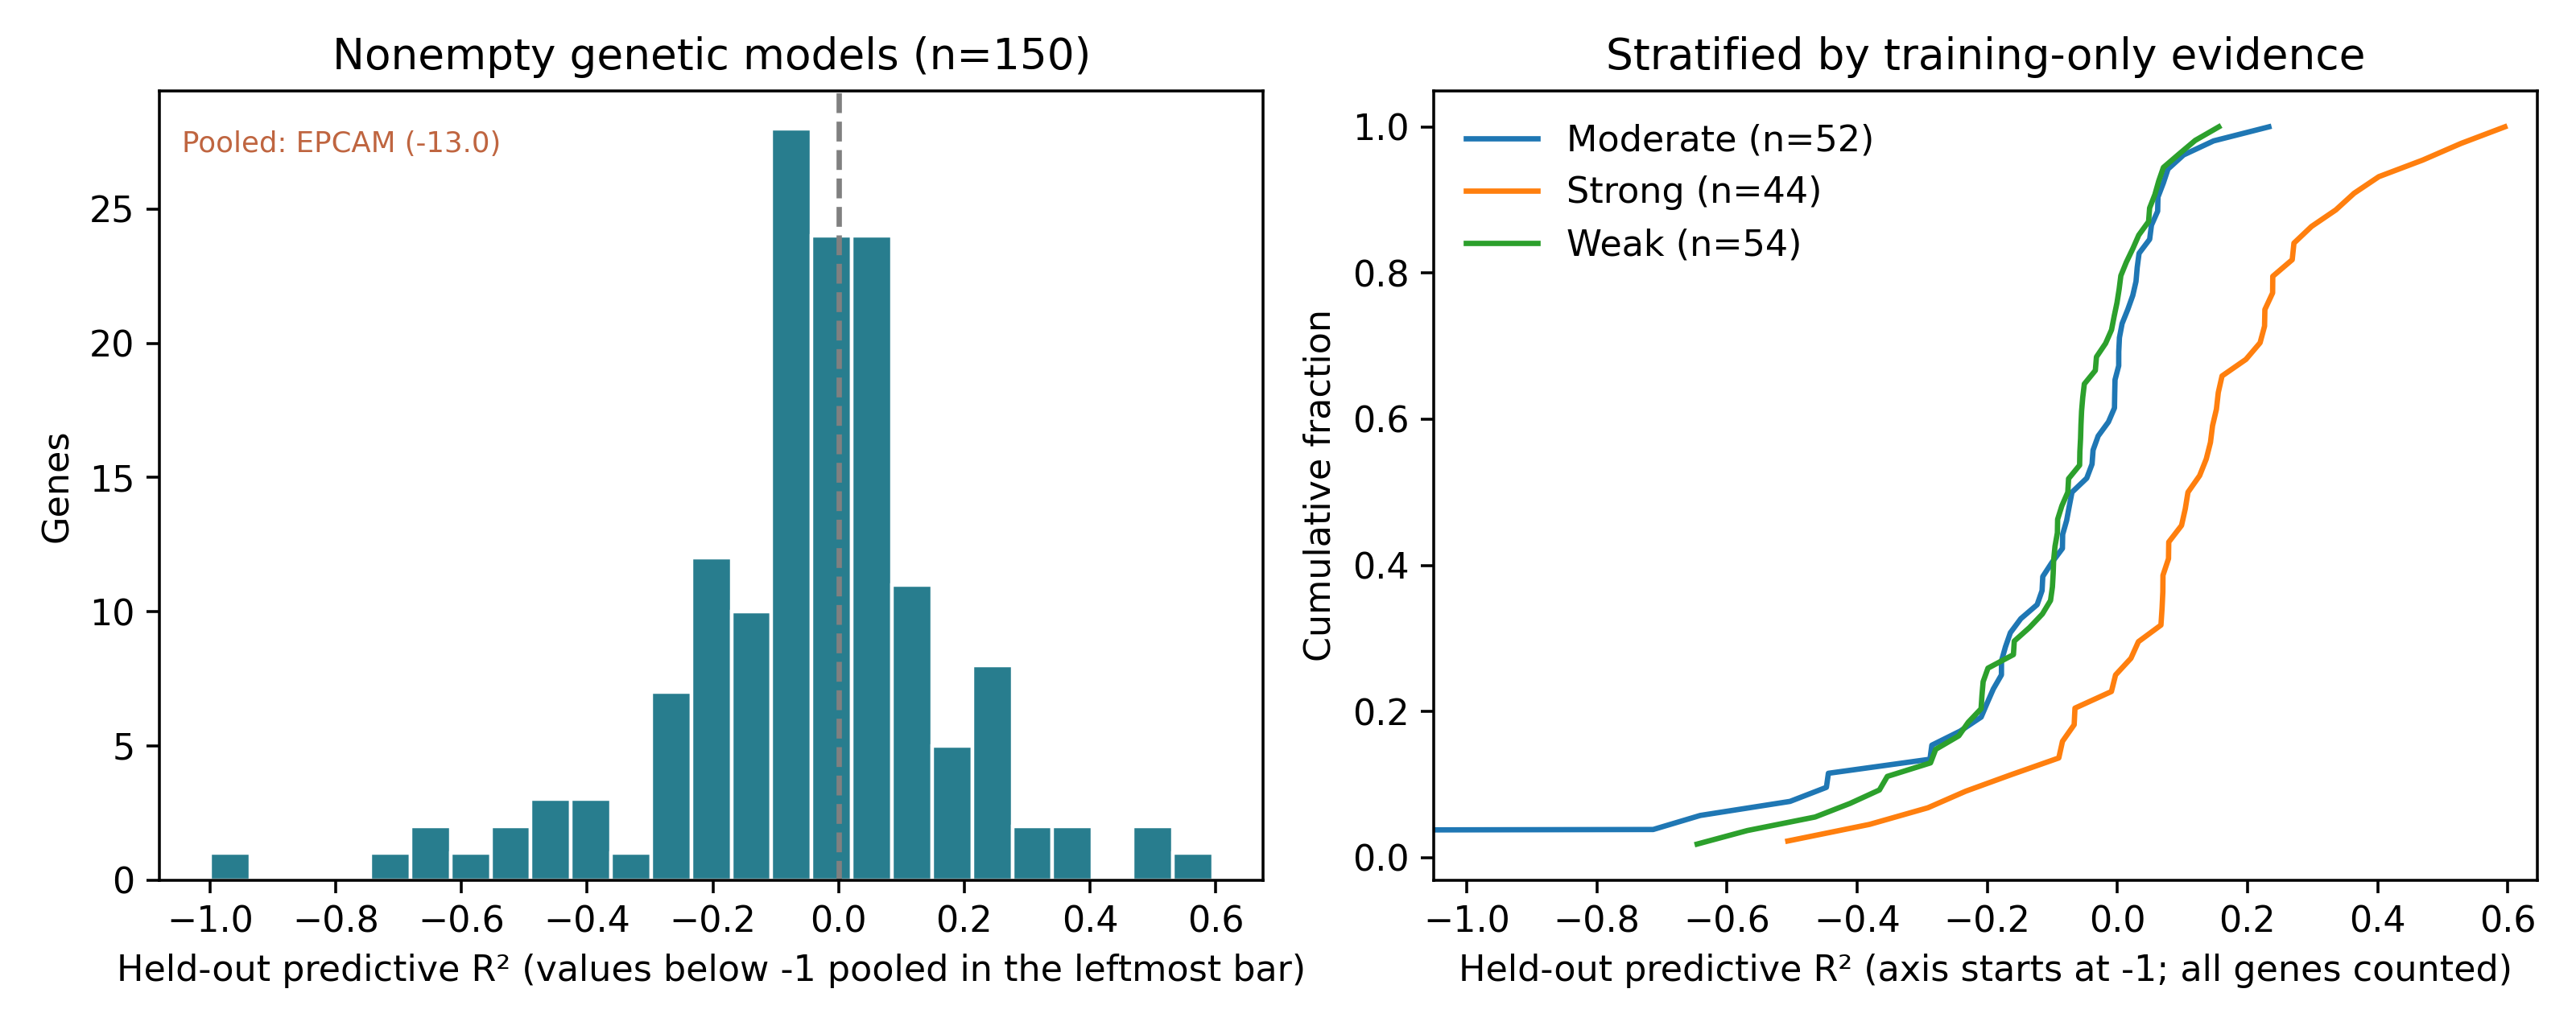

In [3]:
pilot_summary = json.loads((pilot / 'performance_summary.json').read_text())
display(pd.Series(pilot_summary, name='Held-out result').to_frame())
display(pd.read_csv(pilot / 'performance_by_training_evidence.tsv', sep='	').round(4))
display(Image(filename=str(pilot / 'figures/predictive_r2_distribution.png'), width=1000))

### What is associated with prediction accuracy?

Training association strength, SNP counts, gene length, density and training expression
variability are explored below. Every association-strength value is from **training only**.
Selected SNP count is influenced by the validation-selected threshold; its relationship
with test accuracy is not a causal effect of adding SNPs. Feature associations and BH
q-values are exploratory across related genes, not independent confirmatory findings.

,Feature,Genes,Spearman_R,P,BH_Q_Exploratory
0,Training_Signal_MinusLog10P,150,0.46470,0.00000,0.00000
1,Eligible_SNPs,150,0.00288,0.97206,0.97206
2,Clumped_SNPs,150,-0.03924,0.63354,0.90143
3,SNPs,150,-0.12769,0.11944,0.31054
4,Gene_Length,150,-0.01746,0.83208,0.90143
5,SNPs_Per_Mb,150,0.01854,0.82186,0.90143
6,Training_Expression_SD,150,0.02194,0.78989,0.90143
7,Training_Gene_Bonferroni_Hits,150,0.51653,0.00000,0.00000
8,Eligible_ATAC_Fraction,150,0.04766,0.56245,0.90143
9,Training_Significant_ATAC_SNPs,150,0.40303,0.00000,0.00000


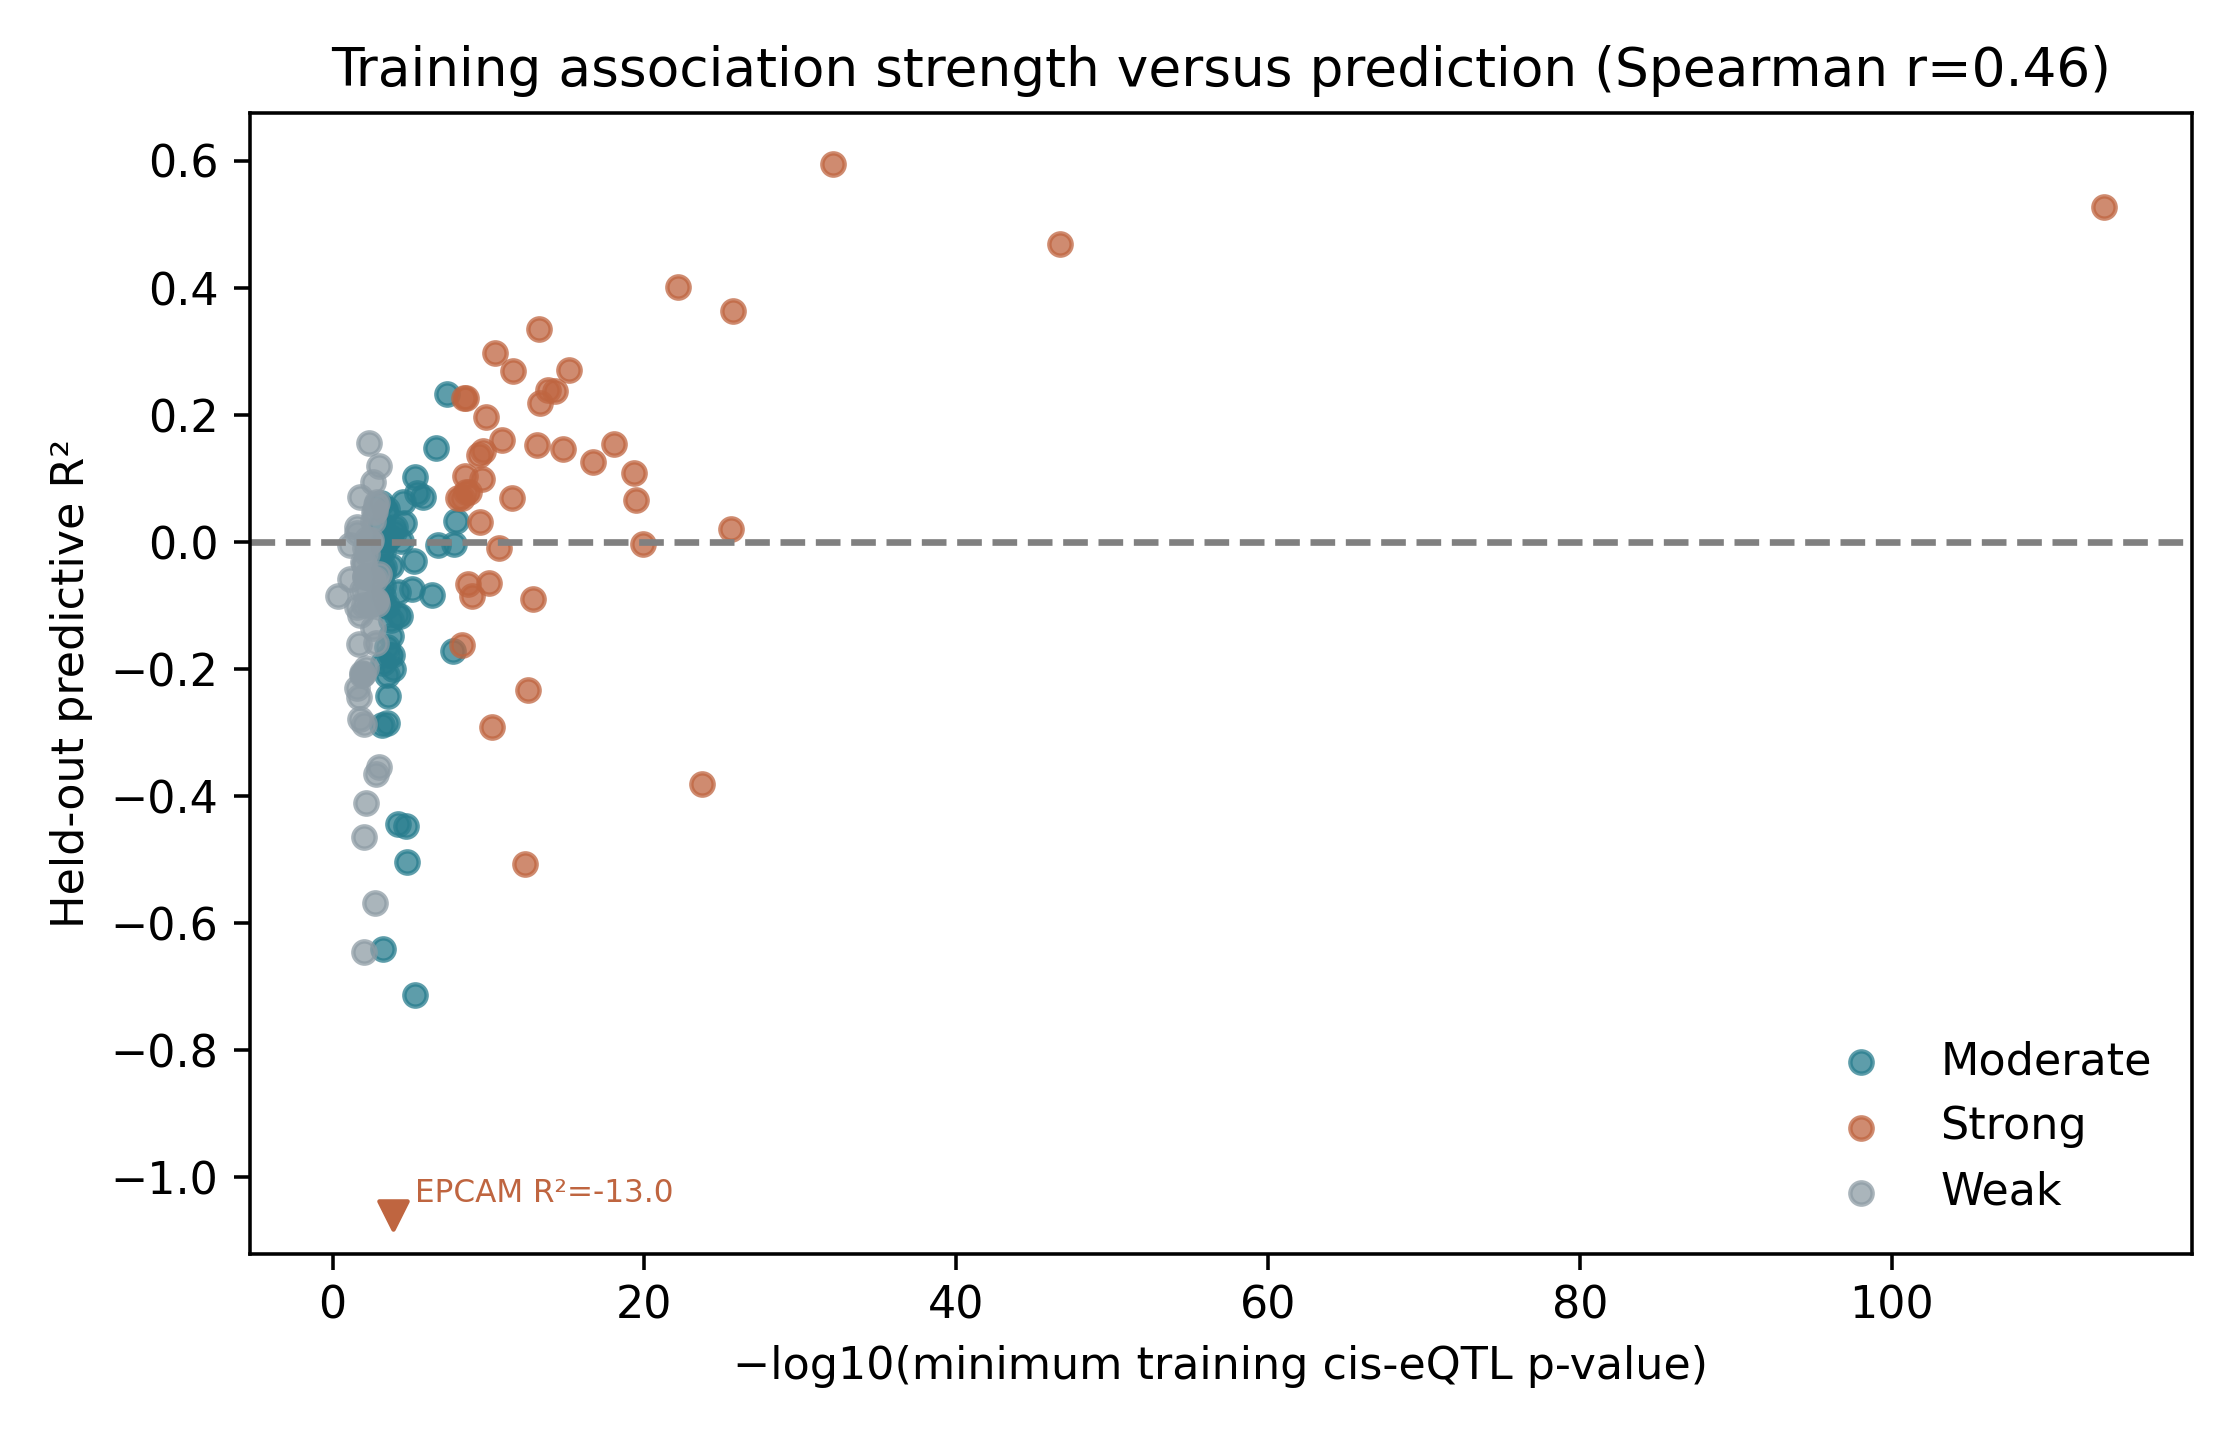

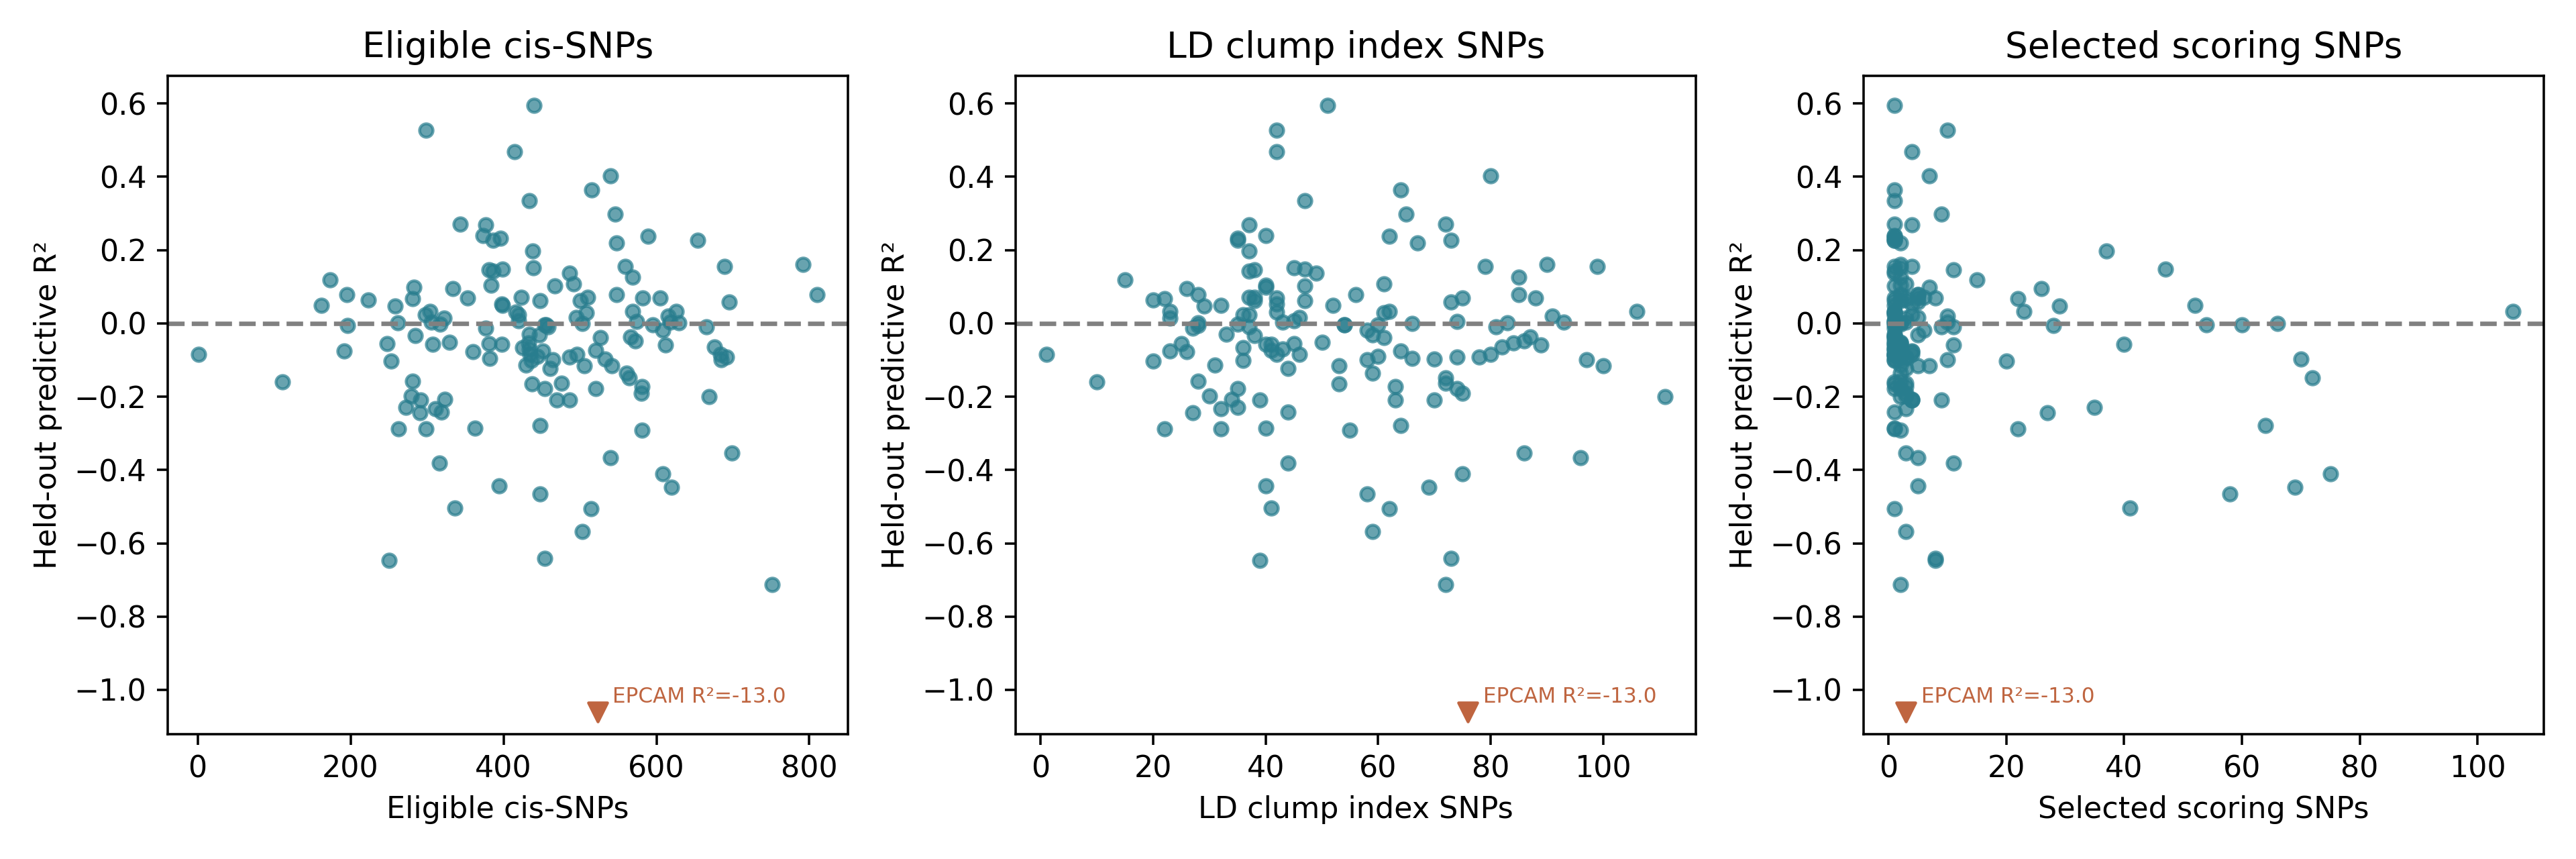

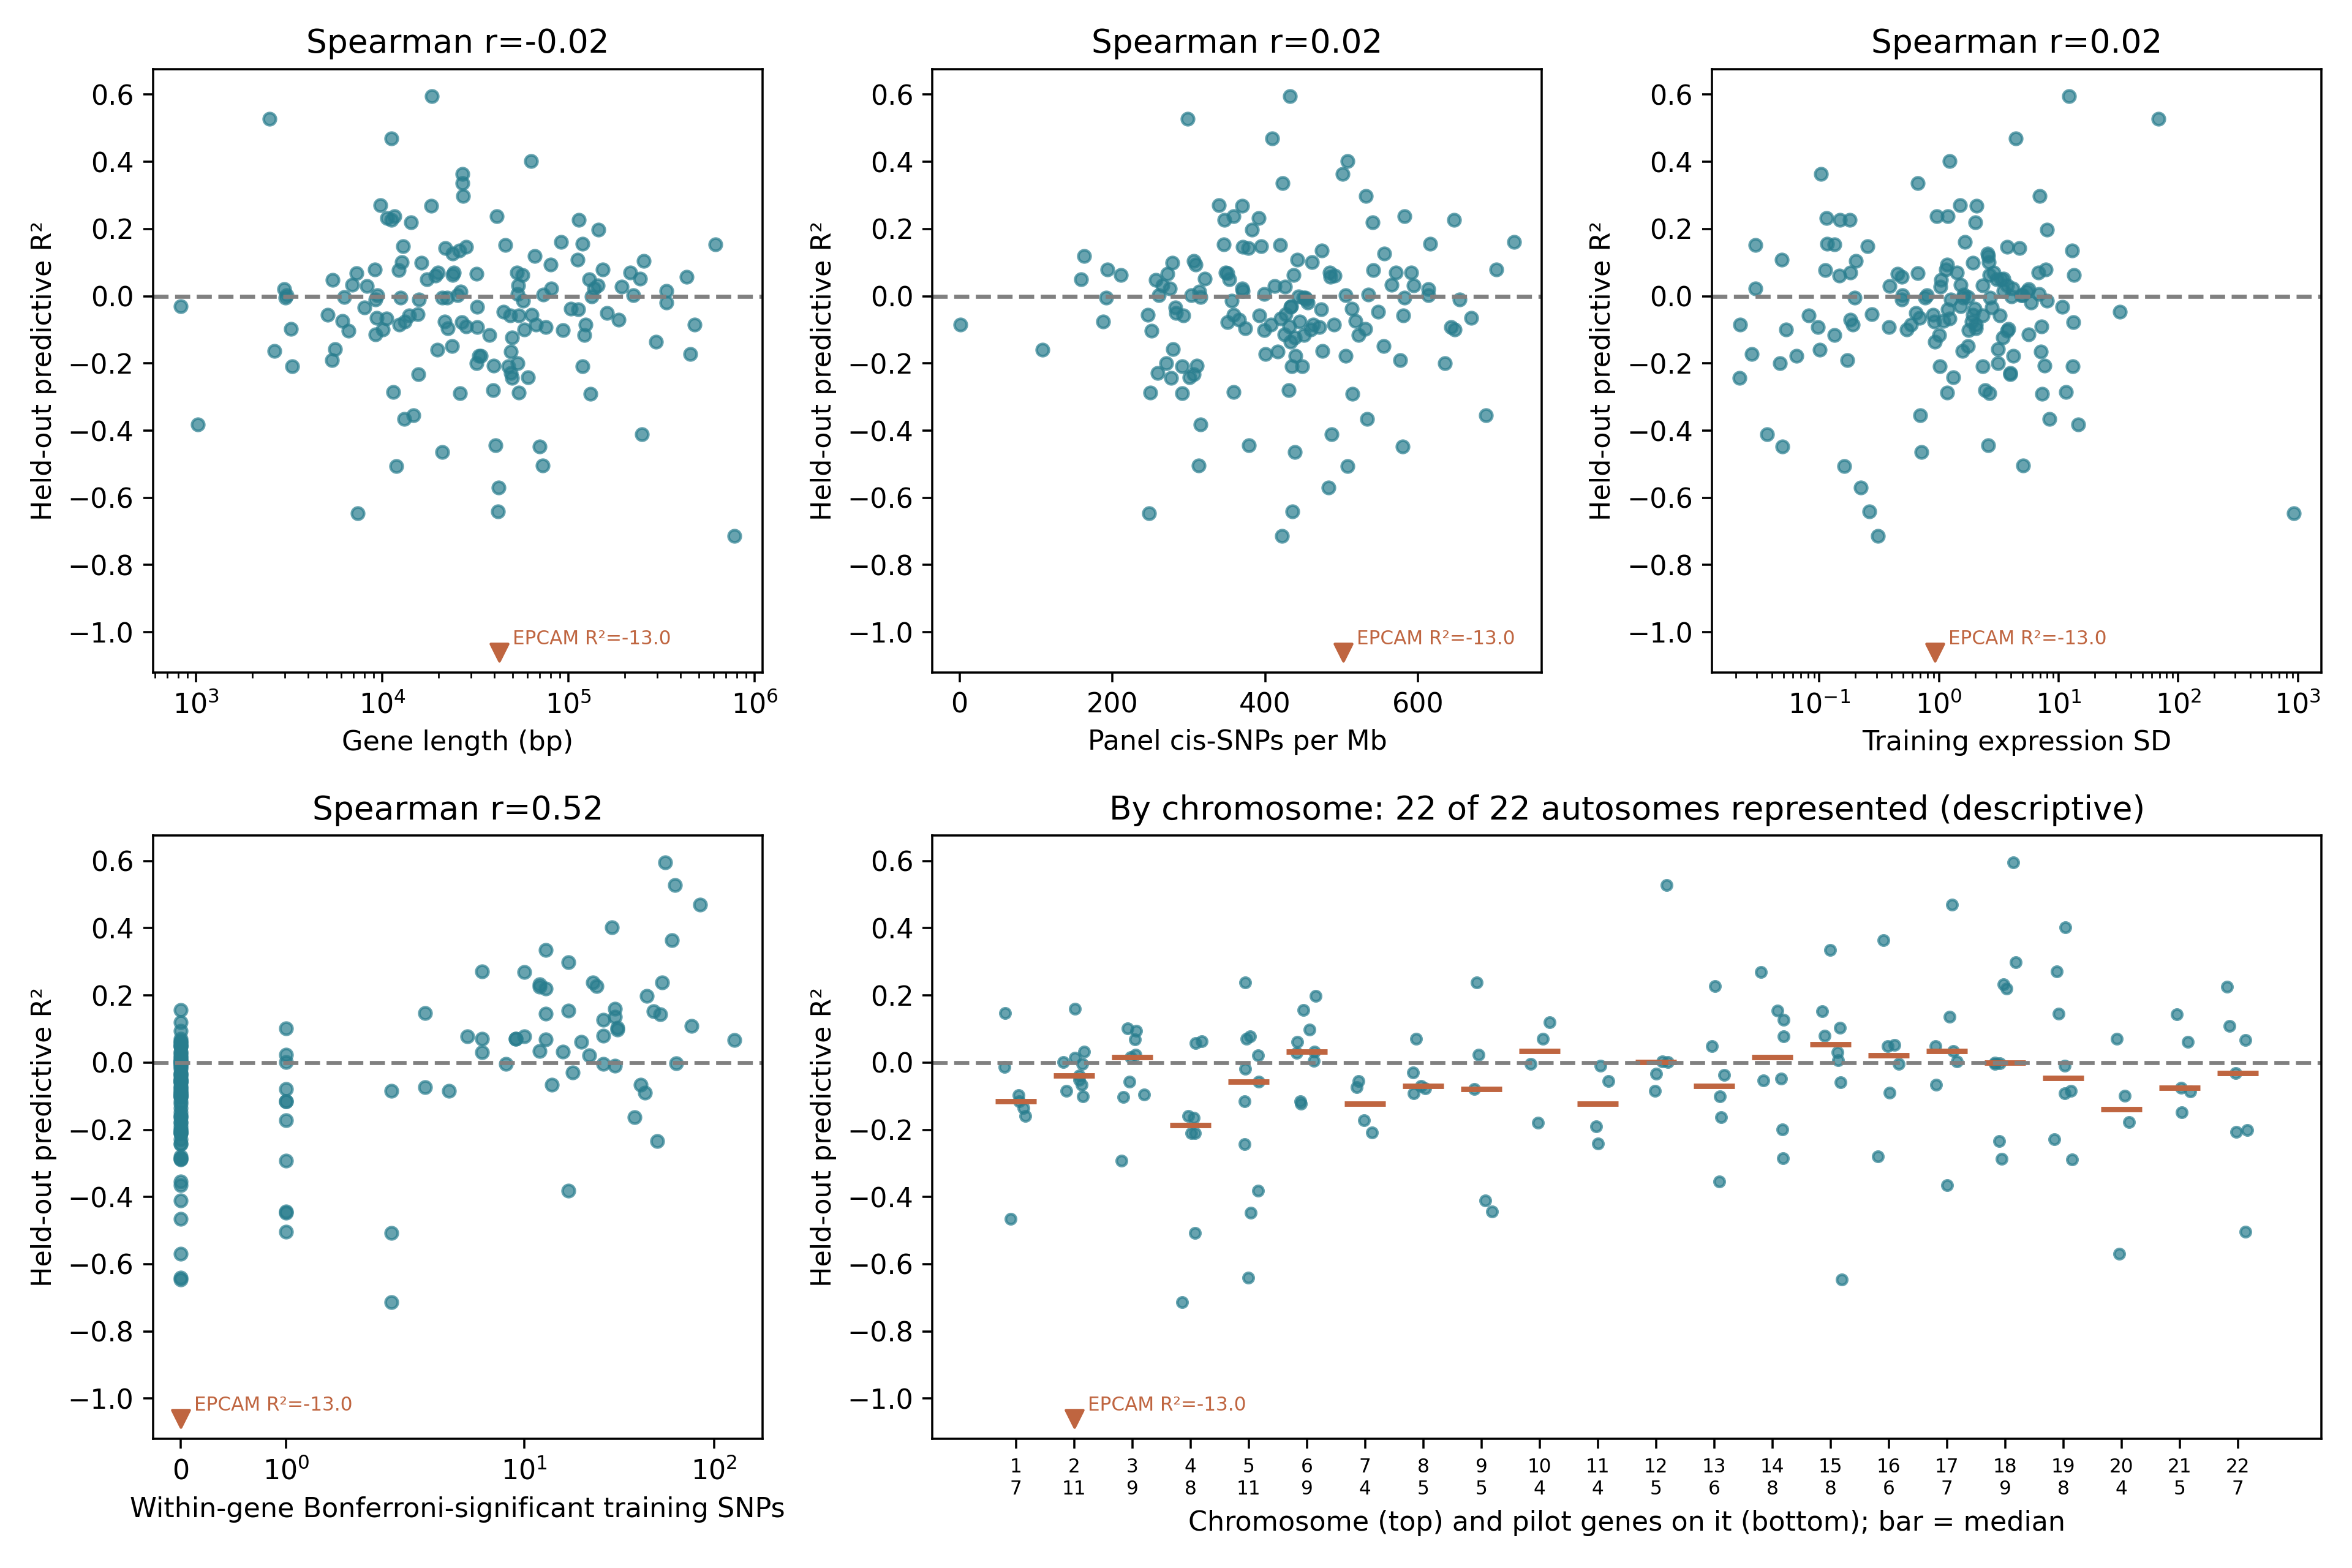

In [4]:
feature_associations = pd.read_csv(pilot / 'feature_performance_associations.tsv', sep='	')
display(feature_associations.round(5))
display(Image(filename=str(pilot / 'figures/association_strength_vs_prediction.png'), width=850))
display(Image(filename=str(pilot / 'figures/snp_counts_vs_prediction.png'), width=1100))
display(Image(filename=str(pilot / 'figures/gene_characteristics_vs_prediction.png'), width=1100))

### Prediction and B-cell accessible chromatin

Week 7's GRCh37 accessibility annotations are reused for training-eligible and selected
SNPs. The count of significant training variants uses a **within-gene Bonferroni** family,
distinct from the original genome-wide discovery correction. Counts can be confounded
by gene length, SNP density, LD and training signal strength. An additional residual
sensitivity controls measured locus/expression characteristics. Neither overlap nor a
performance association demonstrates a regulatory mechanism; primary B cells differ from LCLs.

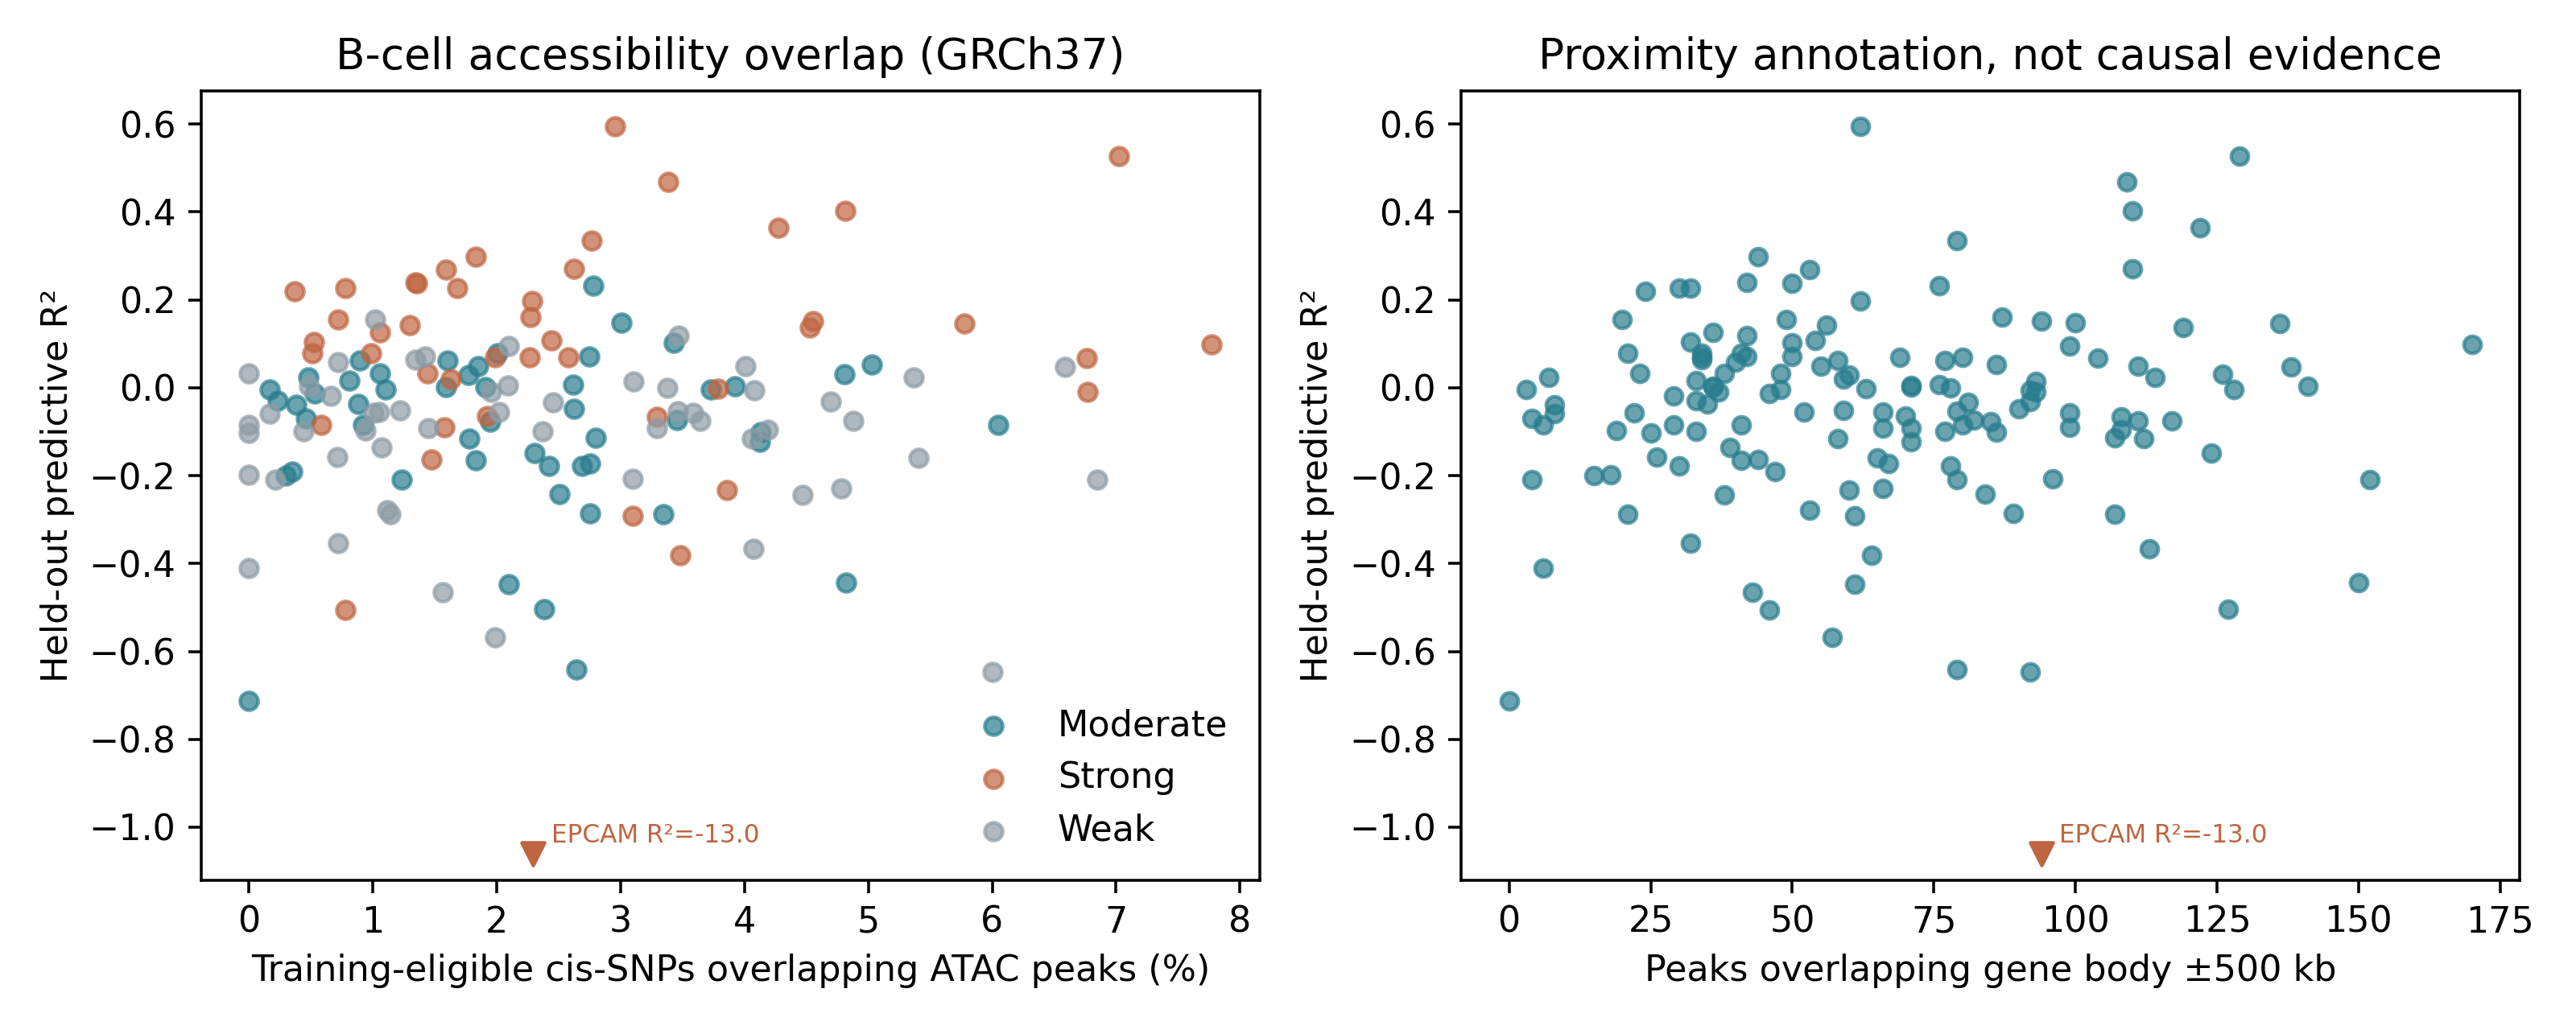

,Exploratory adjusted comparison
Genes,150
Residual_Pearson_R,-0.012598
Controls,"log gene length, log eligible SNP count, log t..."
Interpretation,Exploratory residual association; not proof of...


In [5]:
display(Image(filename=str(pilot / 'figures/atac_vs_prediction.png'), width=1000))
display(pd.Series(json.loads((pilot / 'atac_adjusted_sensitivity.json').read_text()),
                  name='Exploratory adjusted comparison').to_frame())

### Verification and the optional full-genome run

The model/threshold manifest was written before test evaluation. Rerunning evaluation
loads saved results rather than revisiting model selection. The supplied expression was
already normalized before this split; upstream PEER normalization was not refitted within
training. With 35 test people, per-gene R² estimates are noisy and are not clinical evidence.

The resource estimate below is a conservative extrapolation, not a full-run benchmark.
**No full 14,661-gene prediction run has been launched.** The CLI processes chromosomes
and supports `--max-models` batches and per-gene resume checkpoints. Run commands and
limitations are in `docs/expanded_prediction_methods_results.md`.

In [6]:
prediction_checks = pd.read_csv(pilot / 'verification_checks.tsv', sep='	')
print('Models passing every saved verification check:',
      int(prediction_checks.drop(columns='Gene_ID').all(axis=1).sum()), '/', len(prediction_checks))
display(pd.Series(json.loads((pilot / 'genomewide_resource_estimate.json').read_text()),
                  name='Planning estimate').to_frame())

Models passing every saved verification check: 150 / 150


,Planning estimate
Pilot_Fit_Seconds,15.828684
Pilot_Test_Seconds,1.340452
Genes_In_Full_Target,14661
Projected_Full_Run_Minutes,27.968522
Planning_Range_Minutes,"[13.984261000894358, 55.937044003577434]"
Genotype_Cache_MB,452.183473
Peak_RAM_Measured,False
Memory_Strategy,One chromosome at a time; int8 dosage cache wi...
Projected_Models_And_Associations_MB,918.960987
Method,Linear extrapolation; 0.5x–2x planning range. ...


## Part 2 — Disease Polygenic Scores and Reference Structure

### How the analyses connect: two different kinds of beta

**Part 1 asks which nearby SNPs are associated with a gene's expression.** For each
eligible protein-coding gene across chromosomes 1–22, we fit a separate linear regression
for each SNP in the gene body ±500 kb:

$$E_{ig}=\alpha_{jg}+\beta^{\mathrm{eQTL}}_{jg}G_{ij}+\epsilon_{ijg}.$$

Here, $G_{ij}$ is person $i$'s dosage of the counted allele at SNP $j$, and $E_{ig}$ is
the supplied normalized expression for gene $g$. Each eQTL beta measures an expression
change per additional counted allele. The scan produces SNP–gene effects, p-values and
genome-wide multiple-testing corrections. It does not estimate disease effects.

**Week 4 used training-derived eQTL betas for an expression prediction exercise.** After
SNP selection, an expression score $S_{ig}=\sum_j\hat\beta^{\mathrm{eQTL}}_{jg}G_{ij}$
was calibrated on training data and evaluated with separate validation/test individuals.
This explains the remembered connection between our regressions and a weighted score.
That score predicts expression; those weights are not used for the Part 2 disease PRSs.

**Part 2 asks where a person's disease-associated genetic score falls in a reference group.**
Published disease GWASs already estimated allele effects using disease phenotypes. We
reuse documented log-odds betas (or convert documented odds ratios using $\beta=\ln(OR)$),
align the effect alleles to the genotypes, clump correlated SNPs and retain p≤0.001:

$$\mathrm{PRS}_{id}=\sum_{j\in J_d}\hat\beta^{\mathrm{GWAS}}_{jd}G^{\mathrm{effect}}_{ij}.$$

The genotype dosage is 0, 1 or 2 copies of the named effect allele. These weights come from
original RA, T2D and schizophrenia studies, not the original Z-only TCSC files and not our
Part 1 expression regressions. We do not fit a disease model on the reference individuals,
because disease outcomes are not available for this analysis.

Part 2 returns a raw PRS, reference mean/SD, a z-score and a reference percentile for a
comparison individual. We also examine cross-disease score correlations, selected-SNP
overlap, population PCs and changes after PC adjustment. A percentile is a rank among
the comparison people; neither a percentile nor the raw sum is a calibrated probability
of disease. Private comparisons use the same compatible SNP subset for target and reference.

**Week 7 adds biological context to Part 1.** It checks whether eQTL SNPs and gene regions
overlap B-cell accessible chromatin. It does not change PRS weights or establish a causal
chain from a SNP through expression to disease. Demonstrating that chain would require
additional analyses and evidence beyond this project.

### Disease PRS data and scoring choices

The original TCSC files contained Z-scores rather than usable PRS betas and were removed after inventorying at the user's request. The verified original
GWASs and selection reasons are listed below. All analyses use a fixed p≤0.001 cutoff,
EUR LD clumping (r²=0.1, 250 kb), GRCh37 coordinates, and allele-aligned log-odds weights.
Raw scores, reference-standardized scores, and percentiles describe different quantities;
none is a calibrated disease probability. The working notebook displays the local target comparisons below.

The public PCA uses QC-filtered, LD-pruned autosomal genotypes. PCs describe within-EUR
structure; clusters are unlabeled because validated population metadata were not supplied.
PC adjustment is an exploratory sensitivity analysis. Correlations and SNP overlap do not
establish causality, pleiotropy, or a shared disease mechanism.

Run `scripts/run_disease_prs.py`, `scripts/run_pca.py` and `scripts/analyze_prs.py` from the
repository root to recreate the results. These cells read saved outputs and do not refit Part 1.

### Public reference PRSs

This copy displays reference results only. Tiffany's values, personal plots and local
report cells are available in the working `quarter1_project.ipynb`, not this public copy.
The full-reference scores below use each disease's complete selected panel SNP set;
the working target comparisons instead use matched shared SNP subsets.

,Slug,Disease,Accession,Source,File,Effect,N,Ancestry,Assembly,Justification,SHA256
0,rheumatoid_arthritis,Rheumatoid arthritis,GCST005569,Eyre et al. 2012; PMID 23143596,GCST005569.Build37.f.tsv.gz,log(OR),47580,European,GRCh37 (formatted file; not GRCh38 .h file),"Documented effect/other alleles, ORs, GRCh37 p...",5372a325f1912dd1b6e42531b786e50b520686210d05b4...
1,type2_diabetes,Type 2 diabetes,GCST007517,Mahajan et al. 2018; PMID 29632382,GCST007517.Build37.f.tsv.gz,log-odds beta,298957,European,GRCh37 (formatted file; not GRCh38 .h file),European BMI-unadjusted exome-array analysis w...,09185f4b652e0c4fa1f27147d4b54dabbb0fc5b5af673f...
2,schizophrenia,Schizophrenia,CLOZUK+PGC2 2018,Pardiñas et al. 2018; PMID 29483656,GCST006803.txt.gz,log(OR),105318,European,GRCh37: verified panel rsID anchors,"Author-documented A1 effect allele, A2 other a...",2535a277786c2558eef7462ba6fc342a7af0b4aee79dfb...


,Disease,Original_SNPs,Harmonized_SNPs,Scored_SNPs,Individuals,Mean,SD,Median,Q1,Q3,IQR,P_Threshold,Clump_R2,Clump_KB,Assembly
0,Rheumatoid arthritis,129273,50503,229,489,-0.058613,2.352272,-0.253392,-1.695393,1.452505,3.147898,0.001,0.1,250,GRCh37
1,Type 2 diabetes,133871,18645,250,489,-0.326182,0.454698,-0.327400,-0.611400,-0.024400,0.587000,0.001,0.1,250,GRCh37
2,Schizophrenia,8171061,1147331,3556,489,-15.668268,2.298137,-15.595339,-16.905952,-14.133782,2.772170,0.001,0.1,250,GRCh37


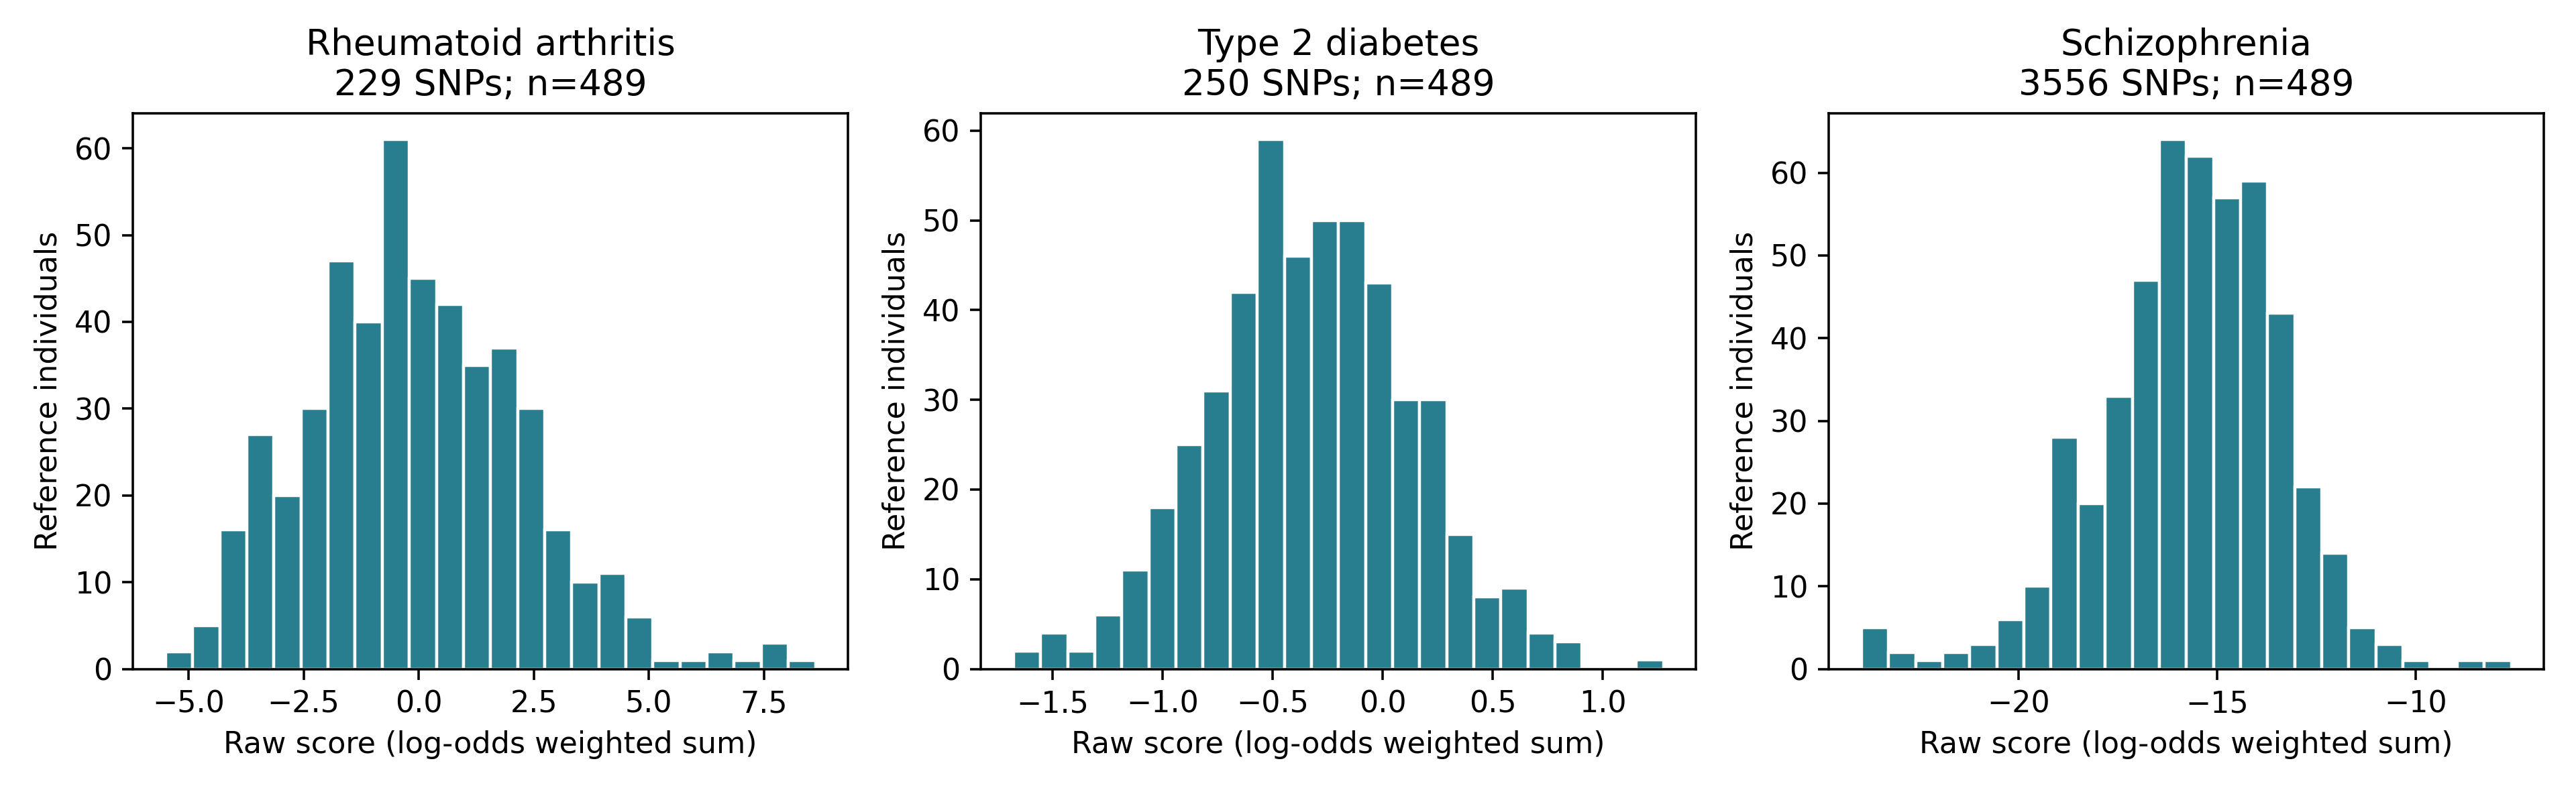

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
report_root = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
if str(report_root) not in sys.path:
    sys.path.insert(0, str(report_root))
part2 = report_root / 'results/part2'
display(pd.read_csv(part2 / 'selected_diseases.tsv', sep='\t'))
display(pd.read_csv(part2 / 'prs_summary.tsv', sep='\t'))
display(Image(filename=str(part2 / 'figures/prs_distributions.png'), width=1000))

### Exploratory reference analysis — disease PRS correlations

**This was the second plot in the earlier notebook.** It compares the full-reference
disease scores across the same reference people; it is not a plot of Tiffany's scores.
Each square is a Pearson correlation between two disease scores. Positive values mean
people with higher scores for one disease tend to have higher scores for the other;
negative values mean the opposite. Values near zero indicate little linear association.
The diagonal is 1 because each score is compared with itself.

The table also reports Spearman rank correlations and PC1–PC2-adjusted correlations.
SNP overlap, LD, population structure and GWAS effect estimates can influence these
relationships. A correlation does not show that one disease causes another.

,Disease_A,Disease_B,Individuals,SNPs_A,SNPs_B,Pearson_R,Pearson_P,Spearman_R,Spearman_P,PC1_PC2_Adjusted_R
0,Rheumatoid arthritis,Type 2 diabetes,489,229,250,0.0802,0.0763,0.0340,0.4533,0.1060
1,Rheumatoid arthritis,Schizophrenia,489,229,3556,0.1710,0.0001,0.1645,0.0003,0.1421
2,Type 2 diabetes,Schizophrenia,489,250,3556,-0.0267,0.5561,-0.0339,0.4544,-0.0140


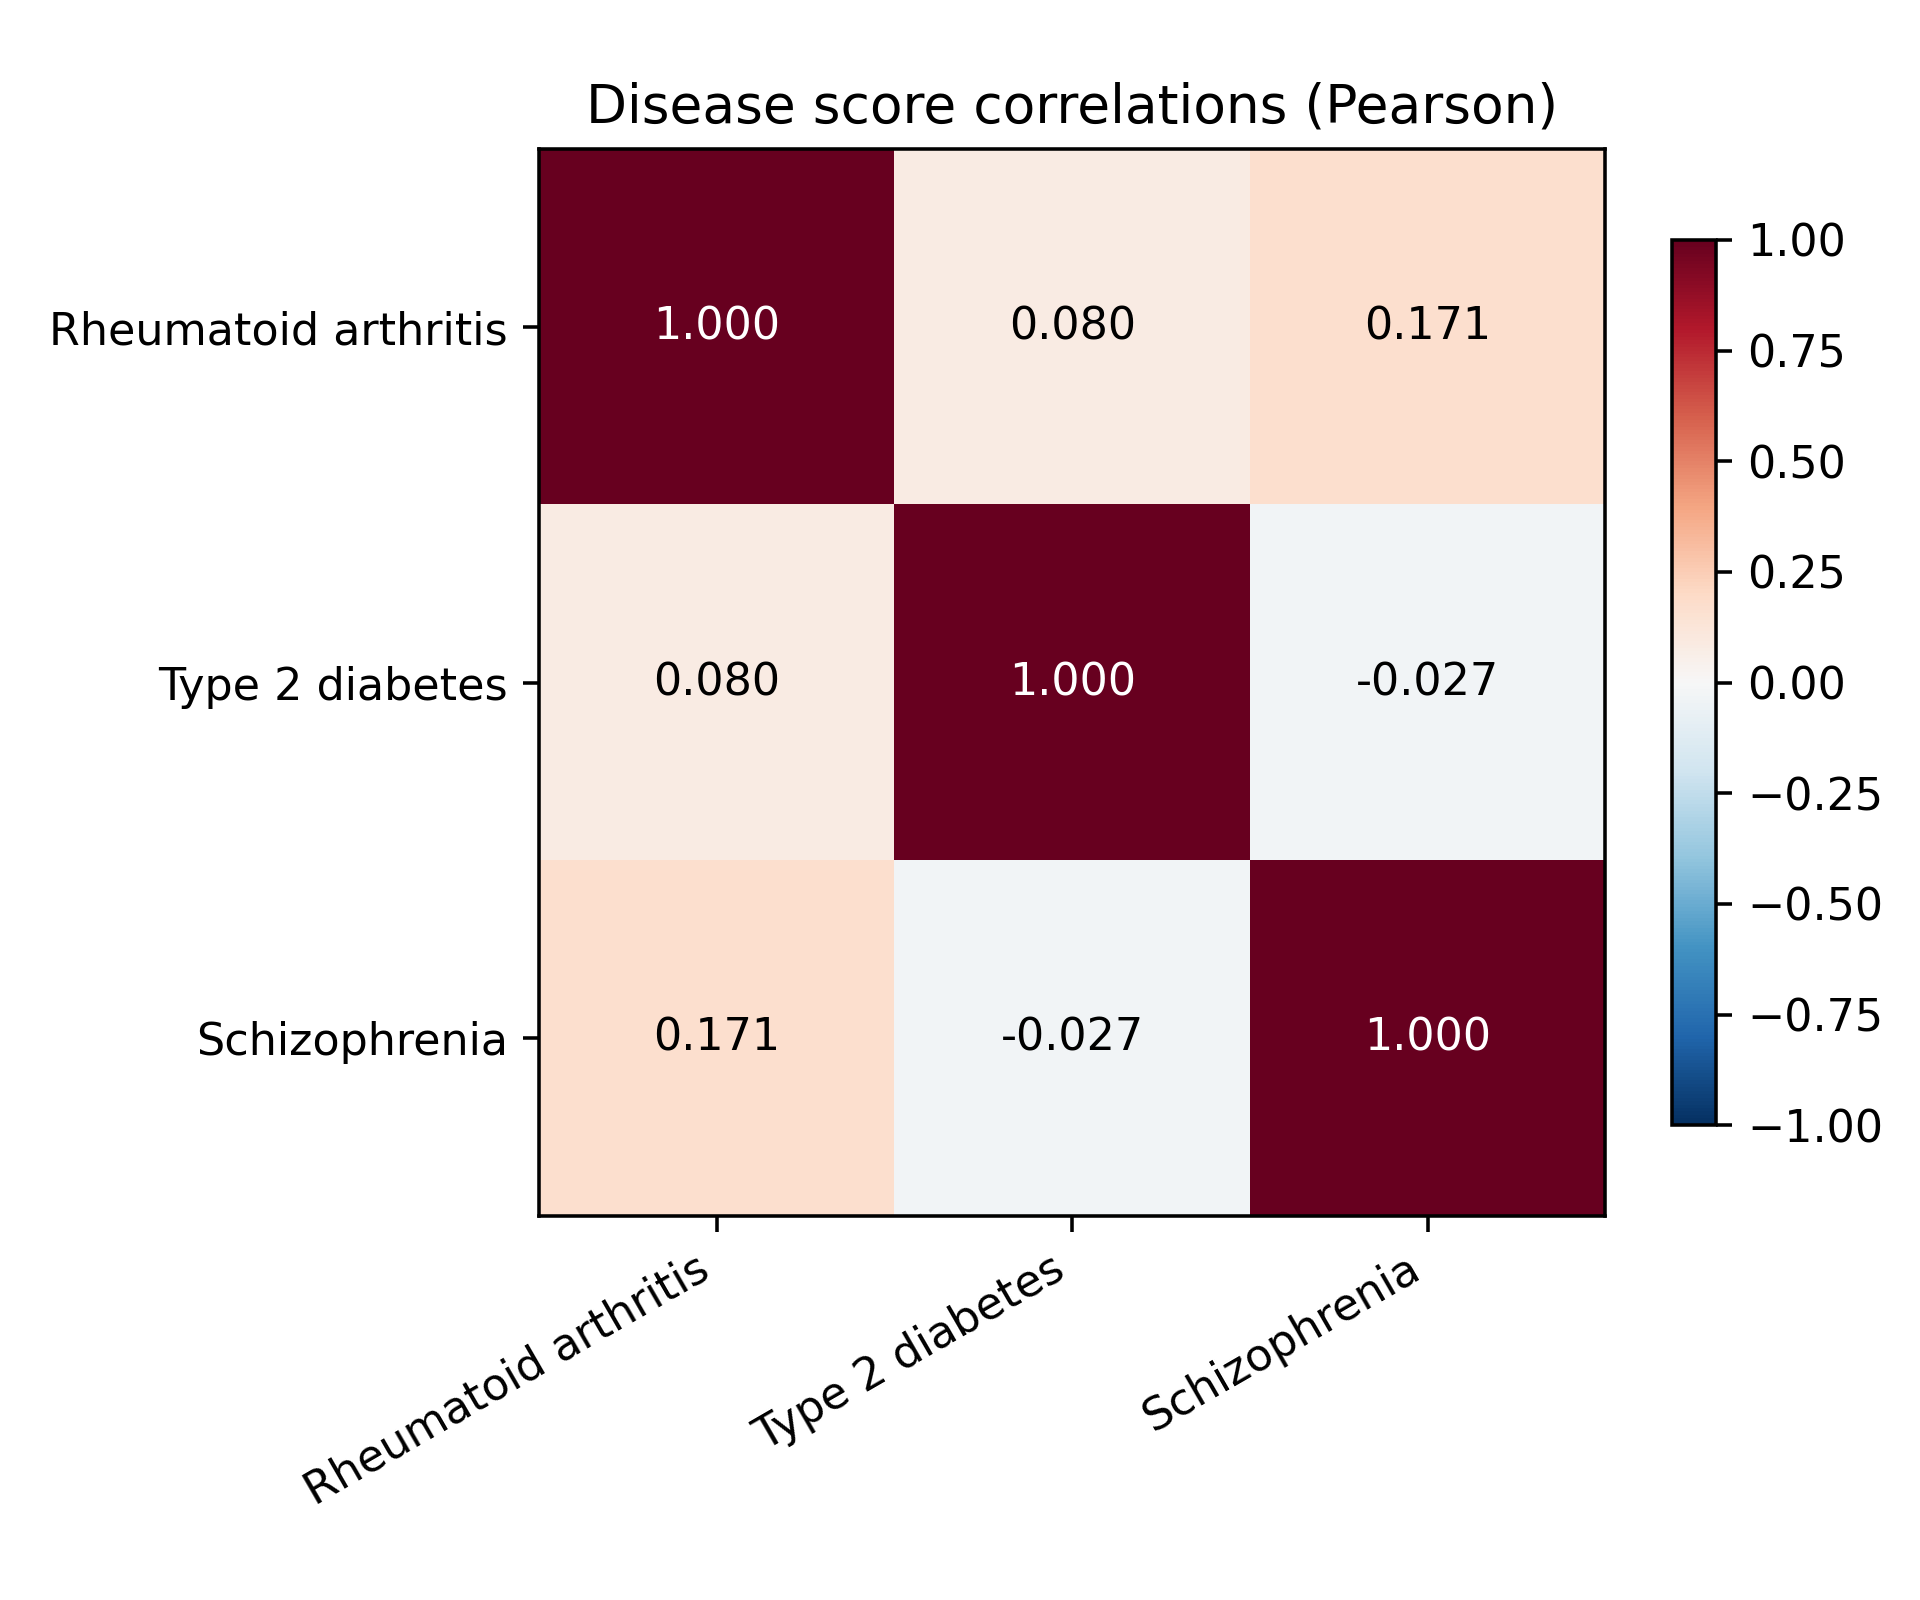

,Disease_A,Disease_B,SNPs_A,SNPs_B,Shared,Fraction_A,Fraction_B,Jaccard
0,Rheumatoid arthritis,Type 2 diabetes,229,250,4,0.0175,0.0160,0.0084
1,Rheumatoid arthritis,Schizophrenia,229,3556,4,0.0175,0.0011,0.0011
2,Type 2 diabetes,Schizophrenia,250,3556,4,0.0160,0.0011,0.0011


In [2]:
display(pd.read_csv(part2 / 'pairwise_correlations.tsv', sep='\t').round(4))
display(Image(filename=str(part2 / 'figures/prs_correlations.png'), width=800))
display(pd.read_csv(part2 / 'snp_overlap.tsv', sep='\t').round(4))

### Exploratory reference analysis — population PCA

**This was the third plot in the earlier notebook.** Each dot is a reference person,
not a disease. PC1 and PC2 summarize genetic differences in LD-pruned autosomal
genotypes; nearby points have similar positions along these two axes. The percentages
on the axes show the fraction of genotype variation explained by each component.

This panel describes structure **within the EUR reference panel**, not worldwide
ancestry. Clusters are unlabeled because validated population labels were unavailable.
Tiffany is not projected onto these PCs. The PRS–PC associations and PC-adjusted score
correlations are exploratory checks, not a correction that eliminates ancestry bias.

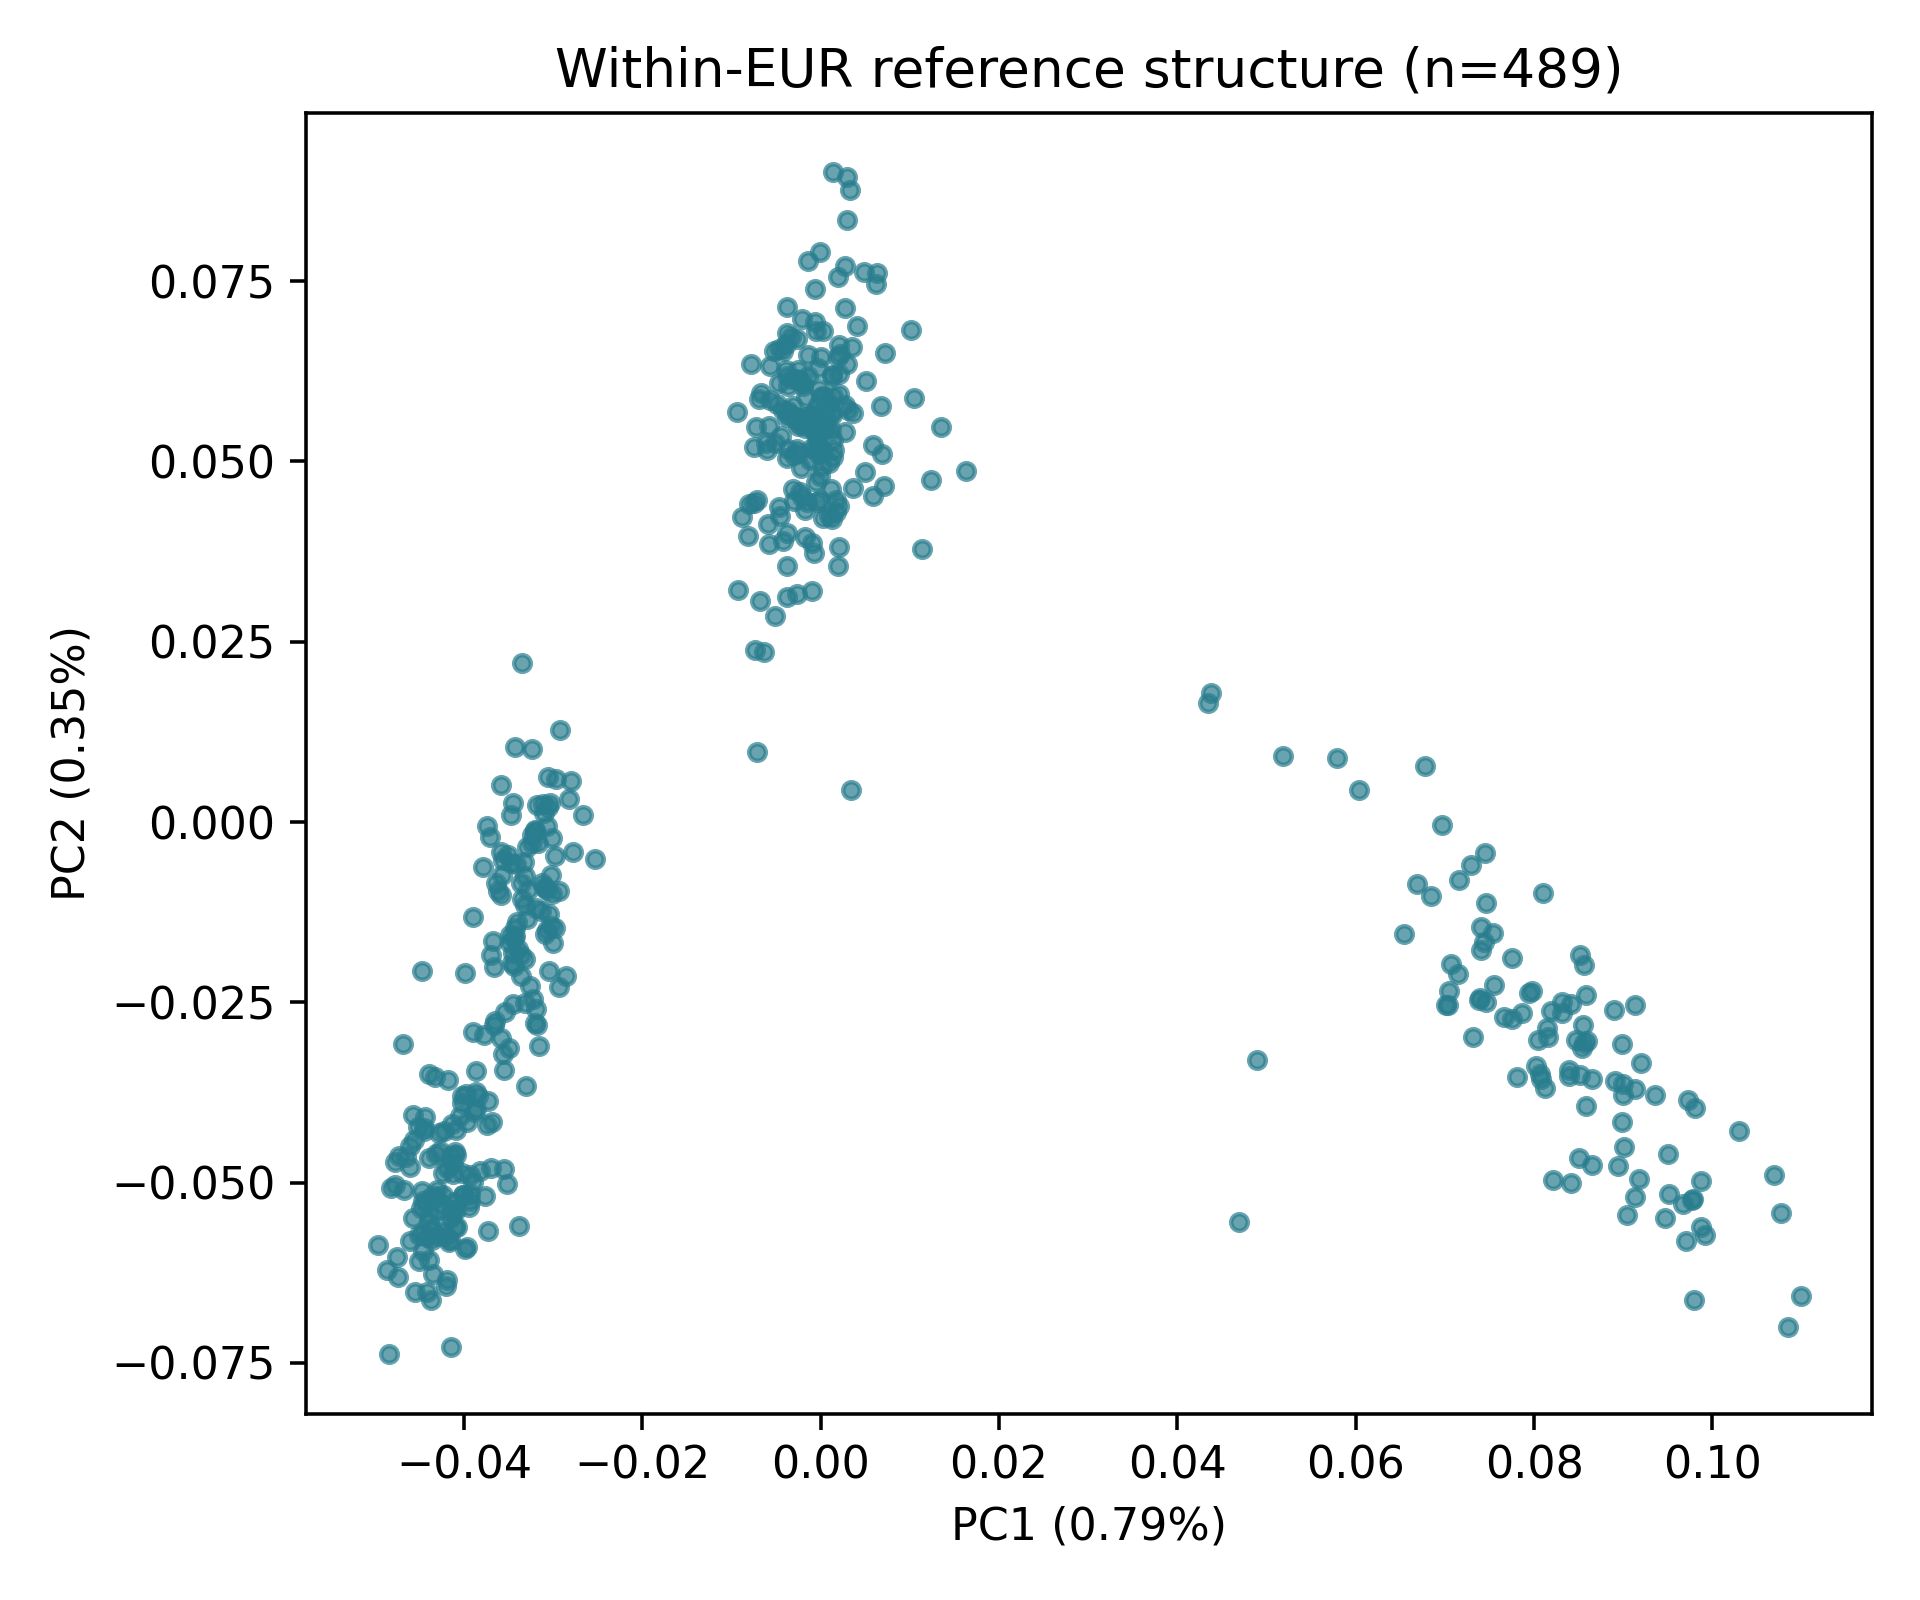

,Disease,PC,Individuals,Pearson_R,P
0,Rheumatoid arthritis,PC1,489,0.3140,0.0000
1,Rheumatoid arthritis,PC2,489,0.0780,0.0848
2,Type 2 diabetes,PC1,489,-0.0648,0.1526
3,Type 2 diabetes,PC2,489,0.0067,0.8833
4,Schizophrenia,PC1,489,0.1839,0.0000
5,Schizophrenia,PC2,489,-0.2052,0.0000


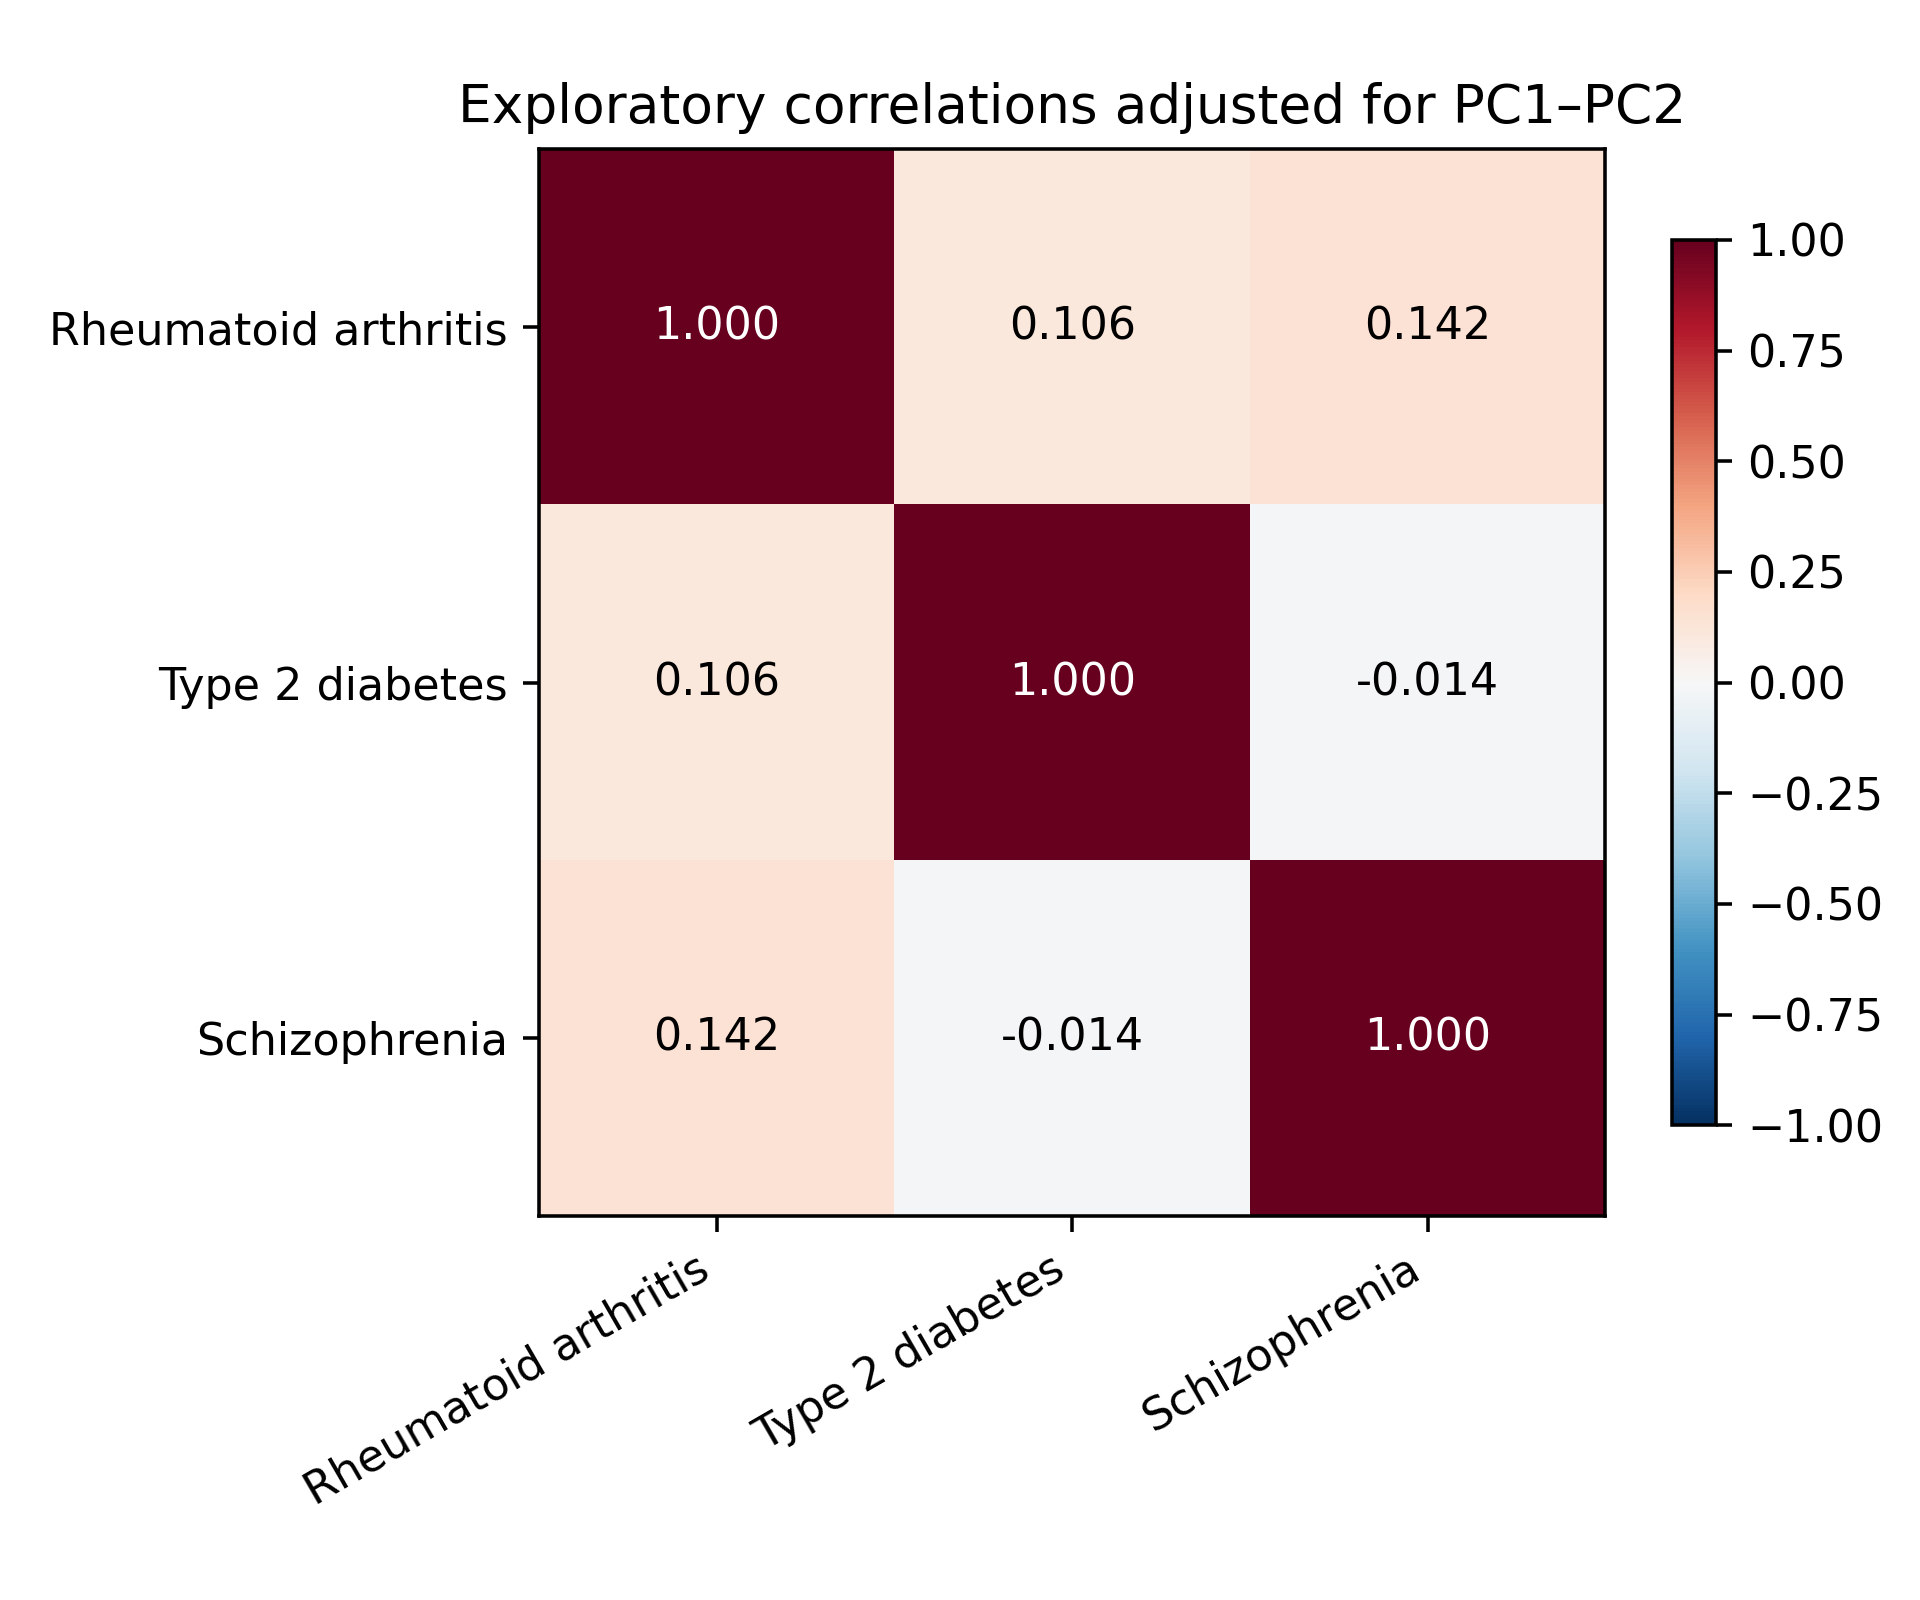

In [3]:
display(Image(filename=str(part2 / 'pca/reference_PCA.png'), width=800))
display(pd.read_csv(part2 / 'prs_pc_associations.tsv', sep='\t').round(4))
display(Image(filename=str(part2 / 'figures/prs_pc_adjusted_correlations.png'), width=800))

## Part 2: Disease PRS Exploratory Analysis — Thresholds and eQTL Overlap

The earlier three-disease correlations, shared-SNP results and LD-pruned PCA are retained.
Disease weights come from published GWASs; they are separate from the newly estimated
expression-prediction betas. This extension uses **public reference people only** and does
not alter Tiffany's primary results.

### Fixed-threshold sensitivity

P+T scores were calculated at the five predefined cutoffs. The heatmaps compare reference
rankings between thresholds using Spearman correlations. No threshold was selected to
make a target person's rank high or low. The primary p≤0.001 SNP sets/scores reproduce
the previous analysis. Rank stability does not identify a clinically optimal threshold.

,Disease,Threshold,Scoring_SNPs,Reference_N,Primary
0,Rheumatoid arthritis,1.00000,17458,489,False
1,Rheumatoid arthritis,0.05000,1996,489,False
2,Rheumatoid arthritis,0.01000,685,489,False
3,Rheumatoid arthritis,0.00100,229,489,True
4,Rheumatoid arthritis,0.00001,93,489,False
5,Type 2 diabetes,1.00000,12829,489,False
6,Type 2 diabetes,0.05000,1416,489,False
7,Type 2 diabetes,0.01000,590,489,False
8,Type 2 diabetes,0.00100,250,489,True
9,Type 2 diabetes,0.00001,88,489,False


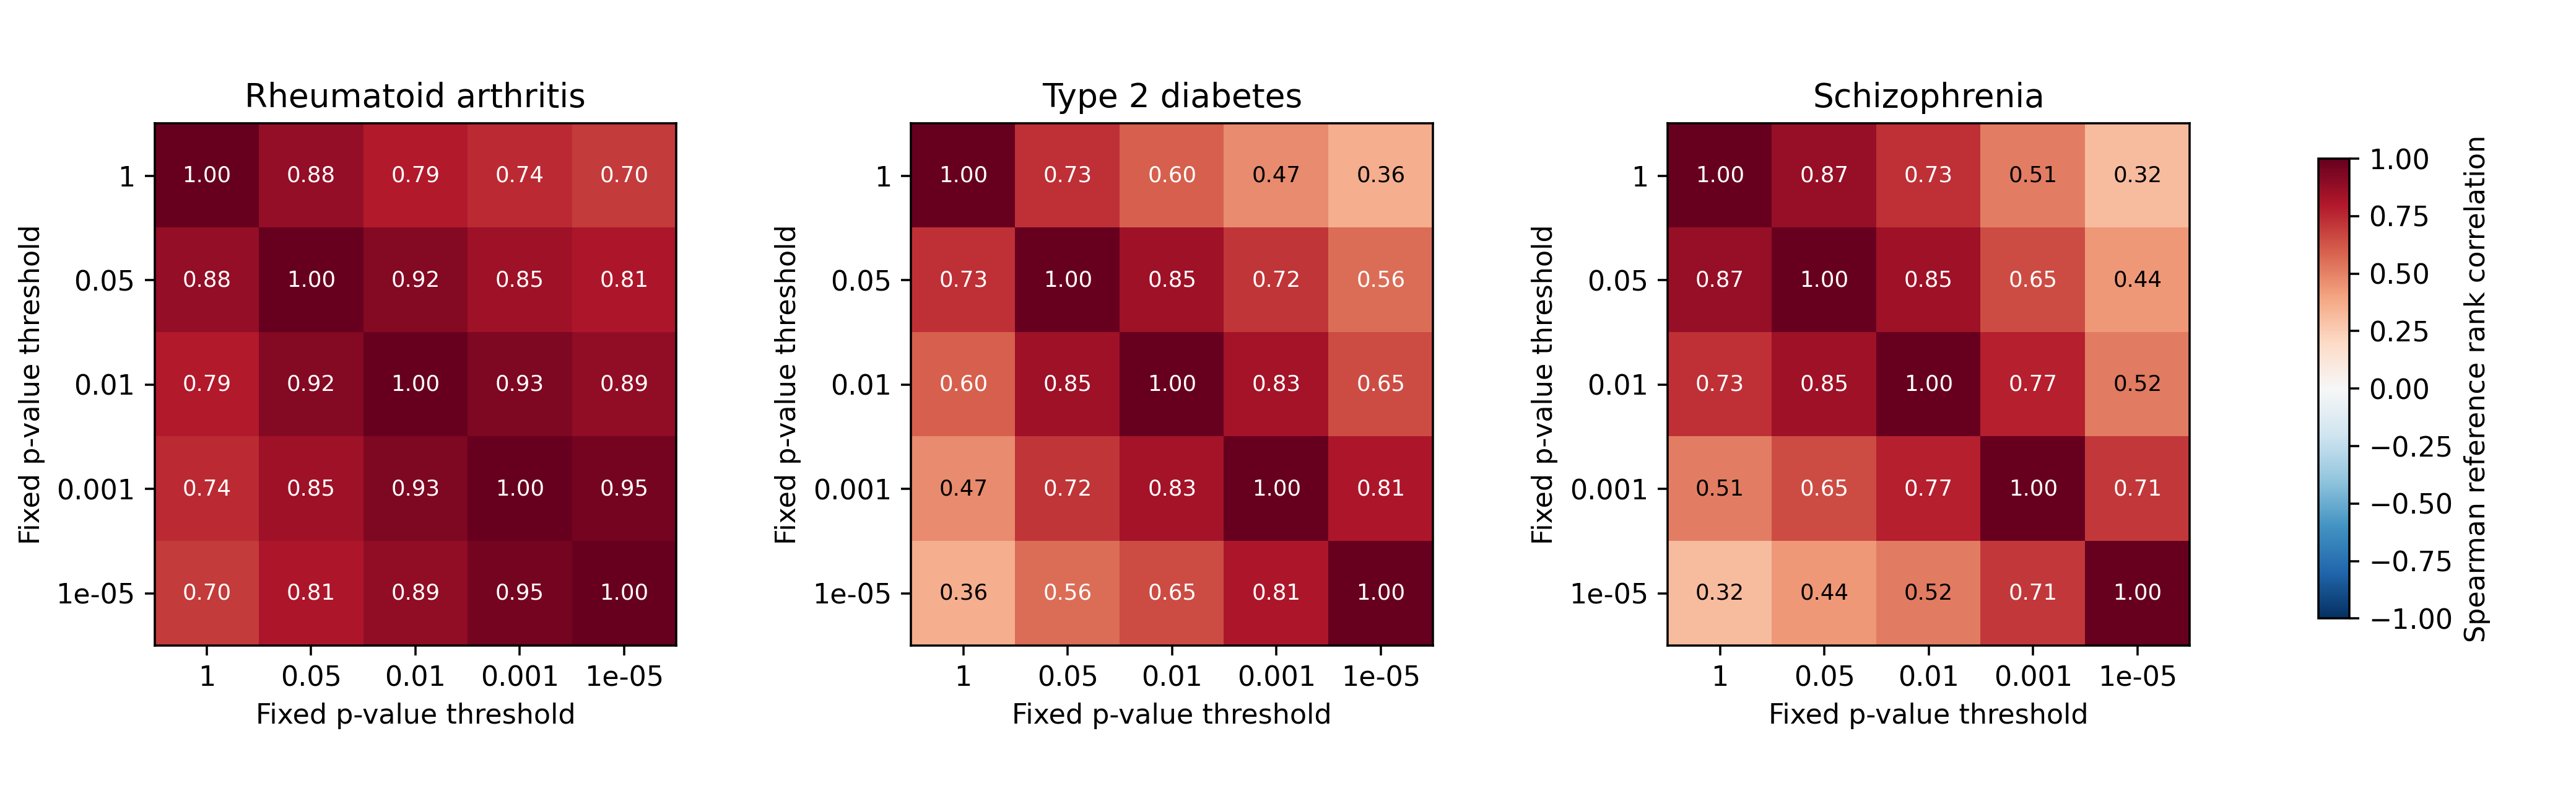

In [7]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
research_root = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
prediction_root = research_root / 'results/expression_prediction'
pilot = prediction_root / 'pilot150_v2'
prs_exploration = research_root / 'results/part2/exploration'
display(pd.read_csv(prs_exploration / 'threshold_summary.tsv', sep='	')
        [['Disease', 'Threshold', 'Scoring_SNPs', 'Reference_N', 'Primary']])
display(Image(filename=str(prs_exploration / 'figures/threshold_rank_stability.png'), width=1100))

### Do disease-scoring SNPs also appear in significant cis-eQTL associations?

The table distinguishes unique SNPs from SNP–gene pairs. Percentages use scoring SNPs
that were actually tested for eQTLs. The comparison background is the disease GWAS's
harmonized variants that were tested for eQTLs. Untested SNPs are not evidence of no effect.

Selected score SNPs were LD-clumped while the background was not; LD, gene coverage,
array ascertainment and local density can influence overlap. These are descriptive
variant intersections, **not formal colocalization or evidence of causal pleiotropy**.

,Disease,Score_SNPs,Score_SNPs_Tested_For_eQTL,Score_BH_eQTL_SNPs,Score_Bonferroni_eQTL_SNPs,BH_Pairs,Bonferroni_Pairs,Score_BH_Percent_Of_Tested,Background_BH_Percent
0,Rheumatoid arthritis,229,221,62,20,109,26,28.054,15.534
1,Type 2 diabetes,250,240,47,12,66,14,19.583,15.020
2,Schizophrenia,3556,3032,323,70,450,82,10.653,8.157


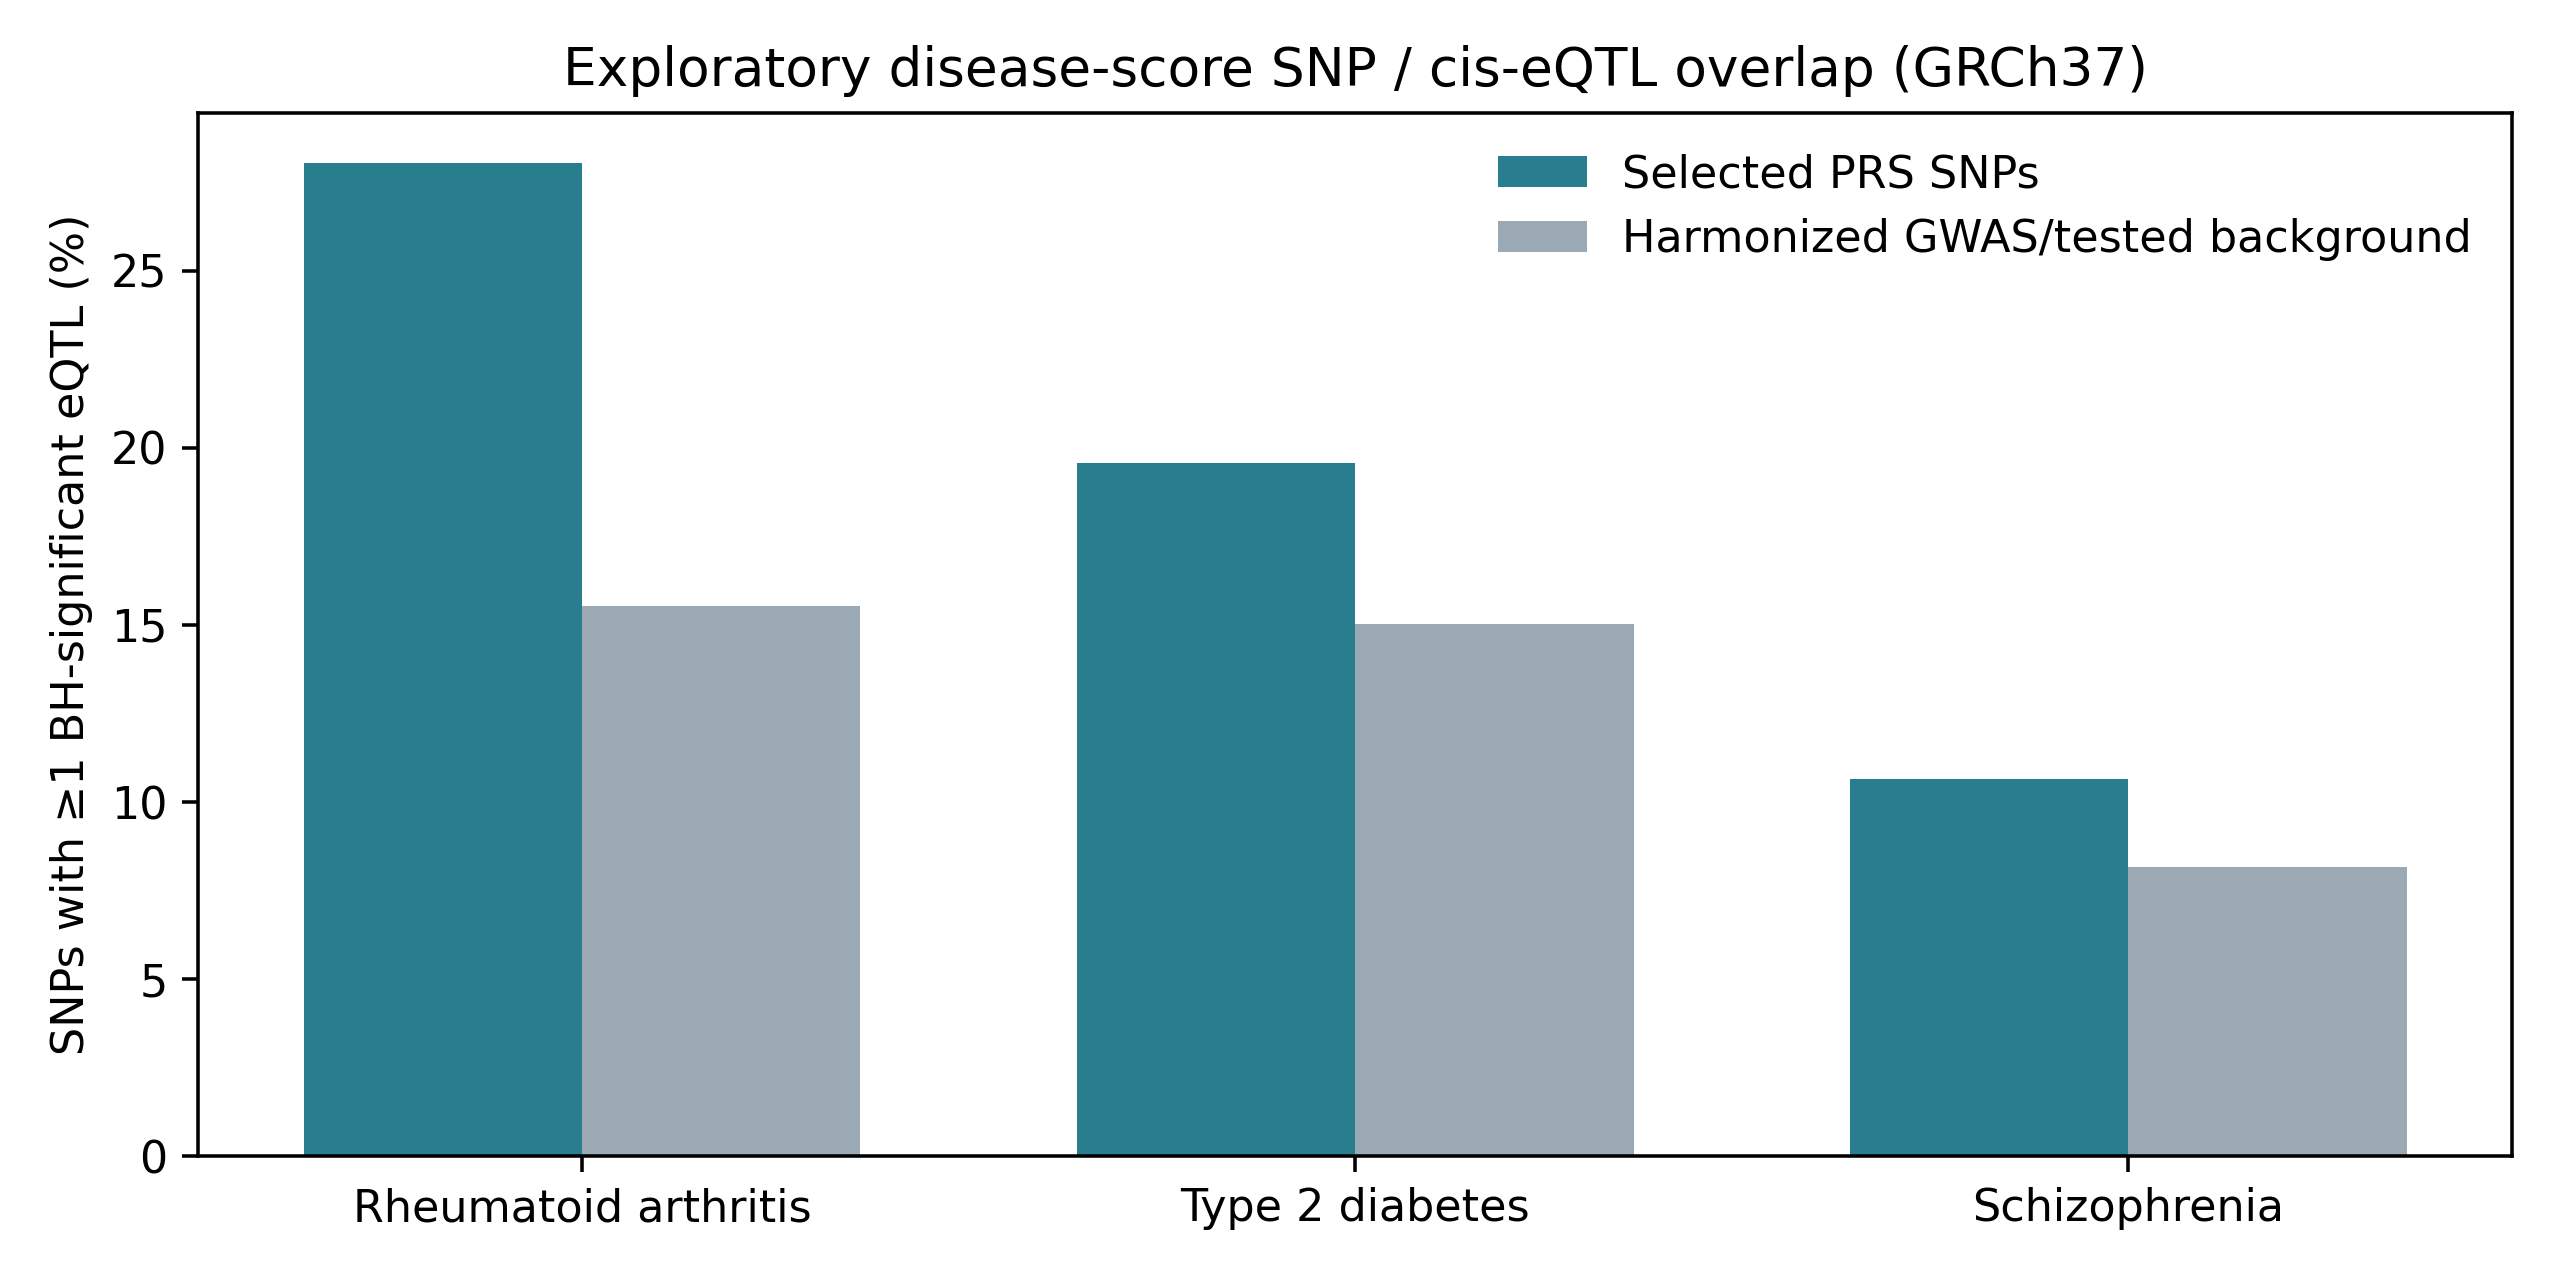

In [8]:
score_eqtl_overlap = pd.read_csv(prs_exploration / 'disease_eqtl_overlap.tsv', sep='	')
display(score_eqtl_overlap[['Disease', 'Score_SNPs', 'Score_SNPs_Tested_For_eQTL',
    'Score_BH_eQTL_SNPs', 'Score_Bonferroni_eQTL_SNPs', 'BH_Pairs', 'Bonferroni_Pairs',
    'Score_BH_Percent_Of_Tested', 'Background_BH_Percent']].round(3))
display(Image(filename=str(prs_exploration / 'figures/disease_eqtl_overlap.png'), width=950))

## Functional Annotation of cis-eQTLs Using ENCODE ATAC-seq

Accessible chromatin is DNA available for regulatory protein binding. ATAC-seq measures
transposase-accessible regions. [Roadmap Epigenomics (2015)](https://pubmed.ncbi.nlm.nih.gov/25693563/)
and [ENCODE (2020)](https://www.nature.com/articles/s41586-020-2493-4) provide the motivation
for annotating association signals with cell-context epigenomic measurements.

ENCFF421XIL (ENCSR603LVR) contains primary B-cell ATAC-seq peaks. B cells are relevant
to B-cell-derived LCL expression, but primary B cells and EBV-transformed LCLs are distinct
experimental contexts. The original BED6+4 peaks use GRCh38. We verify the official
uncompressed checksum, then use UCSC liftOver to GRCh37 before comparing with Part 1.

A one-based SNP p overlaps a BED interval [start,end) when start≤p−1<end. We separately
count unique SNPs and SNP–gene associations for all tested, BH-significant, and
Bonferroni-significant associations. GENCODE v12 gene-body and gene-body ±500 kb window
overlaps are separate annotations; the gene denominator includes unexpressed genes.

The case studies are the four strongest Part 1 genes, selected regardless of overlap.
RPS26's lead-SNP result and the negative findings for other lead SNPs are reported below.
Overlap is evidence of genomic co-location, not a causal variant or regulatory connection.
Differences in overlap percentages are descriptive; no formal enrichment claim is made.
Run `python scripts/run_week7.py` to reproduce this section from saved Part 1 associations.

Peaks: 100,655 original; 100,364 lifted; 291 lost
snp_overlap_summary.tsv


,Set,Unique_SNPs,Overlapping_SNPs,Percent,SNP_Gene_Pairs,Overlapping_Pairs
0,All tested,1001779,16118,1.608938,6597508,185689
1,BH significant,80939,3027,3.739853,101916,4003
2,Bonferroni significant,18136,868,4.786061,20172,983


case_studies.tsv


,Gene_ID,Gene,Lead_SNP,Lead_P,Lead_Overlaps,BH_SNPs_Overlapping,Bonferroni_SNPs_Overlapping,Body_Peaks,Cis_Window_Peaks
0,ENSG00000164308.12,ERAP2,rs2762,1.642397e-109,False,8,8,9,58
1,ENSG00000166796.7,LDHC,rs4757650,1.112289e-114,False,5,5,1,51
2,ENSG00000197728.5,RPS26,rs10876864,4.938813e-137,True,9,7,2,129
3,ENSG00000182534.7,MXRA7,rs9303003,1.069619e-100,False,2,2,4,130


,Annotated_genes,Gene_body_overlap,Cis_window_overlap
0,19189,14733,19008


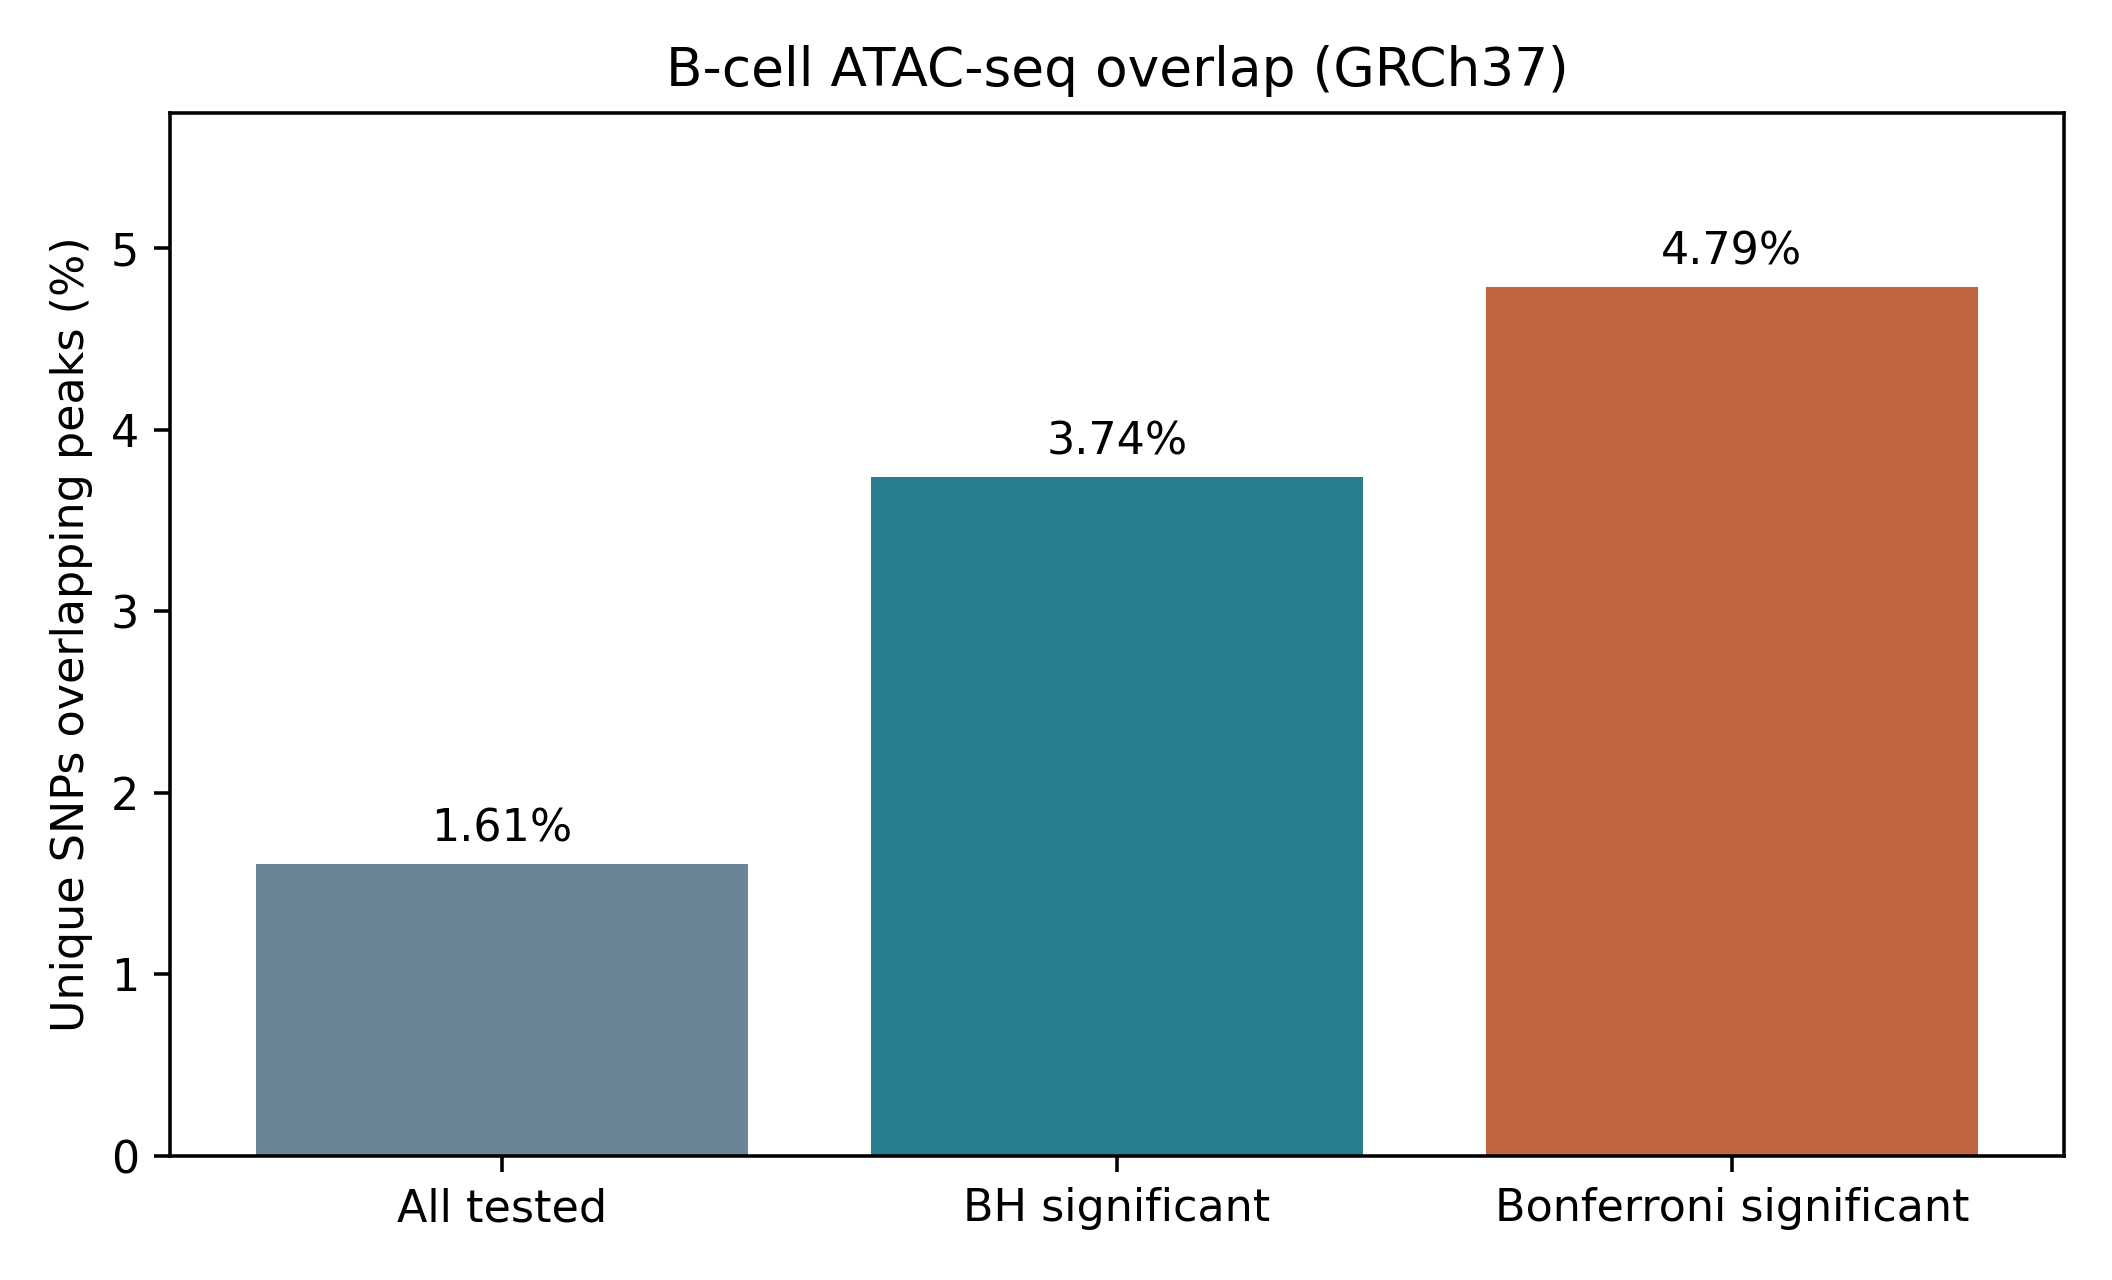

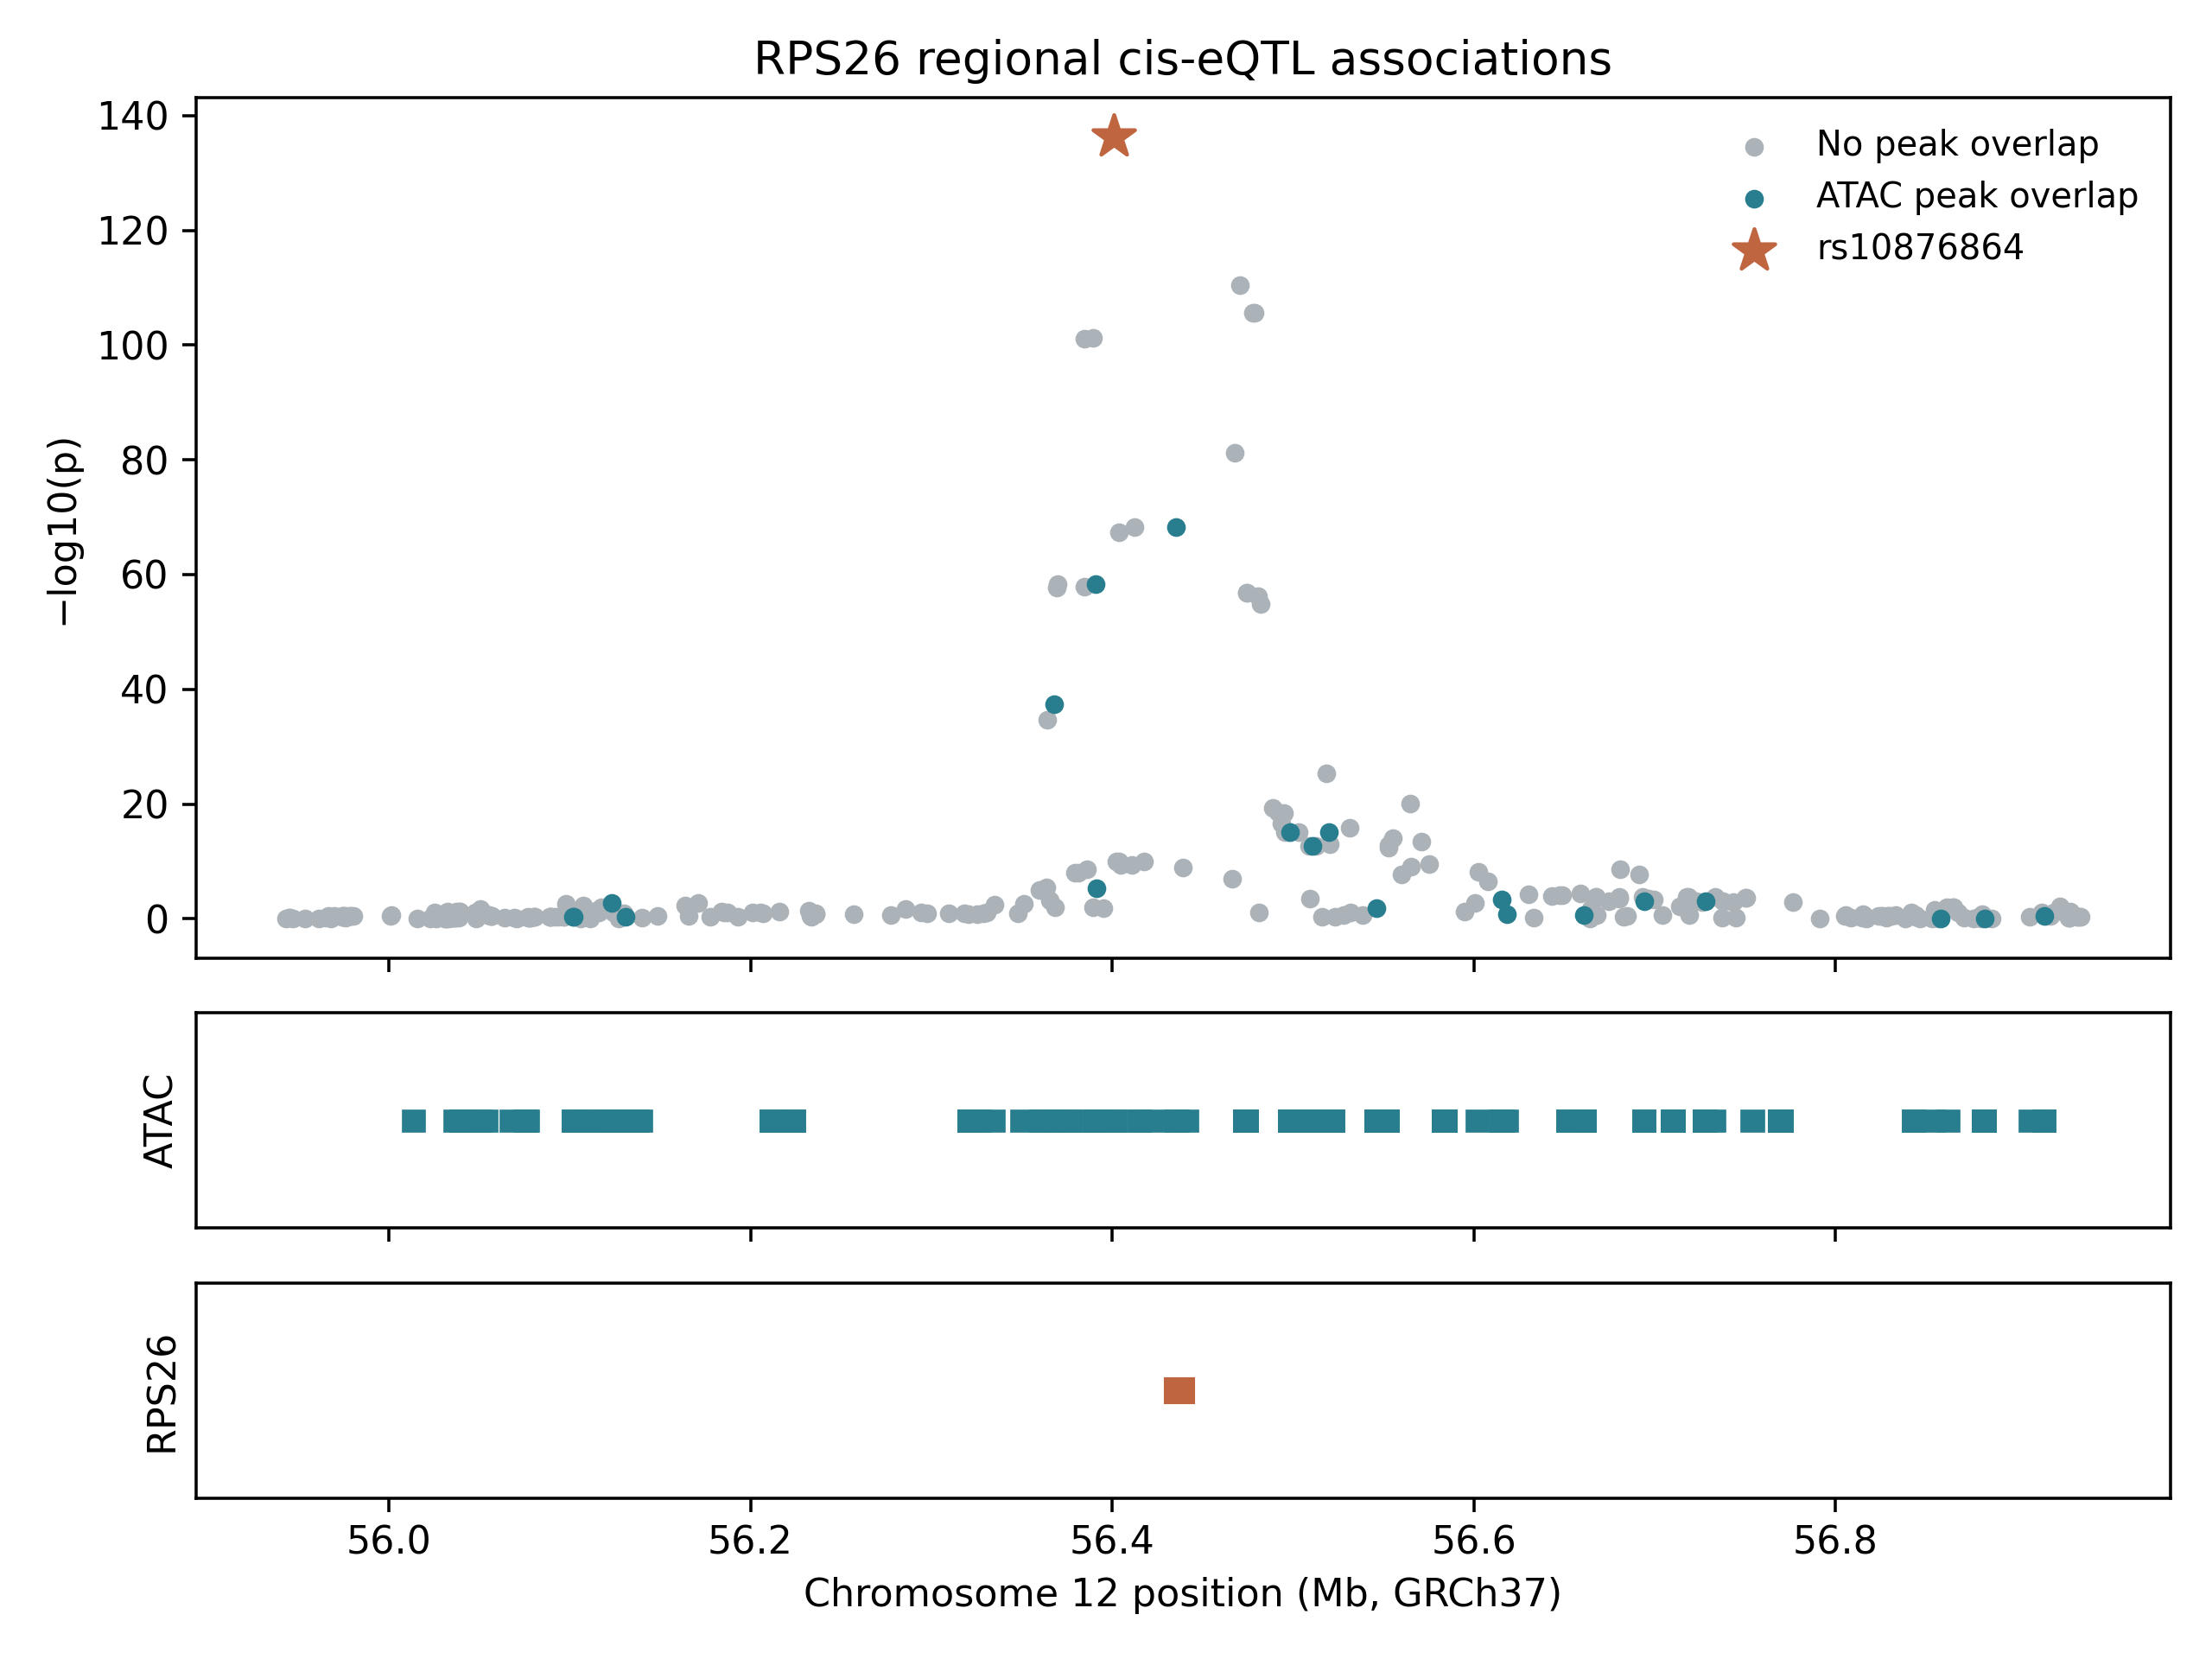

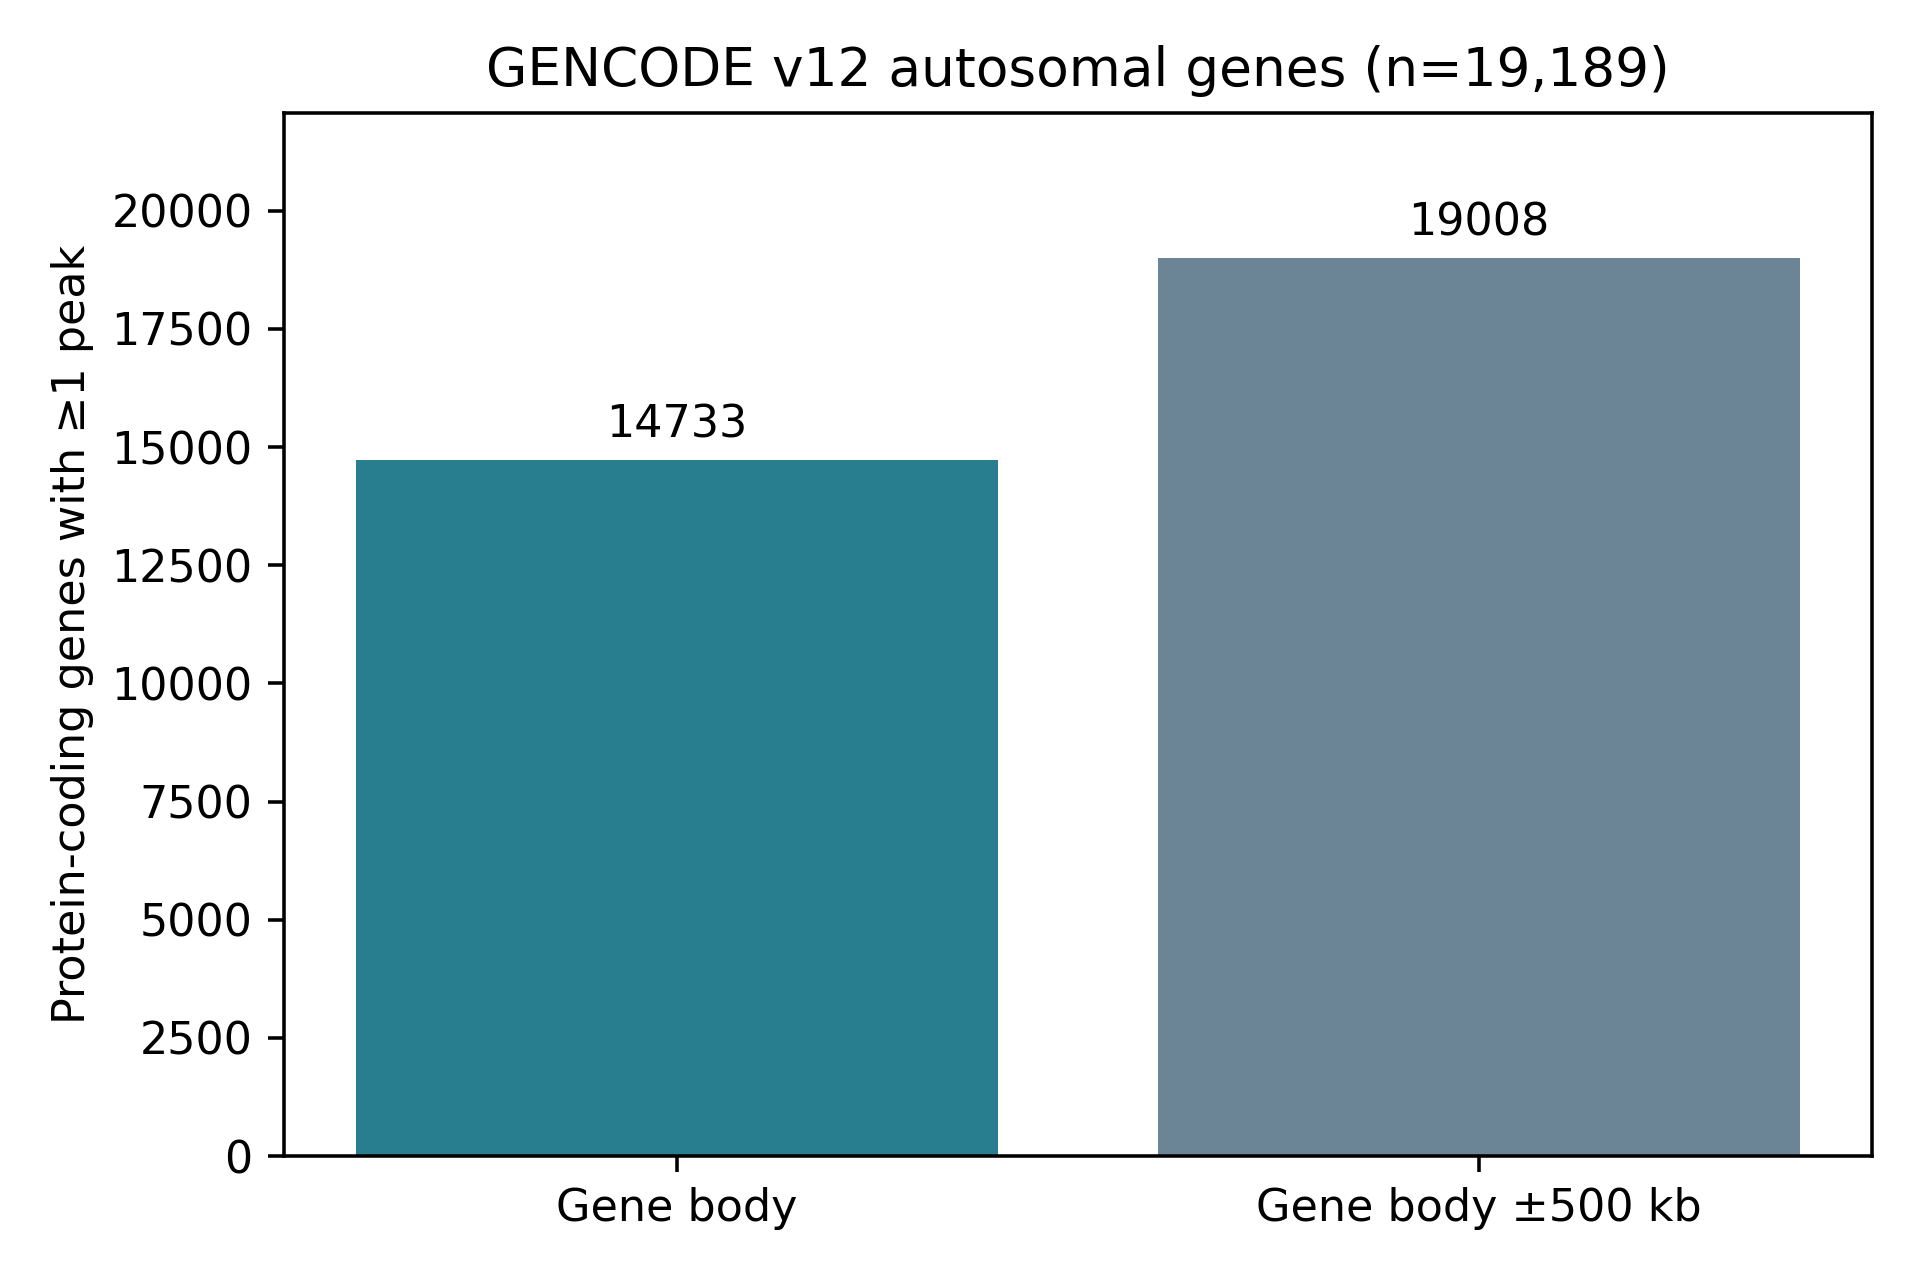

In [16]:
import json
week7 = report_root / 'results/week7'
if (week7 / 'provenance.json').exists():
    provenance = json.loads((week7 / 'provenance.json').read_text())
    print(f"Peaks: {provenance['Input_Peaks']:,} original; {provenance['Mapped_Peaks']:,} lifted; {provenance['Lost_Peaks']:,} lost")
    for name in ['snp_overlap_summary.tsv', 'case_studies.tsv']:
        print(name)
        display(pd.read_csv(week7 / name, sep='\t'))
    annotation = pd.read_csv(week7 / 'gene_annotation.tsv', sep='\t')
    display(pd.DataFrame({'Annotated_genes': [len(annotation)],
                          'Gene_body_overlap': [int(annotation.Body_Peaks.gt(0).sum())],
                          'Cis_window_overlap': [int(annotation.Cis_Window_Peaks.gt(0).sum())]}))
    for name in ['A_snp_overlap.png', 'B_RPS26_accessibility.png', 'C_gene_overlap.png']:
        display(Image(filename=str(week7 / 'figures' / name), width=760))
else:
    print('Run scripts/fetch_part2_week7.py and scripts/run_week7.py first.')

## Paper Figures — One Folder for LaTeX

Use **`results/paper_figures_public/`** for this notebook. This public collection contains reference-only figures.

The following cell refreshes existing figure copies, captions, source inventory and LaTeX examples without rerunning analyses.

Expanded prediction and PRS figures are included. The complete local handoff is also copied to `paper/figures/`.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
report_root = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
if str(report_root) not in sys.path:
    sys.path.insert(0, str(report_root))
part2 = report_root / 'results/part2'
from scripts.export_paper_figures import export_paper_figures
paper_collection = export_paper_figures(include_private=False)
print(paper_collection)

{'Distinct_Figures': 25, 'Figure_Files': 43, 'Folder': 'results/paper_figures_public/'}
